# Model 1: how it trains, where its gradient goes, and whether it can learn a small process

**Model 1** (`model_1.py`) is the hybrid of this folder trained on one loss: the cross-entropy of the GRU's
predictions of the future tokens. A Transformer reads the history and picks one state from a shared table of state
vectors; the GRU starts from that state (the code calls it *the handoff*, and table columns named `handoff_…` describe
it) and steps through the real future tokens, picking a state from
the same table at each step; every picked state predicts the next token through one shared output layer. The
Transformer gets no loss of its own: it is trained only through the state it hands to the GRU.

On renewal-15 (15 causal states), model 1's GRU learned most of the counts on one seed of three and ended with a single
state on the other two (walkthrough section 6.1); in the original setup of section 13 it ended with a single state on
all three seeds. This notebook asks why, in three steps, and then asks two more questions:

1. **How model 1 turns its training data into a loss** (section 2), so that every later measurement can be placed in
   that sequence of steps.
2. **Does the gradient of the GRU's loss reach the Transformer and train it?** (section 4, on the renewal-15 runs). It
   seemed that it might not.
3. **Can model 1 learn the coin, a process with only two states** (section 5)? If it could not, something more basic
   than renewal-15's size would be wrong. Section 5 also searches the training settings (learning rate, Adam's two
   momentum terms, SGD with and without momentum, weight decay, clipping, the temperature, the noise in the choice,
   the LayerNorm, the start of the state table, the batch size, the table's size and the number of future tokens) to
   see what model 1's success on the coin depends on. As an addition, it tries the even process: also two states, but
   its state cannot be read off the last token, so the model has to carry it.
4. **With the best training settings, can model 1 learn renewal-15, and the larger renewal-30 and renewal-60?**
   (section 6). Section 5's search cannot choose these settings, because on the coin nearly everything works; so the
   search is repeated on renewal-15, and the best settings found train model 1 on the three processes.
5. **Can model 1 learn renewal-30 with more updates, or with settings chosen on renewal-30 itself?** (section 7).

**Structure.** 1 setup; 2 how model 1 trains, step by step; 3 its results on renewal-15 (the runs of section 16 and
the original setup); 4 the gradient check; 5 the coin (the process, the plan, section 16's settings and three
reference models, the search, where the remaining error comes from, 50,000-update runs, the even process, findings);
6 renewal-15, -30 and -60 with the best settings (the processes, a pilot, the search on renewal-15 one change at a
time, then two changes together, the best settings on the three processes, gradient and loss over training, the
Transformer's choice, the starting points, findings);
7 renewal-30 with more updates and its own search (section 6's settings for 150,000 updates, the search one change
at a time, then two changes together, the best renewal-30 settings, those settings for 150,000 updates, findings);
8 summary.

**Files.** `model_1_checks.py` holds section 4's measurements (cached in `runs/model_1_checks/`); `coin_check.py`
defines, trains and reads section 5's runs (saved in `runs/coin_check/`); `renewal_check.py` section 6's (saved in
`runs/renewal_check/`). Nothing is trained when this notebook runs:
it reads the saved runs and the cached measurements.

**Terms used throughout**
* **Excess CE**: a predictor's cross-entropy minus the true process's cross-entropy on the same tokens, in bits per
  token. 0 is perfect.
* **Test windows**: 4,096 fresh windows of 40 history + 20 future tokens that never affect training or any choice
  (in section 6, each process's own window size).
* **Seeds**: each configuration has three runs (seeds 0, 1, 2), which differ in their starting weights and training
  windows.
* **The state-choice layer**: the linear layer that turns a part's output into one number per state (K = 32 numbers,
  "scores"); the state with the highest number is picked. The Transformer has one (`transformer_selector`, 16 numbers
  in, 32 out) and so does the GRU (`gru_selector`). It is not a loss: model 1 has no loss on the Transformer's own
  predictions, but the Transformer still needs this layer to pick the state it hands to the GRU.
* **The choice and q**: in training, random noise is added to the scores and the highest is taken; the gradient is passed back through q = softmax((scores + noise) / τ), as if the part had
  used the q-weighted average of the state vectors. **Fixed choice**: q's largest entry is above 0.999, so almost no
  gradient passes the choice.
* **Information fraction**: I(learned state; true state) / H(true state). 1 when the learned state tells the true
  state exactly, 0 when it tells nothing.

## 1. Setup

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # run this notebook from test_models/

import json
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

import process as P
import training as TR
import analysis as A
import main as MAIN
import model_1_checks as C1
import coin_check as CC

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 90
runs = MAIN.imported_runs()                  # {(model, label, seed): run folder} of sections 13, 16, 17


def runs_of(model, label=None):
    # The imported runs of one model (all seeds; optionally one label such as 'section16' or 'original_setup').
    return {f"{m} {l} s{s}": f for (m, l, s), f in runs.items() if m == model and (label is None or l == label)}


def performance(r, which="latest"):
    # Test results of some runs: each predictor's excess CE over the 20 future tokens and over 200 (long_excess), the
    # true states with a learned state of their own, the size of the GRU's machine, and the handoff's states.
    table = A.test_table(r, which)
    keep = ["seed", "update"] + [c for c in table if c.startswith("excess_") and c.endswith("_future")] \
        + [c for c in table if c.startswith("long_excess_")] + [c for c in table if c.endswith("_true_states_with_own_state")] \
        + [c for c in table if c.endswith("_long_run_states")] + ["handoff_codes"]
    return table[keep].set_index("seed").round(4)


def sci(df, digits=1):
    # A table of small numbers in scientific notation.
    return df.map(lambda v: f"{v:.{digits}e}" if isinstance(v, float) else v)

## 2. How model 1 trains, step by step

One update of model 1 (`training.train` → `training.train_step` → `Model.loss` in `model_1.py`), with section 16's
settings:

1. **Fresh data.** 128 new windows of 60 tokens, each started in a random true state drawn with the process's
   long-run frequencies. No window is used twice. Positions 0–39 are the history, 40–59 the future. The sampler knows
   the true states, but training only sees the tokens.
2. **The Transformer reads each window.** Each token becomes a fixed random vector (not trained) plus a fixed
   sine/cosine pattern for its position; 4 attention layers follow, in which each position sees only itself and
   earlier positions, so the output at position 39 depends only on x_0 … x_39; then a LayerNorm (one of section 16.1's
   three changes); then a linear layer gives a score to each of the 32 states.
3. **The starting state of the GRU.** At position 39 the Transformer picks a state (noise added, highest score taken). Its row of the
   state table is handed to the GRU. All 60 positions are computed, but only position 39 is used.
4. **The GRU steps through the future.** This starting state predicts x_40 through the output layer. Then 19 times: the
   GRU cell takes the current state's vector and the real token, gives a new vector, the GRU's state-choice layer scores the
   32 states, one is picked, and its row predicts the next token. Only the picked row is carried forward, so the GRU's
   whole memory is which of the 32 states it is in.
5. **The loss**: the mean over 128 × 20 predictions of −log₂ P(real token), in bits.
6. **The update.** Backward through q at every choice (the straight-through gradient, Bengio et al. 2013), the gradient's
   length clipped to 1.0, then one AdamW step (learning rate 0.001, weight decay 5e-4; Loshchilov & Hutter 2019).
   The temperature τ falls from 2.5 to 0.5 over the run; it changes q's sharpness, never which state is picked.
7. **Every 500 updates**: the validation measures on 512 fixed windows without noise; the parameters with the best
   GRU excess are kept (`best.pt`).

Which parts the loss trains:

| part | trained by the GRU's loss? |
|---|---|
| output layer, state table | yes, directly |
| GRU cell and its state-choice layer | yes, through the 19 choices it makes |
| Transformer (attention layers, LayerNorm, state-choice layer) | only through its choice of state at position 39 |
| the Transformer's choices at the other 59 positions | no |

The next cell sends four windows through an untrained model 1.

In [2]:
s = TR.settings_for("1", seed=0)                                   # section 16's settings, renewal-15
model = TR.make_model(s)
window = s.process_object().sampler(1).draw(4, s.total_len)        # 4 windows of 40 + 20 tokens
H, L = s.history_len, s.rollout_len
model.train()
scores, sel = model.transformer_pass(window, s.tau_start)
print("tokens:", tuple(window.shape), "| Transformer scores:", tuple(scores.shape),
      "| state given to the GRU in each window:", sel.ids[:, H - 1].tolist())
print("q at position 39 (largest entry per window):", sel.probs[:, H - 1].max(-1).values.detach().numpy().round(3))
loss, terms, _ = model.loss(window, s.tau_start, 0.0)
print("loss: CE of the GRU's 20 predictions per window =", round(loss.item(), 4), "bits per token")

tokens: (4, 60) | Transformer scores: (4, 60, 32) | state given to the GRU in each window: [15, 12, 14, 25]
q at position 39 (largest entry per window): [0.091 0.104 0.095 0.086]
loss: CE of the GRU's 20 predictions per window = 1.0612 bits per token


## 3. Model 1 on renewal-15: the runs of section 16 and the original setup

Renewal-15: after each 1, the number of 0s before the next 1 is equally likely to be any of 0–14; its 15 causal states
are the counts of 0s since the last 1. Always predicting each token's long-run frequency ("remembers nothing") is
0.0549 bits above exact on the test windows; predicting from the last token alone ("last symbol only") is 0.0513.

The figure: the GRU's validation excess over training. The tables: each predictor's test excess at the final
parameters (first) and at the best-validation parameters (second) — *excess_transformer_future* is the Transformer's own
predictions, *excess_gru_from_handoff_future* the GRU started from the Transformer's state, *long_excess* the same over
200 future tokens, *true_states_with_own_state* the true counts that have a learned state of their own,
*long_run_states* the states of the GRU's machine, *handoff_codes* the different states the Transformer gives the GRU;
then when the GRU's validation excess first fell below 0.04, 0.02 and 0.01 bits (empty: never); then the machine each
GRU ends with (read off exactly from its step rule): its states, the true counts it covers, and the mean and largest
|learned − true| of its transition probabilities.

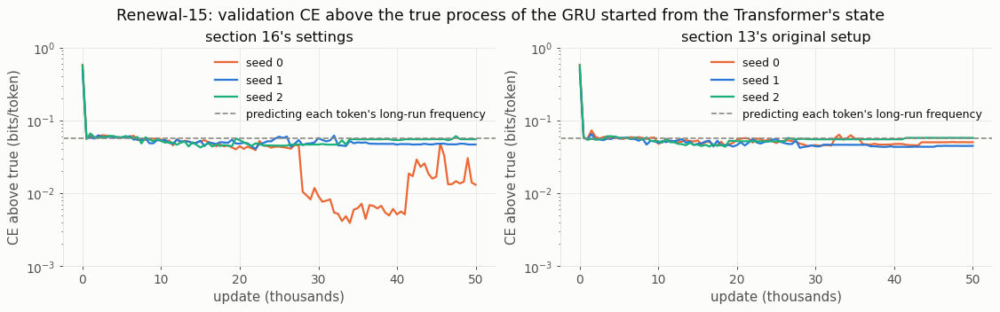

final parameters


,update,excess_transformer_future,excess_gru_from_handoff_future,long_excess_gru_from_handoff,transformer_true_states_with_own_state,gru_from_handoff_true_states_with_own_state,gru_from_handoff_long_run_states,handoff_codes
seed,,,,,,,,
0,50000,0.0663,0.0175,0.0184,2,12,12,7
1,50000,0.1719,0.0453,0.0544,2,1,1,5
2,50000,0.0540,0.0529,0.0548,1,1,1,2


best-validation parameters


,update,excess_transformer_future,excess_gru_from_handoff_future,long_excess_gru_from_handoff,transformer_true_states_with_own_state,gru_from_handoff_true_states_with_own_state,gru_from_handoff_long_run_states,handoff_codes
seed,,,,,,,,
0,34000,0.0611,0.0068,0.0080,2,14,14,14
1,22000,0.0557,0.0401,0.0548,1,2,1,8
2,15000,0.0502,0.0419,0.0588,2,1,1,10


,final_update,best,best_update,below 0.04,below 0.02,below 0.01
seed,,,,,,
0,50000,0.003902,34000,22000.0,28000.0,28500.0
1,50000,0.040605,22000,NaN,NaN,NaN
2,50000,0.042475,15000,NaN,NaN,NaN


,states,covered,mean_error,max_error,test_excess
seed,,,,,
0,12,12,0.0113,0.7500,0.0175
1,1,1,0.1244,0.9333,0.0453
2,1,1,0.1244,0.9333,0.0529


In [3]:
r16 = runs_of("1", "section16")
r13 = runs_of("1", "original_setup")
fig = C1.plot_renewal_curves({"section 16's settings": {f"seed {k[-1]}": f for k, f in r16.items()},
                              "section 13's original setup": {f"seed {k[-1]}": f for k, f in r13.items()}}); plt.show()
print("final parameters"); display(performance(r16))
print("best-validation parameters"); display(performance(r16, "best"))
display(A.first_below(r16).set_index("seed")[["final_update", "best", "best_update", "below 0.04", "below 0.02", "below 0.01"]])
display(A.machine_table(r16).set_index("seed")[["states", "covered", "mean_error", "max_error", "test_excess"]].round(4))

**Section 13's original setup** (no LayerNorm on the Transformer's output, no weight decay, no gradient clipping):

In [4]:
display(performance(r13))
display(A.first_below(r13).set_index("seed")[["final_update", "best", "best_update", "below 0.04", "below 0.02", "below 0.01"]])

,update,excess_transformer_future,excess_gru_from_handoff_future,long_excess_gru_from_handoff,transformer_true_states_with_own_state,gru_from_handoff_true_states_with_own_state,gru_from_handoff_long_run_states,handoff_codes
seed,,,,,,,,
0,50000,0.0490,0.0477,0.0543,2,1,1,2
1,50000,0.3247,0.0417,0.0542,2,1,1,5
2,50000,0.0549,0.0549,0.0549,1,1,1,1


,final_update,best,best_update,below 0.04,below 0.02,below 0.01
seed,,,,,,
0,50000,0.044041,18500,None,None,None
1,50000,0.041959,28000,None,None,None
2,50000,0.043352,18500,None,None,None


**What the runs show**
* **One seed of three learns most of the counts.** Seed 0's GRU ends with 12 long-run states covering 12 true
  states, 0.0175 bits above exact; at its best validation update (34,000) it had 14 states and 0.0068.
* **The others end with one state.** Seeds 1 and 2 end at 0.0453 and 0.0529 bits with a single long-run state: they
  predict about as well as remembering nothing (0.0549). Their best validation values (0.0406, 0.0425) were never
  below 0.04.
* **The original setup never learns the counts**: one long-run state on all three seeds, 0.0417–0.0549 bits.
* **The Transformer's own predictions are untrained** (0.0540–0.1719 bits at the final parameters), as section 2 says.

## 4. Does the GRU's loss train the Transformer?

**The question.** The Transformer is trained only through the state it gives the GRU (section 2). It seemed that the
gradient of the GRU's loss might not reach it at all. In `model_1.py` nothing cuts the gradient between the loss and
the Transformer: the only `detach` is the intended straight-through step in `causal_state_matrix.py`. Whether the
gradient arrives, and whether it changes anything, has to be measured.

**Words used in this section's graphs**
* *Gradient length*: the length (square root of the sum of squares) of the gradient of the loss with respect to a group
  of parameters. "Whole Transformer" = its attention layers, its LayerNorm and its state-choice layer; "whole GRU" =
  the GRU cell and its state-choice layer.
* *At the state vector the Transformer gives the GRU*: the gradient with respect to that 32-number vector (what the
  GRU's loss asks of it).
* *At the Transformer's 32 state scores*: the gradient that is left after the choice step (the straight-through step
  through q), i.e. what reaches the Transformer's state-choice layer and, through it, the rest of the Transformer.
* *Gap between the two highest state scores*: at position 39; in training another state than the highest-scoring one is
  picked with probability about e^(−gap), so above a gap of about 10 the choice stops changing.

### 4.1 At the start the gradient to the Transformer and the GRU is exactly zero

In [5]:
start = C1.gradient_at_start()
cols = ["grad_at_handoff_vector", "grad_after_choice", "grad_encoder", "grad_selector", "grad_gru", "grad_state_table",
        "grad_emission"]
print("all rows of the state table equal at the start:", start["rows_all_equal"])
display(sci(pd.DataFrame({"untrained model 1": start["as_built"],
                          "same, noise of size 0.01 added to the state table": start["table_noise_0.01"]}).loc[cols].T))

all rows of the state table equal at the start: True


,grad_at_handoff_vector,grad_after_choice,grad_encoder,grad_selector,grad_gru,grad_state_table,grad_emission
untrained model 1,3.1e-03,1.2e-12,5.9e-12,4.0e-12,5.7e-12,9.7e-02,1.2e+00
"same, noise of size 0.01 added to the state table",3.1e-03,2.4e-06,7.6e-05,7.3e-05,4.6e-04,9.7e-02,1.2e+00


**Why.** All 32 rows of the state table start equal (`CausalStateMatrix(start="equal")`, so that every state predicts
the same at the start). Then every choice gives the GRU the same vector and the same loss, and nothing tells the
scores which way to move: the gradient after the choice is q_j × (how much state j would change the loss − the
q-weighted average of that), and every term is 0. The gradient at the state vector given to the GRU (3.1e-3) is
normal; the Transformer's state-choice layer and encoder, and the GRU, get about 5e-12, zero up to rounding. Adding
noise of size 0.01 to the table gives them 7e-5 to 5e-4 at once.

### 4.2 Is the starting point flat?
The same measurement at 200 different starting points. A **starting point** is the set of values all of model 1's
weights have before the first update. Seed s gives one such set (torch seed 17 + s): the one a training run with seed s
starts from. Seeds 0–199 give 200 of them, each measured with
the state table as built and with its rows drawn at random; every starting point sees the same 512 windows and the same
noise. Then a direct test of flatness: move the Transformer's and the GRU's parameters by a random step of 0.1%, 1% and
10% of their length and record the largest change of the loss over 20 starting points (same windows and noise before
and after).

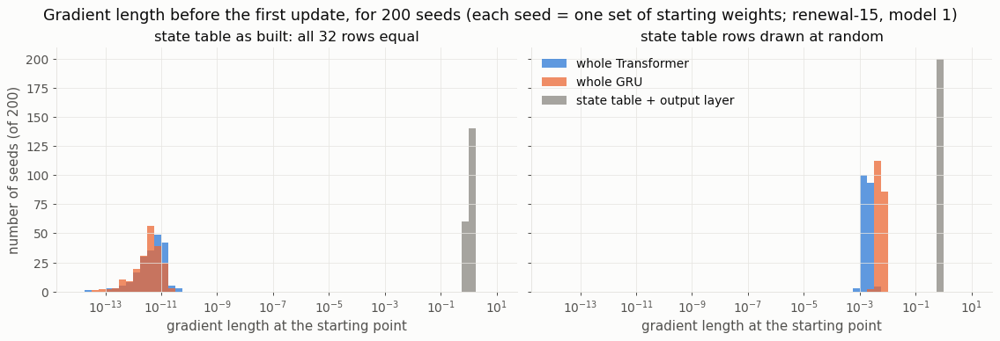

transformer                        gru                   table_output                  
               min   median      max      min   median      max          min   median      max
start                                                                                         
equal      2.7e-14  5.6e-12  5.0e-11  4.4e-14  4.1e-12  2.3e-11      6.5e-01  1.1e+00  1.5e+00
random     7.9e-04  1.7e-03  3.9e-03  2.8e-03  5.5e-03  8.5e-03      6.3e-01  7.7e-01  9.6e-01

step_size,0.001,0.010,0.100
state_table_start,,,
equal,0.0e+00,0.0e+00,0.0e+00
random,4.7e-05,1.3e-04,6.9e-04


In [6]:
starts = C1.start_gradients()
fig = C1.plot_start_gradients(starts); plt.show()
display(starts.groupby("start")[["transformer", "gru", "table_output"]].agg(["min", "median", "max"]).pipe(sci))
display(C1.flatness_at_start().pivot(index="state_table_start", columns="step_size", values="largest_loss_change").pipe(sci))

* **With the state table as built, every starting point is exactly flat for the Transformer and the GRU.** Their
  gradient lengths are at most 5e-11 and 2e-11 over the 200 starting points (zero up to rounding), and moving all
  their parameters by up to 10% changes the loss by exactly 0: with 32 equal rows, whichever state is picked, the
  prediction is the same.
* **It is not a flat point for the whole model.** The state table and the output layer get 0.65–1.47, so the first
  updates move them, the picked rows become different, and the Transformer and the GRU start to receive a gradient
  (4.3).
* **With the rows drawn at random there is no flat start**: the whole Transformer gets 8e-4 to 4e-3 and the whole GRU
  3e-3 to 9e-3 at every starting point, and moving them changes the loss.

### 4.3 The first updates

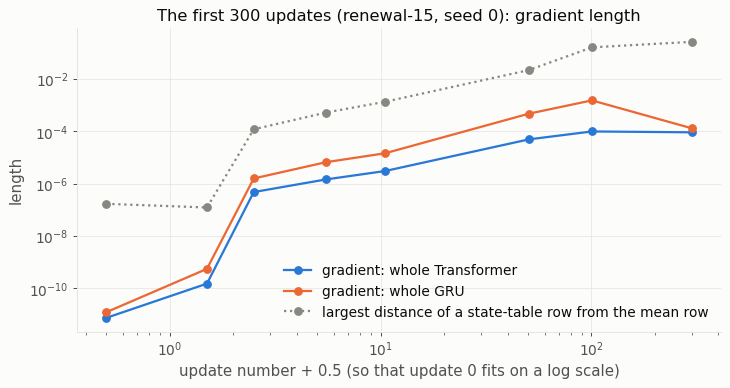

,row_spread,grad_encoder,grad_selector,grad_gru,grad_after_choice
update,,,,,
0,1.7e-07,5.9e-12,4.5e-12,1.2e-11,1.5e-12
1,1.2e-07,1.1e-10,1.0e-10,5.5e-10,3.3e-12
2,1.2e-04,4.0e-07,2.5e-07,1.6e-06,9.4e-09
5,5.2e-04,9.2e-07,1.1e-06,6.6e-06,3.7e-08
10,1.3e-03,1.9e-06,2.3e-06,1.4e-05,8.0e-08
50,2.2e-02,2.1e-05,4.4e-05,4.7e-04,2.3e-06
100,1.6e-01,5.7e-05,8.0e-05,1.5e-03,1.4e-05
300,2.6e-01,5.1e-05,7.6e-05,1.3e-04,1.6e-05


In [7]:
first = pd.DataFrame(C1.first_updates())
fig = C1.plot_first_updates(first); plt.show()
display(sci(first.set_index("update")[["row_spread", "grad_encoder", "grad_selector", "grad_gru", "grad_after_choice"]]))

The gradient reaching the Transformer grows from 6e-12 at update 0 to 4e-7 at update 2 and 6e-5 at update 100, in step
with how far the rows have moved apart. The flat start costs about 100 of 50,000 updates.

### 4.4 The whole training
Each run was trained again from its start with the same settings, data and noise, recording at every update the
training loss and the gradient length reaching the whole Transformer and the whole GRU (before clipping), and every 250
updates the measurements of the choice on a separate stream of windows, with the random-number state restored after
each. The check printed first confirms that the recording did not change training: the final parameters are
identical to the saved run's.

{'s0_section16': 'final parameters identical to the saved run: True', 's1_section16': 'final parameters identical to the saved run: True', 's2_section16': 'final parameters identical to the saved run: True', 's0_original_setup': 'final parameters identical to the saved run: True'}


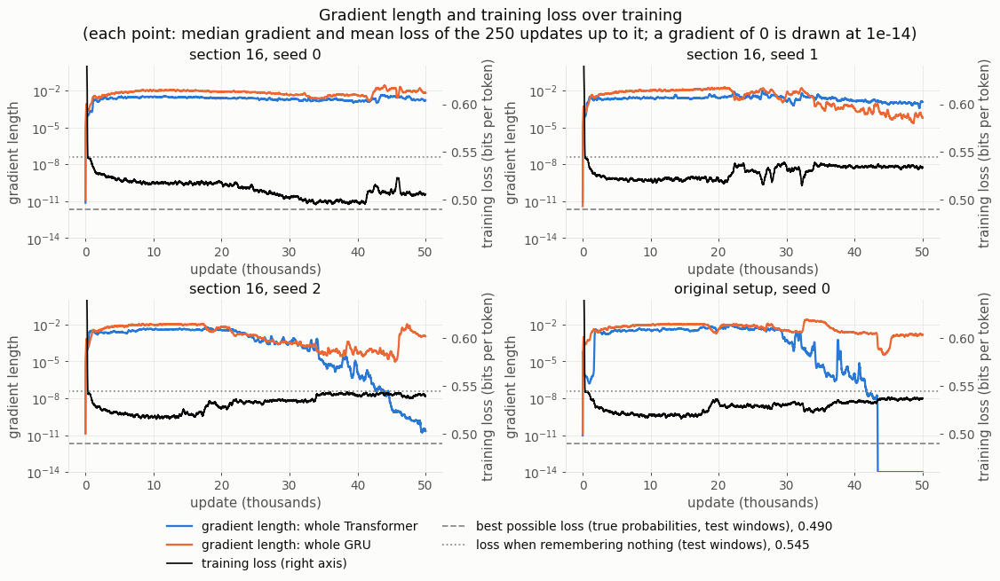

In [8]:
traces = {tag: C1.traced_run(tag, train=False) for tag in C1.RUN_TAGS}     # saved by the runs; nothing trains here
traces = {tag: v for tag, v in traces.items() if v is not None}
print({tag: f"final parameters identical to the saved run: {same}" for tag, (steps, trace, same) in traces.items()})
s15 = TR.read_settings(C1.imported_run("s0_section16"))
_, _, exact15 = A.windows(s15, "test")
best_loss = exact15[:, s15.history_len:].mean()                    # the true process's CE of the 20 future tokens
nothing_loss = best_loss + A.reference_levels(s15, "test")["remembers_nothing"]
if traces:
    fig = C1.plot_whole_training({tag: steps for tag, (steps, trace, same) in traces.items()},
                                 levels={f"best possible loss (true probabilities, test windows), {best_loss:.3f}": best_loss,
                                         f"loss when remembering nothing (test windows), {nothing_loss:.3f}": nothing_loss})
    plt.show()

**What the whole training shows.** The grey lines are measured on the test windows. The best possible loss is 0.490
bits per token: the true process's cross-entropy of the 20 future tokens given the history. A model that remembers
nothing gets 0.545.

* **The start.**
  * At update 1 both gradients are about 1e-11 (the flat start of 4.1–4.3).
  * Both reach 1e-3 between updates 500 and 1,750. In the original setup the Transformer's gradient first dips to
    1.6e-7 near update 950.
  * By update 5,000 both are at 2e-3 to 9e-3.
  * The loss falls from 1.06 bits at update 1 to 0.53–0.54 by update 1,000 (the mean of the 250 updates up to it).
* **Seed 0, the run that learned 12 states**:
  * after update 5,000 both gradients stay between about 1e-3 and 3e-2;
  * its loss is lowest at update 33,900 (0.495, 0.005 above the best possible);
  * it then rises to 0.506 at the end. That end value is 0.016 above best, in line with its test excess of 0.0175 (section 3).
* **Seed 1**:
  * the Transformer's gradient stays near 1e-3;
  * even so, its loss steps up at about update 22,000, from 0.519 to 0.534, and stays close to the "remembers
    nothing" line.
* **Seed 2**:
  * its loss is lowest at update 10,400 (0.515) and rises to 0.540 by update 40,000;
  * the Transformer's gradient (the median over the last 250 updates) is below 1e-4 from update 34,200, below 1e-6 from 41,600 and below 1e-9 from 45,600.
* **The original setup**:
  * its loss is lowest at update 14,500 (0.516) and ends at 0.537;
  * the Transformer's gradient is below 1e-9 from update 43,400 and exactly 0 for the first time at update 43,219;
  * of the 6,782 updates after that, 3,355 give exactly 0 and only 27 (0.4%) give more than 1e-6.
* **The GRU's gradient never dies.** In every run it stays above about 1e-5.

**The order matters.** In seed 2 and the original setup, the loss gets worse 20,000–30,000 updates *before* the
Transformer's gradient dies. So the
vanishing gradient is not what first makes these runs worse (while the loss gets worse the Transformer still receives 3e-3 to 4e-3). It comes later, and from then on the Transformer cannot
change its choice of state.

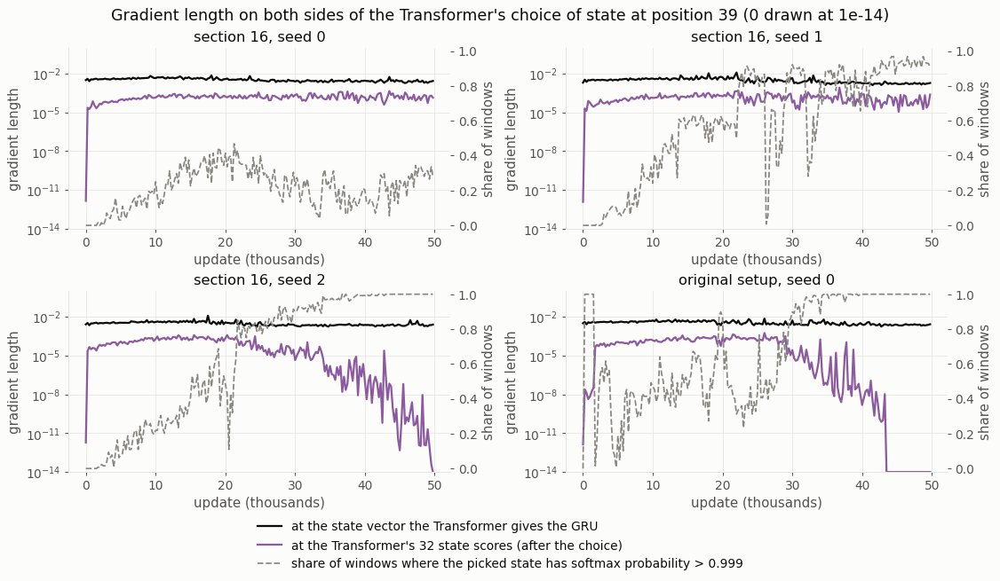

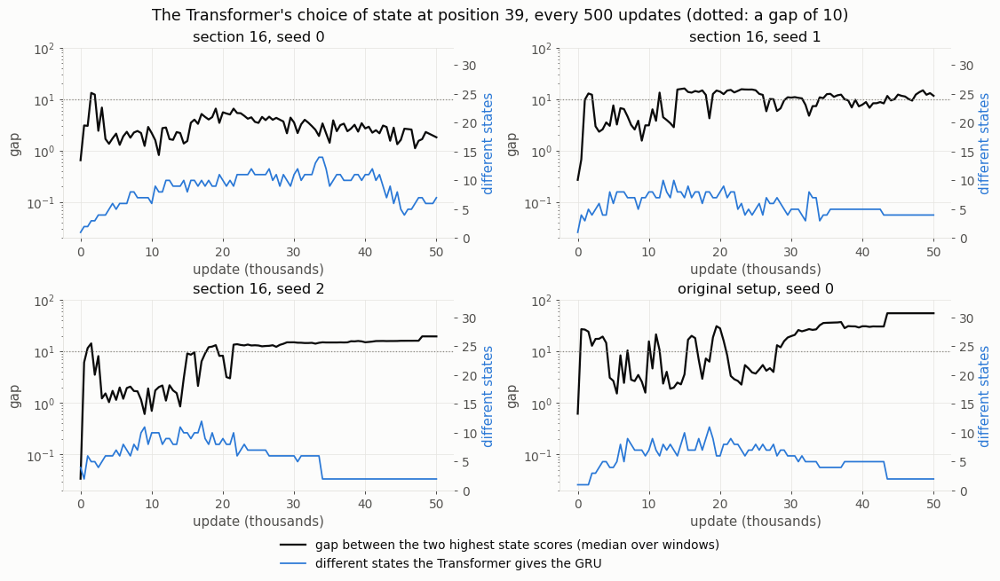

In [9]:
if traces:
    fig = C1.plot_choice_over_training({tag: trace for tag, (steps, trace, same) in traces.items()}); plt.show()
fig = C1.plot_gap_over_training(); plt.show()

**The choice over training** (first figure: measured every 250 updates on separate windows; second: the runs' own
record, every 500 updates).

* **The GRU's loss always asks the Transformer for a different state.** The gradient at the state vector the
  Transformer gives the GRU stays between 1.2e-3 and 1.2e-2 in all four runs for the whole training.
* **How much of it passes the choice depends on how fixed the choice is.**
  * Seed 0: the choice is fixed on at most 47% of windows at any time. After update 5,000 the gradient after the
    choice stays at 4e-5–4e-4, and the recorded gap never stays above 10.
  * Seed 1: the share of fixed choices climbs to 0.92 at update 30,000 and stays at 0.9 or more from 45,000. The
    gradient after the choice is still 1e-5–8e-4 after update 5,000.
  * Seed 2:
    * the recorded gap is above 10 from update 21,500 and the choice is fixed on 90% or more of windows from 34,000;
    * the gradient after the choice falls from 2e-4 (update 20,000) to 4e-6 (30,000), 1e-7 (40,000) and 6e-17 (49,750);
    * it ends giving the GRU only 2 states.
  * The original setup:
    * the gap is above 10 from update 28,000 and the choice is fixed on 90% or more of windows from 34,250;
    * the gradient after the choice falls to 1e-9 at 40,000 and to exactly 0 at the end;
    * it too ends with 2 states.
* So in the two runs that end worst, the choice becomes fixed first, and only then does the gradient after it fall
  to nothing.

### 4.5 The trained runs at their best and final parameters

update handoff_states choice_locked_share grad_at_handoff_vector grad_after_choice grad_encoder handoff_information handoff_information_untrained adam_step_median_encoder  \
run               parameters                                                                                                                                                                                 
s0_section16      best        3.40e+04       2.30e+01            4.69e-01               2.67e-03          1.54e-04     1.61e-03            8.02e-01                      0.00e+00                      nan   
                  final       5.00e+04       9.00e+00            3.10e-01               5.08e-03          1.31e-04     1.36e-03            5.20e-01                      0.00e+00                 4.73e-05   
s1_section16      best        2.20e+04       2.90e+01            7.25e-01               1.63e-02          8.37e-04     8.38e-03            5.35e-01                      0.00e+00                      nan   
                  final       5.00e+04       5.00e+00            9.49e-01               1.78e-03          1.47e-04     9.99e-04            2.29e-01                      0.00e+00                 6.99e-05   
s2_section16      best        1.50e+04       3.10e+01            5.66e-01               3.73e-02          1.92e-03     2.50e-02            5.21e-01                      1.52e-01                      nan   
                  final       5.00e+04       2.00e+00            1.00e+00               2.33e-03          2.66e-10     1.70e-09            5.93e-02                      1.52e-01                 9.99e-09   
s0_original_setup best        1.85e+04       3.10e+01            5.92e-01               2.24e-02          1.49e-03     2.33e-02            5.42e-01                      0.00e+00                      nan   
                  final       5.00e+04       2.00e+00            1.00e+00               2.46e-03          0.00e+00     0.00e+00            1.80e-01                      0.00e+00                 2.58e-24   

                             adam_step_median_gru  
run               parameters                       
s0_section16      best                        nan  
                  final                  8.62e-05  
s1_section16      best                        nan  
                  final                  1.84e-05  
s2_section16      best                        nan  
                  final                  2.93e-05  
s0_original_setup best                        nan  
                  final                  3.51e-05

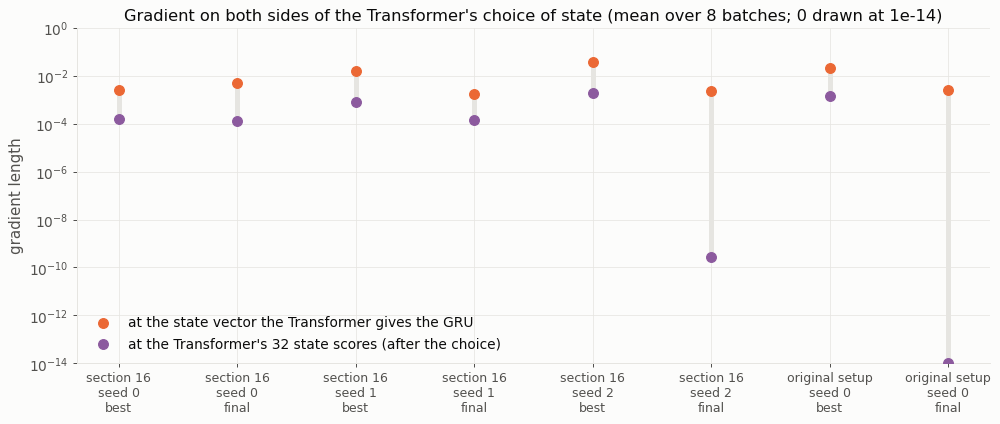

In [10]:
rows = []
for tag in C1.RUN_TAGS:
    for which in ("best", "completed"):
        g = C1.gradient_check(C1.imported_run(tag), which)
        rows.append(dict(run=tag, parameters="best" if which == "best" else "final", **g))
grad = pd.DataFrame(rows)
show = ["run", "parameters", "update", "handoff_states", "choice_locked_share", "grad_at_handoff_vector",
        "grad_after_choice", "grad_encoder", "handoff_information", "handoff_information_untrained",
        "adam_step_median_encoder", "adam_step_median_gru"]
display(sci(grad[show].set_index(["run", "parameters"]).astype(float), 2))
fig = C1.plot_checkpoints(grad); plt.show()

Columns: *handoff_states* = different states the Transformer gives the GRU; *choice_locked_share* = share of windows
where the picked state's q is above 0.999 (a fixed choice); *handoff_information* = information fraction of the state given to the GRU
about the true count (and the same for the untrained model); *adam_step_median_* = the median size of the step Adam
gives each weight, from the saved optimizer state (final parameters only).

* **The GRU's loss always asks for a different starting state.** The gradient at the state vector given to the GRU is
  1.8e-3 to 3.7e-2 in every run and checkpoint.
* **The choice passes 3–8% of it while it is still open, and nothing once it is fixed.** At the best-validation
  parameters, and at the final parameters of seeds 0 and 1, the gradient after the choice is 1.3e-4 to 1.9e-3. At the
  final parameters of seed 2 and the original setup the picked state has q above 0.999 on 100% of windows; the
  gradient after the choice is 2.7e-10 and exactly 0, and the median step Adam gives the encoder's weights is 1e-8
  and 3e-24 (the GRU's weights: 3e-5 and 4e-5). The Transformer is frozen there, giving the GRU one of only 2 states.
* **The state given to the GRU learns part of the count, then loses it.** Its information fraction is 0.52–0.80 at the
  best parameters (untrained: 0 or 0.15) and 0.06–0.52 at the final ones.

### 4.6 The Transformer's vectors learn the count

In [11]:
rows = []
for tag in C1.RUN_TAGS:
    for which in ("best", "completed"):
        rows.append(dict(run=tag, parameters="best" if which == "best" else "final", **C1.encoder_check(C1.imported_run(tag), which)))
enc = pd.DataFrame(rows).set_index(["run", "parameters"])
display(enc.round(3))

update  classifier  classifier_untrained  most_common_share  moved_encoder  moved_transformer_selector  moved_gru_cell
run               parameters                                                                                                                        
s0_section16      best         34000       1.000                 0.483              0.124          1.143                       2.928           7.295
                  final        50000       1.000                 0.483              0.124          1.358                       3.033           7.868
s1_section16      best         22000       0.987                 0.570              0.124          0.965                       2.645           5.994
                  final        50000       0.969                 0.570              0.124          1.275                       2.865           6.914
s2_section16      best         15000       1.000                 0.695              0.124          0.902                       2.412           5.434
                  final        50000       0.974                 0.695              0.124          1.160                       2.707           6.797
s0_original_setup best         18500       0.998                 0.543              0.124          0.910                       1.339           5.730
                  final        50000       1.000                 0.543              0.124          1.163                       1.590           7.014

A linear classifier fitted on the Transformer's output at position 39 (8,192 windows, tested on 4,096 others) reads
the true count with 96.9–100% accuracy in every trained run, against 48–70% for the same Transformer untrained
(always guessing the most common count: 12%). The encoder's weights moved by 0.9–1.4 times their starting length
(*moved_*); weight decay alone would have shrunk them by at most 2.5% over 50,000 updates, so the movement comes from
the GRU's loss, the only loss model 1 has.

### 4.7 What this shows
1. **The gradient of the GRU's loss does reach the Transformer and does train it**: its vectors end up telling the
   count almost perfectly (4.6).
2. **What fails is the choice on top of those vectors.** The Transformer's state-choice layer sorts the histories into
   a few states, and once the gap between its two highest scores is large, q is fixed and no gradient comes back to
   correct it (4.4, 4.5). In two of the four runs the Transformer stops changing altogether.
3. **The start is exactly flat for the Transformer and the GRU** because the state table's rows start equal (4.1–4.3).
   This costs about 100 updates and is not what decides the outcome: the runs that learn and the runs that do not all
   leave it the same way.

The low information of the Transformer's states over all positions (0.006–0.055 in the validation histories) is a
different thing: model 1 never trains the Transformer's choice at any position except 39.

## 5. Can model 1 learn the coin?

### 5.1 The coin
The coin (`process.py`, p = 0.4, q = 0.8) has two causal states and three tokens. From state 0 the next token is 0
(stay, probability 0.6) or 1 (move to state 1, 0.4); from state 1 it is 1 (stay, 0.2) or 2 (move to state 0, 0.8).
The state is fixed by the last token: after a 0 or a 2 the process is in state 0, after a 1 in state 1. So a model
only has to remember the last token, and "last symbol only" is exact.

Three levels to read the results against (test windows, bits per future token):
* **remembers nothing** (0.679): every token predicted with its long-run frequency;
* **best possible when the GRU's starting state tells nothing** (0.034): the true process's CE of the 20 future
  tokens read without their history, minus its CE with the history. On the coin the first future token fixes the
  state, so this is "remembers nothing" on that one token only (0.679 / 20);
* **exact** (0).

,tokens,causal states,C_mu (bits),h (bits per token),E (bits),remembers_nothing,last_symbol_only,handoff_useless
process,,,,,,,,
coin-2,3,2,0.9183,0.8879,0.6777,0.6794,0.0,0.0339


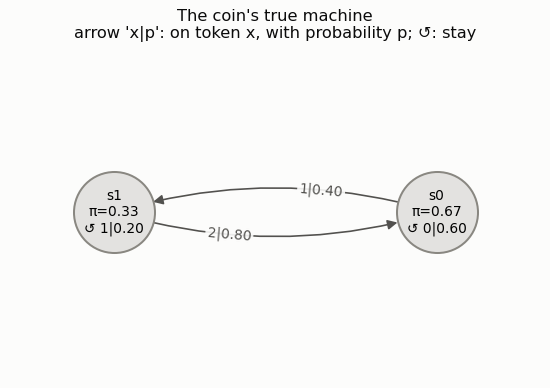

In [12]:
coin = CC.settings_of("default", 0, CC.SEARCH_STEPS)
proc = coin.process_object()
a = proc.analytics()
display(pd.DataFrame([{"process": proc.label, "tokens": proc.vocab_size, "causal states": a["n_causal"],
                       "C_mu (bits)": a["statistical_c"], "h (bits per token)": a["entropy_rate"],
                       "E (bits)": a["excess_entropy"], **{k: round(v, 4) + 0.0 for k, v in CC.levels().items()}}]).set_index("process").round(4))
C1.style()
fig, ax = plt.subplots(figsize=(6, 4.2), layout="constrained")
C1.draw_machine(ax, A.true_machine(coin), coin, "#898781",
                title="The coin's true machine\narrow 'x|p': on token x, with probability p; ↺: stay")
plt.show()

### 5.2 The plan

Every run is model 1 with section 16's settings on the coin, except for the one change its configuration names; three
seeds each; 10,000 updates (the temperature schedule laid over the run), except batch 512 with 2,500 updates, which
sees the same 1.28 million windows. The changes:

* **Learning rate** (section 16: 0.001): 0.0001, 0.0003, 0.003, 0.01.
* **Adam's beta1**: the share of the previous average gradient kept at each update (the momentum; 0.9): 0, 0.5, 0.99.
* **Adam's beta2**: the same for the average squared gradient, which sets each weight's step size (0.999): 0.99,
  0.9999.
* **Learning rate and beta1 together**: learning rates 0.0003 and 0.003, each with beta1 0, 0.5 and 0.99.
* **SGD instead of AdamW**:
  * no momentum, learning rate 0.3;
  * momentum 0.9 at learning rate 0.03 and at 0.3;
  * added after the first SGD results: no momentum, learning rate 0.3, no weight decay, with the state table as built
    and with its rows drawn at random.
* **Weight decay** (5e-4): 0 and 0.005.
* **Gradient clipping** (the gradient's length clipped to 1): off.
* **Temperature τ** (2.5 falling to 0.5): 1 throughout; 2.5 to 0.1; 5 to 1.
* **No random noise in the choice of state**: the highest score is taken without noise in training too.
* **No LayerNorm on the Transformer's output.**
* **State-table rows start at random** instead of all equal.
* **Section 13's original setup**: no LayerNorm, weight decay or clipping.
* **Batch size** (128 windows): 32; and 512 with 2,500 updates.
* **Rows of the state table, K** (32): 4.
* **Future tokens per window, L** (20): 2 and 5.


Some changes are not settings of `training.py` (Adam's beta1 and beta2, SGD, a random state-table start); `coin_check.py`
makes them by giving `training.train` its own optimizer or starting model and changes nothing else. The next cell
checks that the default configuration gives exactly the parameters of `training.train` (60 updates, in a temporary
folder), and lists every configuration.

**What is measured** (`coin_check.diagnose`, on the test windows with 40 + 20 tokens for every run, whatever its own L):
the excess over the 20 future tokens, on the first one (predicted by the state the Transformer gives the GRU) and on
the other 19 (the GRU's steps); the different states the Transformer gives the GRU and their information fraction; the GRU's states; the machine the GRU defines; the
gradient measurements of section 4.5; and the same at the best-validation parameters.

The runs were launched with `python coin_check.py run --stage pilot --workers 6` (the first 12 runs: section 16's
settings and the three reference models), `python coin_check.py queue --workers 8` (the 50,000-update runs, the even
process and the search, in that order) and, after the first SGD results, `python coin_check.py run --configs
sgd_m0_lr0.3_wd0 sgd_m0_lr0.3_wd0_table_random --workers 6`.

In [13]:
import tempfile
s60 = TR.settings_for("1", **CC.COIN, seed=0, steps=60, eval_every=30)
with tempfile.TemporaryDirectory() as tmp:
    plain, _ = TR.train(s60, folder=Path(tmp) / "plain", verbose=False)
    with CC.patched(CC.ADAM, "equal"):
        driven, _ = TR.train(s60, folder=Path(tmp) / "driven", verbose=False)
print("coin_check's default configuration gives exactly training.train's parameters:",
      all(torch.equal(a, b) for a, b in zip(plain.state_dict().values(), driven.state_dict().values())))
configs = pd.DataFrame([dict(configuration=n, group=c["group"], model=c["model"],
                             changes=", ".join(f"{k}={v}" for k, v in c["settings"].items()) or "-",
                             optimizer=("SGD" if c["optimizer"]["kind"] == "sgd" else "AdamW")
                             + (f" momentum {c['optimizer']['momentum']}" if c["optimizer"]["kind"] == "sgd"
                                else f" beta1 {c['optimizer']['beta1']}, beta2 {c['optimizer']['beta2']}"),
                             table_start=c["table_start"], updates=CC.steps_for(n, CC.SEARCH_STEPS))
                        for n, c in CC.CONFIGS.items()])
display(configs.set_index("configuration"))

coin_check's default configuration gives exactly training.train's parameters: True


,group,model,changes,optimizer,table_start,updates
configuration,,,,,,
default,section 16's settings,1,-,"AdamW beta1 0.9, beta2 0.999",equal,10000
model_2,reference models,2,-,"AdamW beta1 0.9, beta2 0.999",equal,10000
feedback_GRU,reference models,feedback_GRU,-,"AdamW beta1 0.9, beta2 0.999",equal,10000
discrete_Transformer,reference models,discrete_Transformer,-,"AdamW beta1 0.9, beta2 0.999",equal,10000
lr_1e-4,learning rate,1,lr=0.0001,"AdamW beta1 0.9, beta2 0.999",equal,10000
lr_3e-4,learning rate,1,lr=0.0003,"AdamW beta1 0.9, beta2 0.999",equal,10000
lr_3e-3,learning rate,1,lr=0.003,"AdamW beta1 0.9, beta2 0.999",equal,10000
lr_1e-2,learning rate,1,lr=0.01,"AdamW beta1 0.9, beta2 0.999",equal,10000
beta1_0,Adam beta1 (momentum),1,-,"AdamW beta1 0.0, beta2 0.999",equal,10000


### 5.3 Section 16's settings, and three reference models
Model 1 at section 16's settings, model 2 (model 1 + the Transformer's own next-token predictions), the feedback GRU
alone and the discrete Transformer alone, on the coin. Learning curves (validation, every 500 updates; grey lines:
the two reference levels), the test results, and the machine of each seed's GRU.

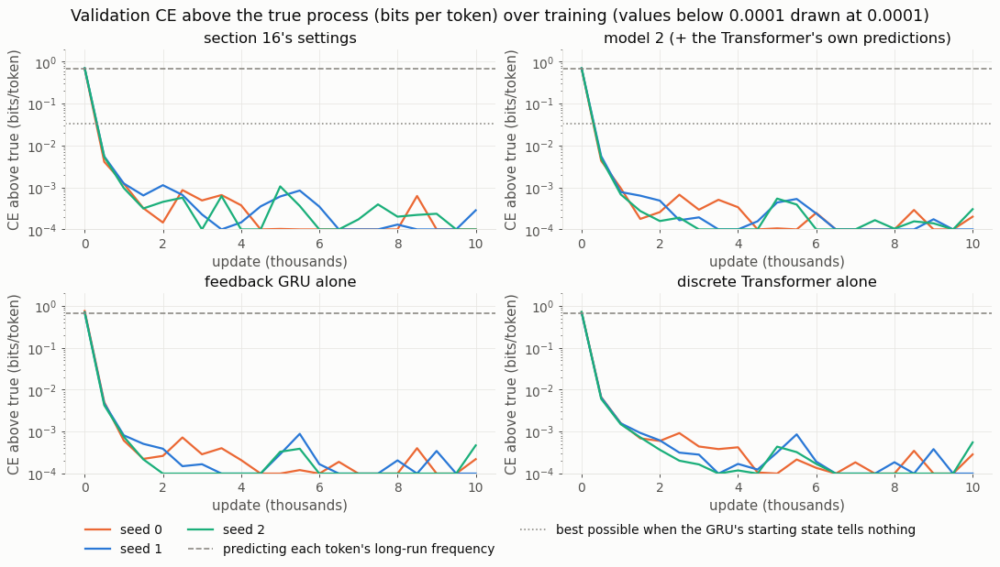

excess_future  excess_first  excess_rest  handoff_states  handoff_information  gru_states_used  best_update  best_excess_future  first_below_0.05  first_below_0.005
config               seed                                                                                                                                                                      
default              0           0.00002       0.00008      0.00002             3.0                  1.0              2.0         9500             0.00016             500.0              500.0
                     1           0.00013       0.00022      0.00012             2.0                  1.0              3.0         9500             0.00035             500.0             1000.0
                     2           0.00001       0.00003      0.00001             2.0                  1.0              2.0         6000             0.00025             500.0             1000.0
model_2              0           0.00006      -0.00017      0.00007             2.0                  1.0              2.0         8000             0.00014             500.0              500.0
                     1           0.00001       0.00014      0.00001             2.0                  1.0              2.0         7500             0.00010             500.0             1000.0
                     2           0.00009      -0.00018      0.00011             2.0                  1.0              2.0         4500             0.00006             500.0              500.0
feedback_GRU         0           0.00006      -0.00017      0.00007             NaN                  NaN              NaN         7500             0.00017             500.0             1000.0
                     1           0.00011       0.00043      0.00009             NaN                  NaN              NaN        10000             0.00011             500.0              500.0
                     2           0.00022      -0.00024      0.00024             NaN                  NaN              NaN         9500             0.00010             500.0              500.0
discrete_Transformer 0           0.00013      -0.00020      0.00015             NaN                  NaN              NaN         9000             0.00016             500.0             1000.0
                     1           0.00011       0.00044      0.00010             NaN                  NaN              NaN        10000             0.00011             500.0             1000.0
                     2           0.00028      -0.00025      0.00030             NaN                  NaN              NaN         9000             0.00010             500.0             1000.0

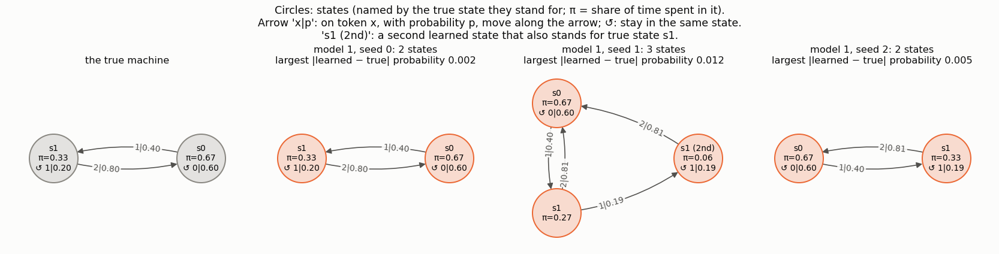

In [14]:
pilot = ["default", "model_2", "feedback_GRU", "discrete_Transformer"]
fig = CC.plot_curves(pilot); plt.show()
summary = CC.summary()
cols = ["config", "seed", "excess_future", "excess_first", "excess_rest", "handoff_states", "handoff_information",
        "gru_states_used", "best_update", "best_excess_future", "first_below_0.05", "first_below_0.005"]
display(summary[summary.config.isin(pilot)].reindex(columns=cols).set_index(["config", "seed"]).round(5))
fig = CC.plot_machines({f"model 1, seed {s}": f for (n, s), f in CC.finished(["default"]).items()}); plt.show()

* **All four models learn the coin on every seed.** At 10,000 updates the test excess of each model's main predictor
  is:
  * model 1: 0.00001–0.00013;
  * model 2: 0.00001–0.00009;
  * the feedback GRU alone: 0.00006–0.00022;
  * the discrete Transformer alone: 0.00011–0.00028.

  Every run is below 0.005 bits by update 500–1,000. The standard error of one run's test excess is 2e-5 to 9e-5, so
  differences below about 0.0003 are noise.
* **Model 1's starting state is exact.** Its Transformer gives the GRU 2 or 3 different states, and their information
  fraction is 1 on all seeds: the starting state tells the true state exactly.
* **Model 1's GRU has the true machine.** On seeds 0 and 2 it has the true 2 states. Seed 1 has 3: two of them stand
  for true state s1 and predict the same, shown as "s1 (2nd)".
* **The choice is fixed on 16–98% of windows at the end** (seed 2: 98%) without doing any harm. The two right states
  were already found.

### 5.4 The search
Every configuration's test excess at the final parameters (filled markers) and at the best-validation parameters
(hollow), over the 20 future tokens. Grey dashed: remembers nothing; dotted: the best possible when the GRU's
starting state tells nothing. Then the learning rate × beta1 grid, and the table of every run.

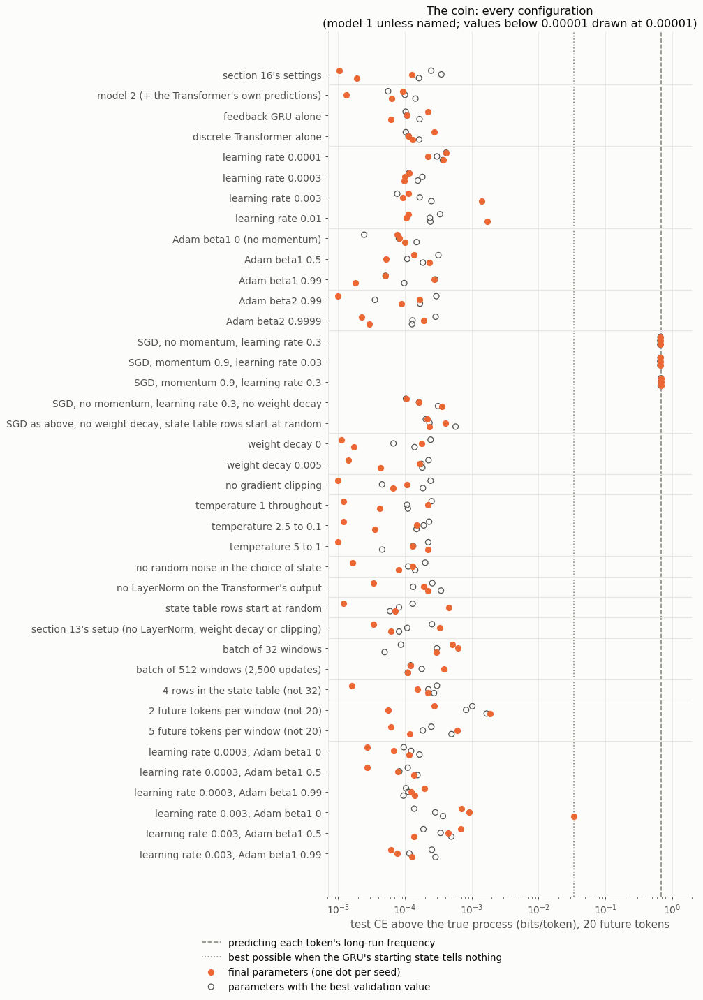

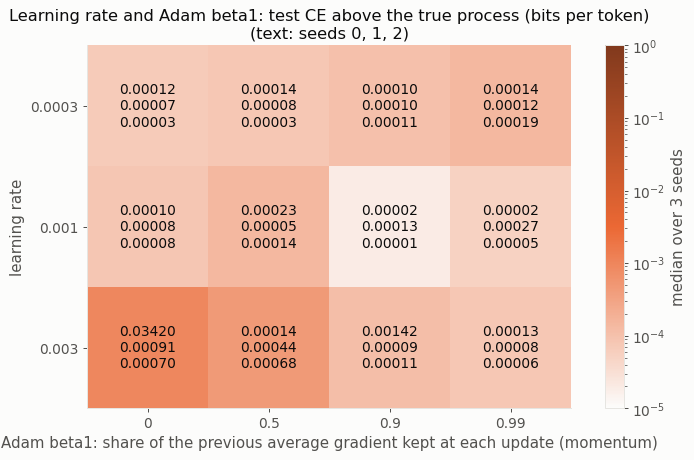

,group,seeds,median_excess,worst_excess,worst_first,worst_rest,best_valid_worst,handoff_info_min,gru_states_max,slowest_below_0_005,minutes
config,,,,,,,,,,,
default,section 16's settings,3,0.00002,0.00013,0.00022,0.00012,0.00035,1.00000,3.0,1000.0,27.40345
model_2,reference models,3,0.00006,0.00009,0.00014,0.00011,0.00014,1.00000,2.0,1000.0,27.55823
feedback_GRU,reference models,3,0.00011,0.00022,0.00043,0.00024,0.00017,NaN,NaN,1000.0,7.78623
discrete_Transformer,reference models,3,0.00013,0.00028,0.00044,0.00030,0.00016,NaN,NaN,1000.0,14.40722
lr_1e-4,learning rate,3,0.00038,0.00041,0.00076,0.00040,0.00041,1.00000,2.0,5000.0,36.65056
lr_3e-4,learning rate,3,0.00010,0.00011,0.00064,0.00011,0.00018,1.00000,2.0,2000.0,34.81188
lr_3e-3,learning rate,3,0.00011,0.00142,0.00249,0.00136,0.00025,1.00000,2.0,500.0,26.29845
lr_1e-2,learning rate,3,0.00011,0.00171,0.00047,0.00177,0.00034,1.00000,2.0,500.0,25.93417
beta1_0,Adam beta1 (momentum),3,0.00008,0.00010,0.00014,0.00010,0.00015,1.00000,2.0,1000.0,22.52192


In [15]:
fig = CC.plot_search(summary[~summary.config.str.startswith("even_")]); plt.show()
fig = CC.plot_grid(summary); plt.show()
by_config = summary[~summary.config.str.startswith("even_")].groupby("config", sort=False).agg(
    group=("group", "first"), seeds=("seed", "count"),
    median_excess=("excess_future", "median"), worst_excess=("excess_future", "max"),
    worst_first=("excess_first", "max"), worst_rest=("excess_rest", "max"),
    best_valid_worst=("best_excess_future", "max"),
    handoff_info_min=("handoff_information", "min"), gru_states_max=("gru_states_used", "max"),
    slowest_below_0_005=("first_below_0.005", "max"), minutes=("minutes", "median"))
display(by_config.round(5))

* **With AdamW, model 1 learns the coin under every change tried.** That is 93 runs (31 configurations × 3 seeds):
  * 92 end within 0.002 bits of exact, and 83 within 0.0005;
  * every configuration is below 0.005 bits by update 1,000, except the lower learning rates: 0.0003 takes until
    2,000, and 0.0001 until 4,500–5,000, ending at 0.0002–0.0004.
* **Nothing tried does better than section 16's settings,** which are already at the noise level (0.00001–0.00013).
* **What makes it worse.**
  * A larger learning rate: at 0.003 and at 0.01, one seed of three ends at 0.0014 and 0.0017.
  * Only 2 future tokens per window: seed 0 ends at 0.0019.
  * A batch of 32 windows: 0.0003–0.0006, from the noisier gradient.
  * **Learning rate 0.003 without momentum (beta1 0): seed 0 collapses.**
    * Between updates 5,500 and 6,000 its Transformer starts giving the GRU the same state on every window, and does
      so to the end.
    * It ends at 0.0342 bits. That is the best possible when the starting state tells nothing (0.0339): the first
      future token is predicted as if nothing were remembered (0.678 bits above exact), and the other 19 are almost
      exact (0.0003).
    * In those 500 updates the gap between the Transformer's two highest scores jumped from 0.5 to 10.4. The
      gradient reaching its encoder fell from 1e-4 just after the collapse to 2e-9 at the end, and it never
      recovered.
    * The other two seeds end at 0.0009 and 0.0007.
* **What does not matter on the coin.** None of these changes moves the result outside 0 to 0.0006 bits (54 runs):
  * Adam's beta1 (0, 0.5, 0.99) at learning rate 0.001, and its beta2;
  * weight decay 0 or 0.005, and no clipping;
  * the three temperature schedules, and no noise in the choice;
  * no LayerNorm, random table rows, and the original setup;
  * 4 table rows, a batch of 512, and 5 future tokens.
* **A fixed choice does no harm here as long as it holds the right states.** Without LayerNorm, and in the original
  setup:
  * the gap is above 10 from update 500 on every seed, and the choice is fixed on all windows at the end;
  * by update 500 the Transformer already gives the GRU the 2 right states (excess 0.004–0.005 there);
  * these runs end at 0.00003–0.0004.

  On the coin the right states are found within the first 500 updates, because the last token tells the state. On
  renewal-15 the choice became fixed before the right states were found (section 4).
* **SGD, as first set up, fails.** All 9 runs with SGD end at 0.668–0.682, the level of remembering nothing (0.679):
  no momentum at learning rate 0.3, and momentum 0.9 at 0.03 and at 0.3.
  * **The cause is the weight decay, not SGD.** SGD adds the weight decay to the gradient.
    * At learning rate 0.3 that shrinks every weight by 0.3 × 5e-4 = 1.5e-4 per update, 300 times AdamW's
      0.001 × 5e-4. Over 10,000 updates the factor is e^(−1.5) = 0.22.
    * Seed 0's GRU weights have length 6.97 at the start and 1.64 at the end, 0.24 of it: close to what the decay alone
      would do.
    * With momentum 0.9 at learning rate 0.3 the shrinking is 10 times stronger, and the GRU's weights end at about
      2e-6.
    * Momentum 0.9 at learning rate 0.03 takes the same steps in the long run as no momentum at 0.3. The two give the
      same results, within 0.0002 on each seed.
  * **Without weight decay, SGD learns the coin.** With no momentum at learning rate 0.3, all 6 runs reach 0.0001–0.0004
    bits at 10,000 updates, with the table as built and with random rows. The Transformer gives the GRU 2 states with
    information fraction 1.
  * **But slowly.**
    * It stays at the level of remembering nothing until update 2,000–3,000, and is below 0.005 only by 4,000–4,500
      (AdamW: 500–1,000).
    * Random table rows do not shorten this, so it is not the flat start of section 4.
    * In updates 500–2,000 the gradients are about as large as under AdamW: 3e-5 to 8e-4 for the Transformer
      (AdamW: 4e-5 to 4e-4) and 2e-4 to 1e-3 for the GRU (AdamW: 4e-4 to 3e-3).
    * What differs is the step. SGD's is the learning rate times the gradient. Adam's step for each weight is about
      the learning rate, whatever the gradient's size (Kingma & Ba 2015).

### 5.5 Where the remaining error comes from
The excess at each of the 20 future tokens for selected configurations (token 1 is the prediction of the state the
Transformer gives the GRU); the gap between the Transformer's two highest state scores and the states it gives the GRU over
training; and section 4.5's
gradient measurements at the final parameters.

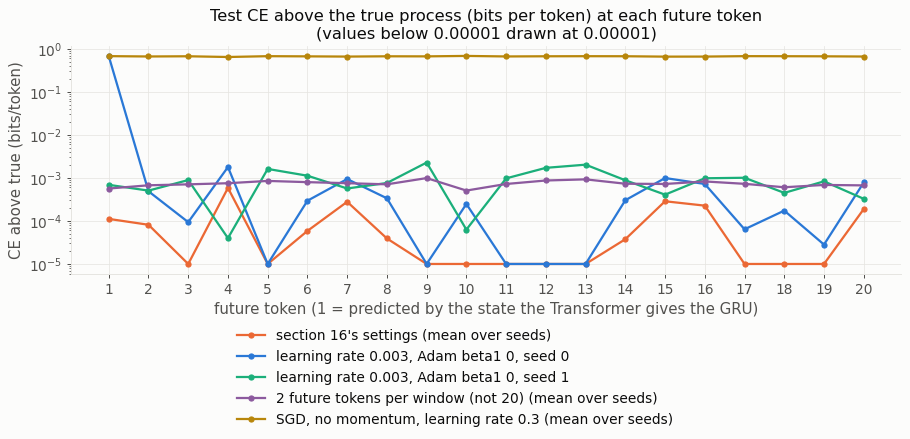

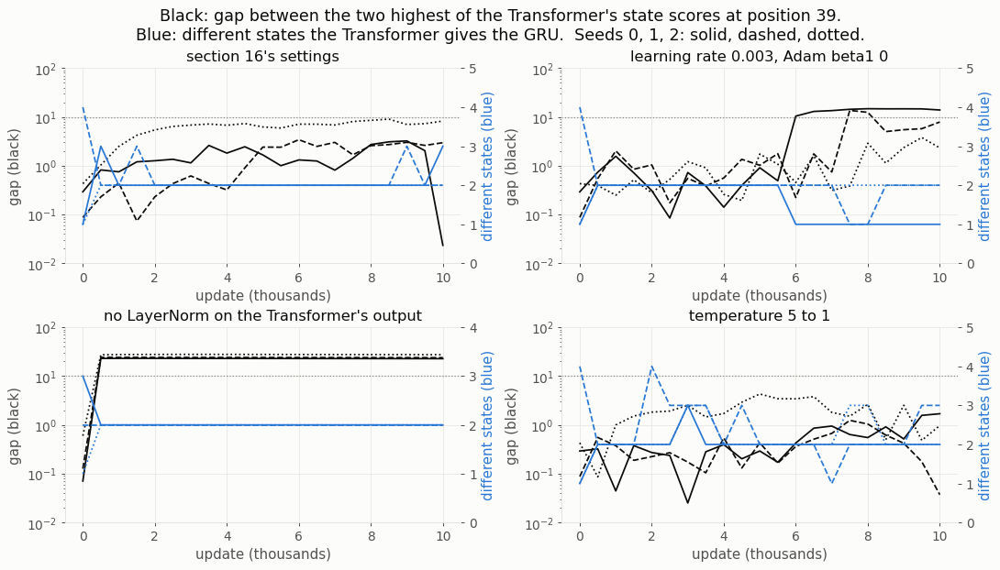

choice_locked_share grad_at_handoff_vector grad_after_choice grad_encoder  grad_gru handoff_states handoff_information encoder_classifier encoder_classifier_untrained
config           seed                                                                                                                                                                       
default          0               2.72e-01               9.53e-03          4.47e-05     5.14e-05  4.82e-04       3.00e+00            1.00e+00           1.00e+00                     1.00e+00
                 1               1.63e-01               9.52e-03          4.37e-05     4.53e-05  3.20e-04       2.00e+00            1.00e+00           1.00e+00                     1.00e+00
                 2               9.75e-01               8.85e-03          7.13e-06     9.09e-06  2.04e-04       2.00e+00            1.00e+00           1.00e+00                     1.00e+00
tau_5_1          0               2.93e-03               9.76e-03          3.52e-05     4.60e-05  4.88e-04       2.00e+00            1.00e+00           1.00e+00                     1.00e+00
                 1               0.00e+00               9.30e-03          6.60e-05     9.66e-05  6.20e-04       3.00e+00            1.00e+00           1.00e+00                     1.00e+00
                 2               0.00e+00               9.21e-03          4.06e-05     5.47e-05  5.38e-04       2.00e+00            1.00e+00           1.00e+00                     1.00e+00
no_layernorm     0               1.00e+00               9.77e-03          6.49e-15     1.10e-13  5.78e-04       2.00e+00            1.00e+00           1.00e+00                     1.00e+00
                 1               1.00e+00               9.29e-03          6.70e-21     7.72e-20  6.14e-04       2.00e+00            1.00e+00           1.00e+00                     1.00e+00
                 2               1.00e+00               8.86e-03          1.63e-17     2.46e-16  3.55e-05       2.00e+00            1.00e+00           1.00e+00                     1.00e+00
lr_0.003_beta1_0 0               1.00e+00               1.32e-02          2.93e-08     4.11e-08  5.08e-04       1.00e+00            0.00e+00           1.00e+00                     1.00e+00
                 1               9.86e-01               8.07e-03          1.00e-06     2.54e-06  1.08e-03       2.00e+00            1.00e+00           1.00e+00                     1.00e+00
                 2               4.22e-01               8.66e-03          6.93e-05     2.44e-05  1.74e-03       2.00e+00            1.00e+00           1.00e+00                     1.00e+00

In [16]:
POSITION_CONFIGS = ['default', ('lr_0.003_beta1_0', 0), ('lr_0.003_beta1_0', 1), 'L_2', 'sgd_m0_lr0.3']
TRAINING_CONFIGS = ['default', 'lr_0.003_beta1_0', 'no_layernorm', 'tau_5_1']

fig = CC.plot_by_position(POSITION_CONFIGS); plt.show()
fig = CC.plot_over_training(TRAINING_CONFIGS); plt.show()
gcols = ["config", "seed", "choice_locked_share", "grad_at_handoff_vector", "grad_after_choice", "grad_encoder",
         "grad_gru", "handoff_states", "handoff_information", "encoder_classifier", "encoder_classifier_untrained"]
display(sci(summary[summary.config.isin(TRAINING_CONFIGS)].reindex(columns=gcols).set_index(["config", "seed"]).astype(float), 2))

* **Where the error sits.**
  * In the runs that learn, it is spread over the 20 future tokens at 1e-5 to 2e-3 per token. That is the noise
    level of 4,096 test windows.
  * In the collapsed run (learning rate 0.003, beta1 0, seed 0), all of it sits on the first future token (0.68 bits).
    From the second token on, the GRU is as good as in the other runs, because one real token tells it the coin's
    state.
  * With SGD every token is at about 0.67.
* **The gap over training.**
  * With section 16's settings it stays below 10 for all 10,000 updates on every seed.
  * With temperature 5 to 1 it stays below 5, and the choice is almost never fixed at the end (0–0.3% of windows).
  * Without LayerNorm it is above 20 from update 500 on, with 2 states throughout.
  * The collapse at update 6,000 shows as the gap jumping above 10 and the number of states falling from 2 to 1.
* **The gradient table.**
  * Gradient after the choice:
    * where the choice is fixed on every window it is 7e-21 to 7e-15 without LayerNorm, and 3e-8 in the collapsed
      run;
    * where it is fixed on at most 42% of windows, 4e-5 to 7e-5.
  * The gradient at the state vector given to the GRU is 8e-3 to 1.3e-2 in all of them.
  * The GRU's own gradient is 4e-5 to 2e-3.

### 5.6 50,000 updates
Section 16's settings and section 13's original setup, as long as the renewal-15 runs, with the temperature schedule
laid over the 50,000 updates. On renewal-15 the original setup's Transformer ended with a fixed choice and the GRU with
one state on every seed (sections 3 and 4).

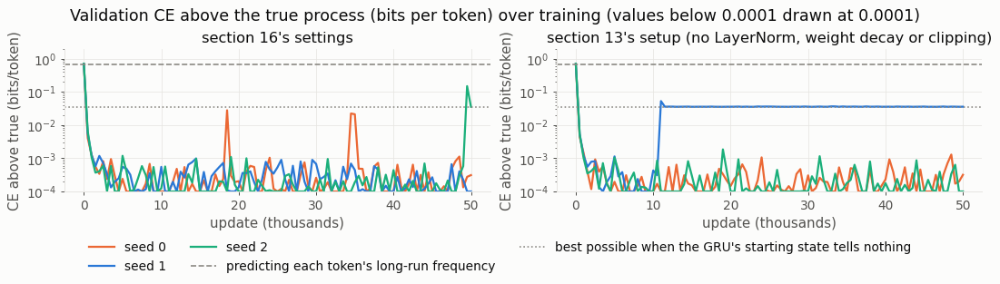

excess_future  excess_first  excess_rest  handoff_states  handoff_information  gru_states_used  best_update  best_excess_future  first_below_0.05  first_below_0.005  choice_locked_share  \
config         seed                                                                                                                                                                                              
default        0           0.00019       0.00054      0.00017               2                  1.0                2        45000             0.00021               500                500              0.45996   
               1           0.00001      -0.00005      0.00001               2                  1.0                2        38500             0.00034               500               1000              0.80762   
               2           0.03404       0.67811      0.00015               1                  0.0                2        20000             0.00006               500               1000              1.00000   
original_setup 0           0.00017       0.00036      0.00016               2                  1.0                2        29500             0.00010               500                500              1.00000   
               1           0.03414       0.67888      0.00021               1                  0.0                2         8500             0.00020               500               1000              1.00000   
               2           0.00024       0.00011      0.00025               2                  1.0                2        20000             0.00004               500               1000              1.00000   

                     grad_after_choice  
config         seed                     
default        0               0.00004  
               1               0.00002  
               2               0.00000  
original_setup 0               0.00000  
               1               0.00000  
               2               0.00000

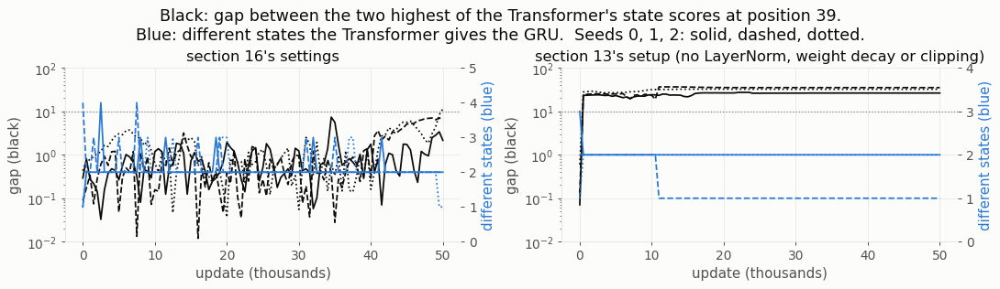

In [17]:
long = ["default", "original_setup"]
fig = CC.plot_curves(long, steps=CC.LONG_STEPS); plt.show()
long_summary = CC.summary(long, steps=CC.LONG_STEPS)
display(long_summary.reindex(columns=cols + ["choice_locked_share", "grad_after_choice"]).set_index(["config", "seed"]).round(5))
fig = CC.plot_over_training(long, steps=CC.LONG_STEPS); plt.show()

* **Over 50,000 updates, the collapse happens on 2 of the 6 runs:**
  * section 16's settings, seed 2, between updates 49,000 and 49,500;
  * the original setup, seed 1, between 10,500 and 11,000.

  Both then give the GRU one state on every window. They end at 0.0340 and 0.0341, the best possible when the starting
  state tells nothing (0.0339), with the first future token 0.678 bits above exact.
* **The original setup's collapsed run never recovers.**
  * Its gap was already 19 before the collapse, rose to 36.7 at it, and stays at 35.3 from about update 25,000.
  * The gradient reaching the Transformer's encoder is 9e-10 right after the collapse and exactly 0 at the end.
  * It gives the GRU one state for the last 39,000 updates.
* **The other four runs end at 0.00001–0.00024.**
* **Brief rises.** Section 16's settings, seed 0, has two brief rises: to 0.028 at update 18,500 and to 0.021–0.022
  at 34,500–35,000. Each recovers within 500–1,000 updates. With LayerNorm the gap stays below about 10 nearly all the
  time (second figure), so the choice can still change back.
* **The coin result therefore does not rule out the renewal-15 problem.** On a process with only two states, and
  after learning it exactly, model 1's Transformer can still fall onto a single state and get stuck there. This
  happened in 3 of the 99 runs with AdamW: 1 of the 93 search runs and 2 of the 6 long runs.

### 5.7 An addition: the even process
The even process (`process.py`, p = 0.5): two causal states and two tokens. In state A the next token is 0 (stay) or
1 (move to B), each with probability 0.5; in state B it is always 1 (back to A). So 1s come in runs of even length.
The state is not fixed by the last token: after a 1 the process can be in either state, depending on whether the
current run of 1s so far is odd or even. A model has to carry that parity from step to step, which the coin never
needs. "Last symbol only" is 0.207 bits above exact, "remembers nothing" 0.251, and the best possible when the GRU's
starting state tells nothing 0.046 (a 0 is needed before the state is known, so it is larger than on the coin).

Model 1 at section 16's settings and the feedback GRU alone, three seeds, 10,000 updates.

,remembers_nothing,last_symbol_only,handoff_useless
even process (test),0.2511,0.2074,0.0458


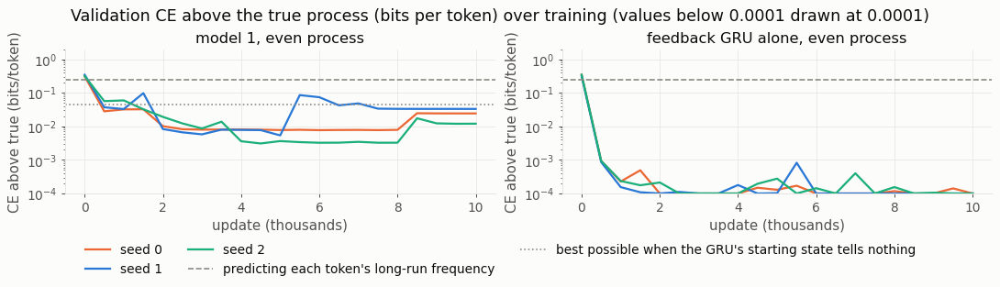

excess_future  excess_first  excess_rest  handoff_states  handoff_information  gru_states_used  best_update  best_excess_future  first_below_0.05  first_below_0.005
config            seed                                                                                                                                                                      
even_model_1      0           0.02310       0.13037      0.01745             3.0              0.50120              3.0         6000             0.00850             500.0                NaN
                  1           0.03276       0.21087      0.02338             2.0              0.28611              4.0         5000             0.00597             500.0                NaN
                  2           0.01182       0.06562      0.00898             4.0              0.74834              3.0         4500             0.00284            1500.0             4000.0
even_feedback_GRU 0           0.00008       0.00034      0.00006             NaN                  NaN              NaN         7500             0.00002             500.0              500.0
                  1           0.00006       0.00023      0.00005             NaN                  NaN              NaN         7500             0.00002             500.0              500.0
                  2           0.00001       0.00006      0.00001             NaN                  NaN              NaN        10000             0.00001             500.0              500.0

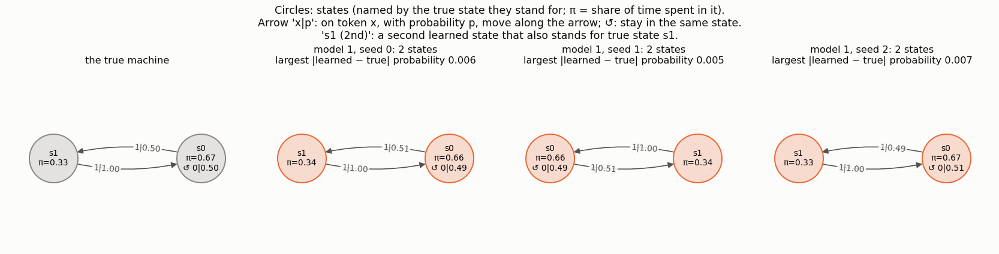

In [18]:
even = ["even_model_1", "even_feedback_GRU"]
display(pd.Series({k: round(v, 4) for k, v in CC.levels("even_model_1").items()}, name="even process (test)").to_frame().T)
fig = CC.plot_curves(even); plt.show()
display(summary[summary.config.isin(even)].reindex(columns=cols).set_index(["config", "seed"]).round(5))
fig = CC.plot_machines({f"model 1, seed {s}": f for (n, s), f in CC.finished(["even_model_1"]).items()}); plt.show()

* **The feedback GRU alone learns the even process exactly on every seed.** It ends at 0.00001–0.00008 after 10,000
  updates and is below 0.005 by update 500.
* **Model 1 does not.**
  * Its best validation parameters are 0.0028–0.0085 bits above exact, at updates 4,500–6,000.
  * Every run then gets worse in a sudden step between two validations 500 updates apart:
    * seed 0 between 8,000 and 8,500: 0.008 → 0.025;
    * seed 1 between 5,000 and 5,500: 0.005 → 0.086, settling at 0.033;
    * seed 2 between 8,000 and 8,500: 0.003 → 0.017, settling at 0.012.
  * The runs end at 0.012–0.033.
* **Its GRU's steps are right; its starting state is not.**
  * The machine read off the GRU's step rule has the true 2 states, with transition probabilities within 0.007 of the
    truth on all three seeds (figure).
  * The error is largest at the first future token (0.066–0.211 at the end) and falls with each token (second figure):
    a 0 tells the GRU the state, since after a 0 the process is always in A, and from then on the GRU predicts exactly.
  * The state the Transformer gives the GRU has information fraction 0.29–0.75 at the end, against 0.82–0.95 at the
    best parameters.
* **The Transformer does not learn the parity well.**
  * A linear classifier reads the true state from the Transformer's output at position 39 with 76–91% accuracy,
    against 72–73% for the same Transformer untrained. Always guessing the more common state, A, gives 67%.
  * The state after a run of 1s depends on whether the run's length is odd or even. The Transformer has to work this
    out from all 40 history tokens at once; the GRU alone works it out one token at a time.
* **Model 1's starting state still tells something.** The best possible when the starting state tells nothing is
  0.0458 here (larger than on the coin, because the even process needs a 0 to fix the state), and model 1's final
  0.012–0.033 is below it.

### 5.8 Findings


1. **Model 1 can learn the coin.** With AdamW it ends within 0.002 bits of exact on 92 of 93 search runs, under every
   change of learning rate, Adam's two momentum terms, weight decay, clipping, temperature, noise, LayerNorm, table
   start, batch size, table size and future length tried. Section 16's settings are already at the noise level.
2. **The coin is easy for the Transformer**: its state is the last token. The right two starting states are found
   within 500 updates, so a choice that becomes fixed afterwards does no harm.
3. **Even here the starting state can collapse to one state and stay there.** This happened in 3 of 99 AdamW runs: a
   jump of the gap above 10 within 500 updates, then a gradient of 1e-9 to 0 to the Transformer. With LayerNorm the
   gap usually stays below 10 and brief collapses recover (section 16's settings, seed 0); without it the choice is
   fixed from update 500 and a collapse is permanent (the original setup, seed 1).
4. **SGD fails** (0.668–0.682, the level of remembering nothing). The cause is SGD's weight decay, which at learning rate 0.3 shrinks the weights 300 times faster per update than AdamW's. Without it, SGD learns the coin (0.0001–0.0004), but it stays at the level of remembering nothing for the first 2,000–3,000 updates, whichever way the table starts.
5. **On the even process model 1 fails but the feedback GRU alone succeeds.** Model 1's GRU learns the right steps;
   what fails is the Transformer's starting state. The Transformer has to read the parity of the last run of 1s from
   the whole history, and only partly does (76–91% against 72–73% untrained).

## 6. Model 1 on renewal-15, -30 and -60 with the best settings found

**The question.** With the best training settings, can model 1 learn a renewal process: renewal-15, and the larger
renewal-30 and renewal-60?

**Why a new search.** Section 5 cannot choose the settings. On the coin, 92 of 93 AdamW runs ended within 0.002 bits
of exact, and nothing did better than section 16's settings, which are at the noise level there (5.4). Yet on
renewal-15 those settings learn the process on one seed of three (section 3). So the search is repeated on renewal-15
itself (6.2–6.4), and its best settings then train model 1 on the three processes (6.5–6.8).

**Files.** `renewal_check.py` defines, trains and reads this section's runs (saved in `runs/renewal_check/`). It uses
section 5's configurations (`coin_check.py`) with the process changed. Every run is recorded the way section 4.4
recorded section 16's runs:
* at every update: the training loss, and the gradient length (before clipping) reaching the whole Transformer, the
  whole GRU, and the state table with the output layer;
* every 250 updates, on 128 windows not used for training: the gradient on both sides of the Transformer's choice of
  state, and the fraction of those windows whose choice is fixed.

The random-number state is restored after each measurement, so training is the same as without them. After 300
updates the parameters with and without the measurements are identical (`renewal_check.test_tracing()`).

In [19]:
import renewal_check as R
NS = (15, 30, 60)
sizes = pd.DataFrame({f"renewal-{N}": {k: getattr(R.settings_of("default", N, 0, R.FINAL_STEPS), k)
                                       for k in ("history_len", "rollout_len", "n_states")} for N in NS}).T
display(sizes.join(pd.DataFrame({f"renewal-{N}": R.levels(N) for N in NS}).T.round(4)))

,history_len,rollout_len,n_states,remembers_nothing,last_symbol_only,handoff_useless,best_loss,nothing_loss
renewal-15,40,20,32,0.0549,0.0513,0.0210,0.4897,0.5446
renewal-30,60,30,64,0.0289,0.0279,0.0150,0.3159,0.3447
renewal-60,120,60,128,0.0145,0.0142,0.0075,0.1952,0.2097


### 6.1 The processes, and when a run has learned one
**Renewal-N** (`process.py`, F = 1/N): between two 1s there are 0 to N − 1 zeros, each number equally likely. Its
causal state is the number of zeros since the last 1, so it has N states. A model has to count, up to N − 1 tokens
back.

**Window sizes** are the ones used before:
* renewal-15: as section 16 (40 history + 20 future tokens, 32 table rows);
* renewal-30: as walkthrough section 10 (60 + 30, 64 rows);
* renewal-60: as walkthrough section 7 (120 + 60, 128 rows).

Every other setting is section 16's unless the search changes it. A configuration that changes a size (table rows,
future tokens) changes it in proportion N / 15.

**Reference levels** (the table below, on each process's 4,096 test windows, bits per token over the future tokens):
* `remembers_nothing`: excess CE when every future token is predicted from the long-run frequency of 1s;
* `last_symbol_only`: excess CE when it is predicted from the previous token alone;
* `handoff_useless`: the best possible excess when the GRU's starting state tells nothing (the GRU then has to wait
  for a 1 before it knows the count);
* `best_loss` and `nothing_loss`: the training loss of the true probabilities and of remembering nothing (the grey
  lines of the whole-training figures in 6.6).

The excess left to remove halves each time N doubles (0.055, 0.029, 0.015 bits). So the results are given as a
fraction of it, and by the true states told apart, not as a fixed number of bits.

**When a run has learned the process.** Two measures on the test windows, for the GRU started from the Transformer's
state:
* **gap closed** = 1 − excess / `remembers_nothing`. 1 is exact; 0 is no better than remembering nothing.
* **true states told apart**: each true state is sent to the learned state it is most often in, and this counts the
  different learned states reached. It is N when every true state has its own learned state.

A run counts as having learned renewal-N when its GRU tells all N true states apart and closes at least 90% of the
gap.

### 6.2 The pilot: 10,000 updates are too few
Section 5 searched with 10,000 updates. On renewal-15 that looked too few. At update 10,000, section 16's
50,000-update runs were still at 0.048–0.055 bits on their validation windows ("remembers nothing": 0.055). Seed 0
reached its best, 0.004, only at update 34,000.

A 10,000-update run is not simply the first fifth of a 50,000-update run: the temperature falls from 2.5 to 0.5 over
the run's own length, so five times faster. The learning rate is constant in both.

To check, 8 configurations were trained for 10,000 updates (seed 0). The columns: `excess` (test, final parameters),
`gap_closed`, `best_excess` at `best_update` (the parameters with the best validation value), `states_told_apart`,
`machine_states` (states of the GRU's machine that recur in the long run), `handoff_codes` (different states the
Transformer hands over on the test windows), `handoff_information` (their information fraction about the true state),
`choice_locked_share` (fraction of windows whose choice is fixed, at the final temperature).

,excess,gap_closed,best_excess,best_update,states_told_apart,best_states_told_apart,machine_states,handoff_codes,handoff_information,choice_locked_share
config,,,,,,,,,,
default,0.0458,0.1649,0.0445,7000,1,1,1,3,0.2762,0.9082
table_random,0.0422,0.2316,0.0422,10000,1,1,1,5,0.3187,0.8232
tau_5_1,0.0514,0.0646,0.0472,8500,2,2,1,6,0.5549,0.5332
tau_const1,0.0504,0.0814,0.0445,3500,1,1,1,4,0.1526,0.4893
lr_3e-3,0.0436,0.2062,0.0335,3500,1,8,1,2,0.2533,1.0000
wd_5e-3,0.0448,0.1845,0.0448,10000,2,2,1,4,0.4465,0.6787
no_noise,0.0497,0.0957,0.0443,6000,1,2,1,5,0.4779,0.5508
K_64,0.0508,0.0739,0.0444,6500,1,2,1,4,0.0856,0.9502


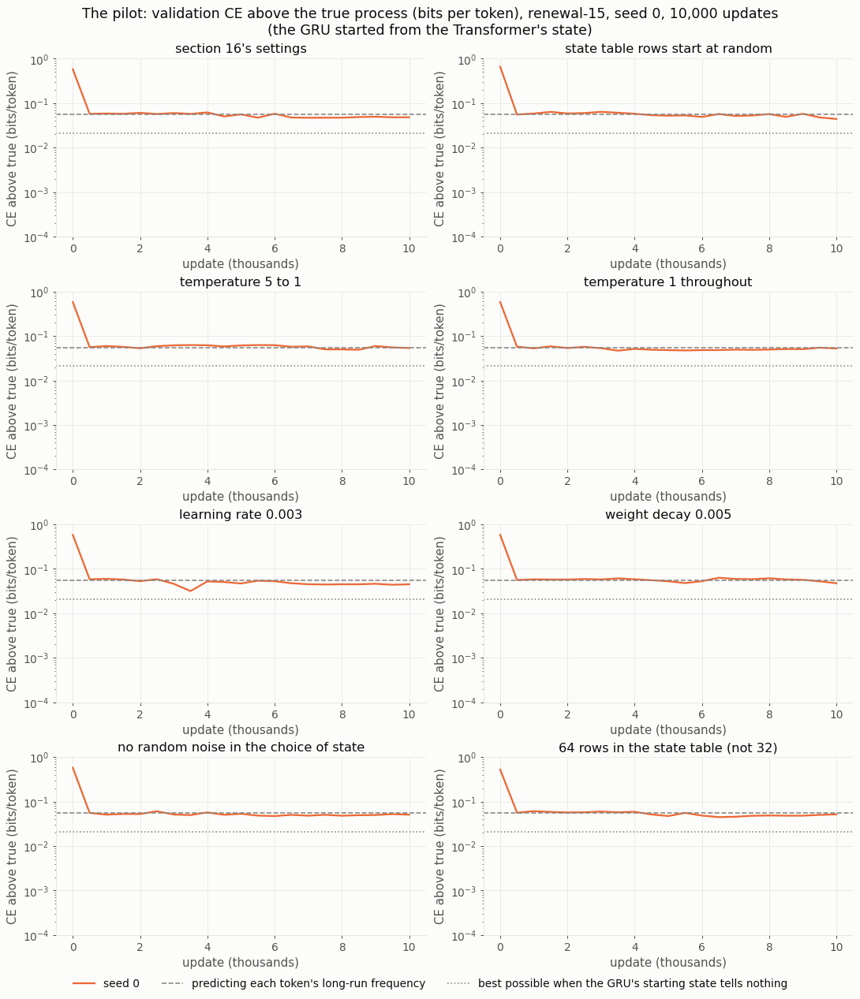

In [20]:
pilot = R.summary([(n, 15, 0, R.PILOT_STEPS) for n in R.PILOT_NAMES])
cols6 = ["config", "excess", "gap_closed", "best_excess", "best_update", "states_told_apart", "best_states_told_apart",
         "machine_states", "handoff_codes", "handoff_information", "choice_locked_share"]
display(pilot[cols6].set_index("config").round(4))
fig = R.plot_curves({R.LABELS[n]: [(0, R.folder_of(n, 15, 0, R.PILOT_STEPS))] for n in R.PILOT_NAMES},
                    title="The pilot: validation CE above the true process (bits per token), renewal-15, seed 0, "
                          "10,000 updates\n(the GRU started from the Transformer's state)"); plt.show()

* **All 8 end at 0.042–0.051 bits** above the true process: 6–23% of the gap closed. At the parameters with their best
  validation value they are at 0.034–0.047.
* **In every run the GRU's machine has a single long-run state**, and the GRU tells apart 1–2 of the 15 true states.
  The Transformer hands over 2–6 different states.
* The one partial exception, learning rate 0.003, told apart 8 states at update 3,500 (0.034 bits) and had lost them
  by the end.
* So a 10,000-update search would compare runs that have all failed. **The search uses 50,000 updates**, as section
  16 did.

### 6.3 The search: one change at a time, 50,000 updates, 3 seeds
20 configurations, each changing one of section 16's settings (named as in section 5). Section 16's settings and the
original setup are included through their existing runs (`runs/imported`). Their settings are the same exactly, and
`training.train` reproduces their final parameters exactly (section 4.4). That makes 66 runs.

Changes from section 5's list:
* **4 table rows** cannot hold renewal-15's 15 states; 16 and 64 rows replace it.
* **A batch of 32 or of 512 windows** sees the same windows as the default (50,000 × 128): 200,000 or 12,500 updates.
  On the coin the batch of 32 kept the number of updates.
* **Left out because on the coin they only learned more slowly**, while renewal-15 already needs most of the 50,000
  updates: learning rate 0.0001 (5 times slower on the coin) and SGD (4–9 times slower without weight decay; with
  it, it fails).
* **Left out to keep the search to about 11 hours** (9 runs at a time, 1.5–2 hours each): Adam's beta2 and beta1
  0.5, which made no difference on the coin, and the learning rate × beta1 grid.

The figure shows each run's test excess at its final parameters (filled) and at the parameters with its best
validation value (hollow). The table gives, per configuration:
* `learned`: the seeds that learned the process (6.1's rule) at the final parameters;
* `learned_at_best`: the same at the parameters with the best validation value;
* the mean and the worst excess at the end, the mean gap closed and states told apart, the mean best excess.

Then the validation curves of four configurations: section 16's settings, learning rate 0.003, random table rows, and
the batch of 32 (its x axis is 4 times longer: the same windows in batches a quarter the size).

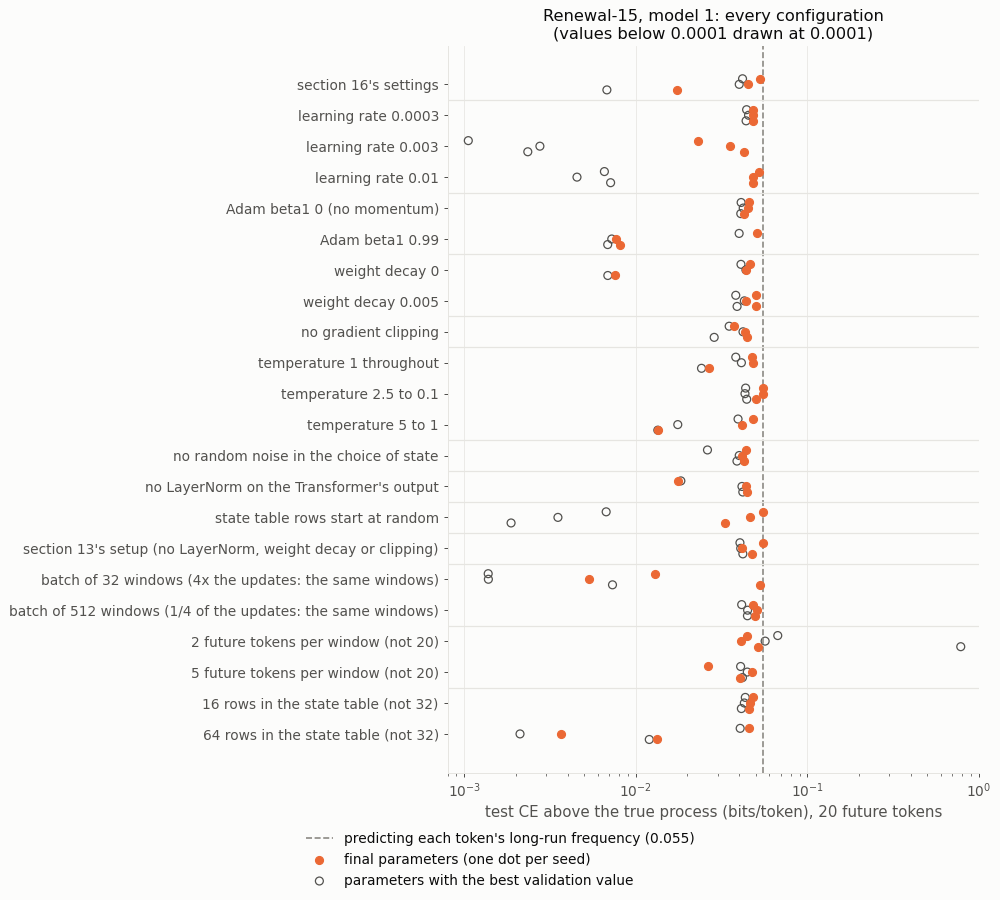

,seeds,learned,learned_at_best,mean_excess,worst_excess,mean_gap_closed,mean_states_told_apart,mean_best_excess
config,,,,,,,,
batch_32,3,1,2,0.0237,0.0529,0.5685,9.6667,0.0034
K_64,3,1,1,0.0209,0.0458,0.6196,9.6667,0.0182
lr_3e-3,3,0,3,0.0337,0.0426,0.3860,5.0000,0.0021
table_random,3,0,2,0.0447,0.0549,0.1859,2.6667,0.0040
lr_1e-2,3,0,1,0.0497,0.0523,0.0943,2.6667,0.0061
beta1_0.99,3,0,0,0.0222,0.0507,0.5963,9.6667,0.0180
wd_0,3,0,0,0.0326,0.0465,0.4061,5.3333,0.0306
tau_5_1,3,0,0,0.0345,0.0482,0.3723,5.3333,0.0235
no_layernorm,3,0,0,0.0355,0.0447,0.3543,5.0000,0.0340


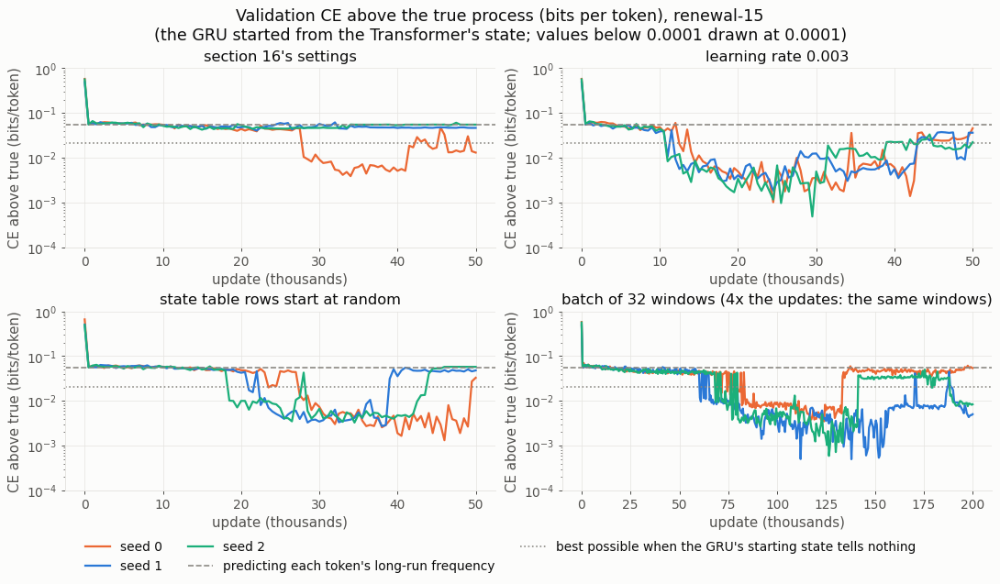

In [21]:
def learned_columns(t):
    t["learned"] = (t.states_told_apart == t.N) & (t.gap_closed >= 0.9)
    t["learned_at_best"] = (t.best_states_told_apart == t.N) & (t.best_gap_closed >= 0.9)
    return t


def by_config(t):
    return t.groupby("config", sort=False).agg(
        seeds=("seed", "size"), learned=("learned", "sum"), learned_at_best=("learned_at_best", "sum"),
        mean_excess=("excess", "mean"), worst_excess=("excess", "max"), mean_gap_closed=("gap_closed", "mean"),
        mean_states_told_apart=("states_told_apart", "mean"), mean_best_excess=("best_excess", "mean"))


search = learned_columns(R.summary(R.search_jobs()))
fig = R.plot_search(search); plt.show()
display(by_config(search).sort_values(["learned", "learned_at_best", "mean_excess"],
                                      ascending=[False, False, True]).round(4))
fig = R.plot_curves({R.LABELS[n]: [(s, R.folder_of(n, 15, s, R.FINAL_STEPS)) for s in R.SEEDS]
                     for n in ("default", "lr_3e-3", "table_random", "batch_32")},
                    title="Validation CE above the true process (bits per token), renewal-15\n"
                          "(the GRU started from the Transformer's state; values below 0.0001 drawn at 0.0001)")
plt.show()

* **At the end of training, 2 of the 66 runs learned renewal-15** (6.1's rule):
  * the batch of 32, seed 1 (0.0053 bits, 90% of the gap closed);
  * 64 table rows, seed 1 (0.0037, 93%).

  Section 16's settings learned it on no seed. Seed 0 ends at 0.0175 bits with 12 of the 15 true states told apart;
  seeds 1 and 2 end at 0.045 and 0.053 with 1.
* **At the parameters with the best validation value, 9 runs had learned it** (hollow circles):
  * learning rate 0.003 on all 3 seeds (0.0011–0.0028 bits, 95–98% of the gap closed);
  * the batch of 32 and random table rows on 2 seeds each;
  * learning rate 0.01 and 64 table rows on 1 seed each.
* **So the main failure is losing the process, not never finding it.** Learning rate 0.003 first closes 90% of the gap
  at update 13,000–16,500 (section 16's seed 0: 32,000), then ends at 0.023–0.043 bits. Random table rows end at
  0.033–0.055.
* **The other 17 configurations never told all 15 true states apart**, at either set of parameters. Some get close
  and keep it:
  * Adam's beta1 0.99: two seeds end at 0.0081 and 0.0077 bits, with 14 states;
  * no weight decay: one seed, 0.0075, 14 states;
  * the temperature from 5 to 1: one seed, 0.013, 13 states.
* **Fewer future tokens do not help.** With 2 future tokens per window, the GRU predicts those 2 tokens almost exactly
  (0.0004–0.0076 bits on its own test windows). Over the usual 20 future tokens it ends at 0.041–0.052 bits, and its
  parameters with the best validation value give 0.057–0.78: its step rule was only trained for 2 steps. (These
  configurations are scored on the usual 20-token test windows; `renewal_check.excess_on_default_windows`.)
* **When a run loses the process, the Transformer's choice is fixed on most windows at the end:** 73–88% of windows
  with learning rate 0.003, 55–100% with random rows, 100% with learning rate 0.01. Three changes keep the choice
  unfixed, but none of them learns the process alone:
  * the temperature held at 1: 2–27% of windows fixed at the end;
  * the temperature from 5 to 1: 14–17% on two seeds, 88% on the third;
  * no noise in the choice: 1–10% on two seeds, 65% on the third.

**When a run loses what it learned.** "Loses" here means a validation value above 0.02 bits after one below 0.01. The
table lists every such event in the search. Configurations that change the number of future tokens are left out,
because their validation windows are shorter.

For each event, `largest_gradient` is the longest gradient (all parameters together, before clipping) in the 1,000
updates before it. Training clips the gradient to length 1.0, and in these runs it is usually 0.01–0.05 long (the
median over updates 10,000 to the end of each run).

In [22]:
same_L = lambda jobs: [j for j in jobs if "rollout_len" not in R.CONFIGS[j[0]]["settings"]]
lost = R.losses(same_L(R.search_jobs()))
display(lost.set_index(["config", "seed"]).round(4))
print(f"{len(lost)} events in {lost.groupby(['config', 'seed']).ngroups} runs; "
      f"{(lost.largest_gradient > 1).sum()} with a gradient longer than 1.0 in the 1,000 updates before")

update  validation_excess  largest_gradient      at
config       seed                                                     
default      0      42500             0.0290            6.9868   42340
table_random 0      49500             0.0272            0.0685   48987
             1      39000             0.0312            0.5659   38786
             2      28000             0.0428            0.3931   27952
             2      44000             0.0403            0.0850   43831
lr_3e-3      0      34500             0.0360            0.1386   33972
             0      43000             0.0355            1.6463   42748
             1      43000             0.0247            0.6436   42884
             1      49500             0.0364            0.9706   48645
             2      39000             0.0224            0.2944   38645
lr_1e-2      0      23500             0.0206            0.1762   23196
             1      17500             0.0486            0.7178   17400
             1      21000             0.0264            0.2025   20870
             2       4500             0.0491            0.2948    4478
             2      15000             0.0341            0.1152   14464
             2      24000             0.0344            0.1629   23744
beta1_0.99   0      33500             0.0477            0.0915   33247
batch_32     0      83000             0.0437            0.1780   82466
             0     133500             0.0356            0.1342  133272
             1      61500             0.0426            0.1630   61243
             1      79500             0.0365            0.1928   79017
             1     170500             0.0412            0.1412  170193
             1     187500             0.0229            1.7941  186613
             2      69500             0.0413            0.1702   69181
             2      70500             0.0395            0.1709   69594
             2      76500             0.0405            0.1553   75956
             2      78000             0.0390            0.1575   77750
             2      79500             0.0428            0.1377   79043
             2     141500             0.0373            1.6395  141361
K_64         0      32000             0.0212            0.1823   31541
             0      35500             0.0432            0.0826   34698

31 events in 15 runs; 4 with a gradient longer than 1.0 in the 1,000 updates before


* **31 events in 15 runs. Only 4 have a gradient longer than the clipping length (1.0)** in the 1,000 updates before
  them; in the other 27 the longest is at most 0.97.
* So the process is usually lost without any single large step. The training loss just drifts up over a few hundred
  updates.

### 6.4 The second search: two changes together
6.3 found two kinds of change:
* **changes that make model 1 learn renewal-15, but not keep it:** learning rate 0.003 and random table rows;
* **changes that keep the Transformer's choice from becoming fixed, but do not learn it:** the temperature held at 1,
  the temperature from 5 to 1, and no noise in the choice.

The second search pairs each change of the first kind with each of the second, and adds the first two together:
7 configurations, 3 seeds, 50,000 updates (`COMBINED_NAMES` in `renewal_check.py`).

Two changes of the first kind are left out:
* the batch of 32 (learned on 2 seeds at its best parameters), because each of its runs takes 4 times the updates
  (about 2 hours each);
* 64 table rows, which had not finished when the second search started.

The figure shows the changes alone (from 6.3) above the pairs. The table is as in 6.3, then the events in which a
run loses what it learned (as defined in 6.3).

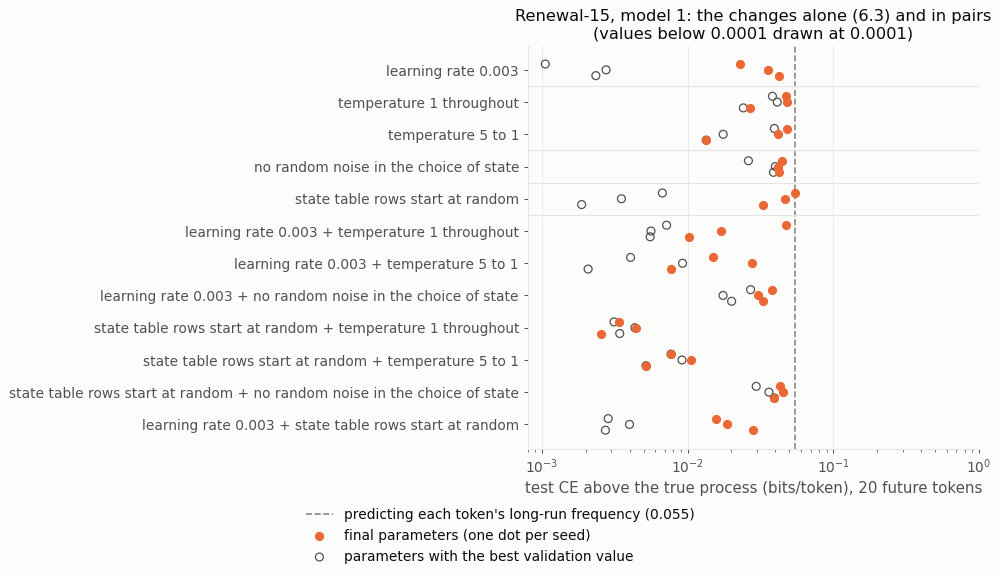

excess  gap_closed  states_told_apart  learned  best_excess  best_update  learned_at_best  machine_states  long_excess  choice_locked_share  first_90%_closed
config                  seed                                                                                                                                                               
lr_3e-3+tau_const1      0     0.0102      0.8148                 15    False       0.0055        32000            False              15       0.0034               0.0479           25500.0
                        1     0.0170      0.6912                 13    False       0.0056        44500            False              13       0.0134               0.0889           31000.0
                        2     0.0471      0.1416                  4    False       0.0072        34500            False               4       0.0596               0.6895           33500.0
lr_3e-3+tau_5_1         0     0.0077      0.8599                 14    False       0.0021        35500             True              14       0.0071               0.0195           23500.0
                        1     0.0276      0.4976                 15    False       0.0092        27500            False              15       0.0154               1.0000           24500.0
                        2     0.0149      0.7291                 12    False       0.0041        39000             True              12       0.0143               0.0791           26500.0
lr_3e-3+no_noise        0     0.0329      0.4008                  7    False       0.0201        48500            False               7       0.0337               0.0117               NaN
                        1     0.0304      0.4471                  8    False       0.0175        45500            False               8       0.0319               0.0596               NaN
                        2     0.0378      0.3117                  6    False       0.0271        29000            False               6       0.0411               0.0088               NaN
table_random+tau_const1 0     0.0026      0.9534                 15     True       0.0034        46500             True              15       0.0008               0.0693           30500.0
                        1     0.0044      0.9197                 15     True       0.0043        45500             True              15       0.0020               0.0459           32000.0
                        2     0.0034      0.9384                 15     True       0.0031        45500             True              15       0.0009               0.0586           41000.0
table_random+tau_5_1    0     0.0052      0.9055                 15     True       0.0052        50000             True              15       0.0036               0.0273           44500.0
                        1     0.0105      0.8081                 15    False       0.0092        44500            False              15       0.0107               0.0137           44500.0
                        2     0.0077      0.8598                 14    False       0.0077        50000            False              14       0.0078               0.2881           46500.0
table_random+no_noise   0     0.0394      0.2816                  3    False       0.0394        48000            False               2       0.0510               0.0088               NaN
                        1     0.0455      0.1711                  1    False       0.0362        32000            False               1       0.0543               0.0088               NaN
                        2     0.0430      0.2170                  2    False       0.0296         5000            False               2       0.0517               0.0225               NaN
lr_3e-3+table_random    0     0.0283      0.4848                  9    False       0.0027        34000             True               9       0.0305               0.6504           11500.0
                        1     0.0186      0.6616                 11    False      

,seeds,learned,learned_at_best,mean_excess,worst_excess,mean_gap_closed,mean_states_told_apart,mean_best_excess
config,,,,,,,,
table_random+tau_const1,3,3,3,0.0035,0.0044,0.9372,15.0000,0.0036
table_random+tau_5_1,3,1,1,0.0078,0.0105,0.8578,14.6667,0.0073
lr_3e-3+table_random,3,0,3,0.0208,0.0283,0.6203,10.6667,0.0032
lr_3e-3+tau_5_1,3,0,2,0.0167,0.0276,0.6955,13.6667,0.0051
lr_3e-3+tau_const1,3,0,0,0.0248,0.0471,0.5492,10.6667,0.0061
lr_3e-3+no_noise,3,0,0,0.0337,0.0378,0.3865,7.0000,0.0216
table_random+no_noise,3,0,0,0.0426,0.0455,0.2232,2.0000,0.0351


update  validation_excess  largest_gradient     at
config               seed                                                    
lr_3e-3+tau_const1   0      33500             0.0457            0.1447  33337
                     2      36000             0.0201            5.2323  35572
lr_3e-3+tau_5_1      0      21000             0.0400            0.1136  20531
                     1      16000             0.0463            0.1434  15812
                     1      30000             0.0275            0.1312  29685
table_random+tau_5_1 1      39000             0.0387            0.0829  38637
                     2      39000             0.0445            0.0791  38072
lr_3e-3+table_random 0      15000             0.0368            0.0768  14325
                     0      46000             0.0257            1.0451  45300
                     2      24500             0.0394            0.0784  24265
                     2      49000             0.0215            0.0631  48807

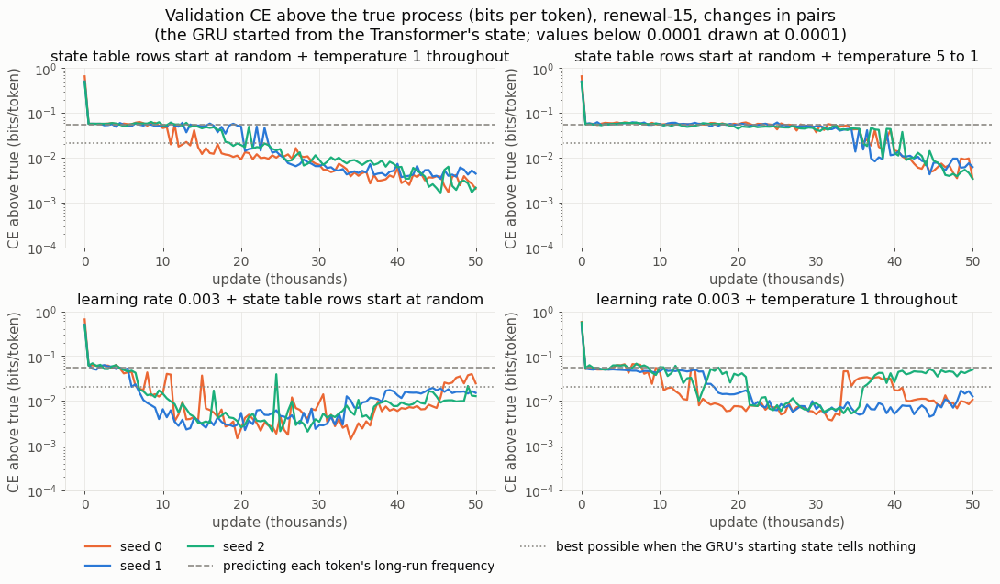

In [23]:
combined = learned_columns(R.summary(R.combined_jobs()))
parts = search[search.config.isin(R.LEARNERS + R.KEEPERS)]
fig = R.plot_search(pd.concat([parts, combined]),
                    title="Renewal-15, model 1: the changes alone (6.3) and in pairs\n"
                          "(values below 0.0001 drawn at 0.0001)"); plt.show()
cols_pairs = ["config", "seed", "excess", "gap_closed", "states_told_apart", "learned", "best_excess", "best_update",
              "learned_at_best", "machine_states", "long_excess", "choice_locked_share", "first_90%_closed"]
display(combined[cols_pairs].set_index(["config", "seed"]).round(4))
display(by_config(combined).sort_values(["learned", "learned_at_best", "mean_excess"],
                                        ascending=[False, False, True]).round(4))
lost2 = R.losses(R.combined_jobs())
display(lost2.set_index(["config", "seed"]).round(4))
fig = R.plot_curves({R.LABELS[n]: [(s, R.folder_of(n, 15, s, R.FINAL_STEPS)) for s in R.SEEDS]
                     for n in ("table_random+tau_const1", "table_random+tau_5_1", "lr_3e-3+table_random",
                               "lr_3e-3+tau_const1")},
                    title="Validation CE above the true process (bits per token), renewal-15, changes in pairs\n"
                          "(the GRU started from the Transformer's state; values below 0.0001 drawn at 0.0001)")
plt.show()

* **Random table rows with the temperature held at 1 learned renewal-15 on all 3 seeds, and kept it to the end:**
  * 0.0026, 0.0044 and 0.0034 bits (92–95% of the gap closed);
  * all 15 true states told apart, and a GRU machine with 15 long-run states;
  * 0.0008–0.0020 bits over 200 future tokens.

  It is the only one of the 29 configurations that learned renewal-15 at the end of training on more than one seed,
  and its mean excess at the end (0.0035 bits) is the lowest. It learns more slowly than learning rate 0.003: it first
  closes 90% of the gap at update 30,500–41,000. None of its 3 runs ever loses what it learned. Its choice is fixed on
  5–7% of the test windows at the end.
* **With the temperature from 5 to 1 instead, random rows learned on 1 seed** (0.0052 bits). The other two end at
  0.0077 and 0.0105 bits, with 14 and 15 states told apart. They were still improving: two of the three seeds reach
  their best validation value at the last update.
* **Every pair with learning rate 0.003 learns early, then loses it:**
  * with random rows: the fastest (90% of the gap first closed at update 9,500–13,500), and all 3 seeds had learned
    at their best parameters (0.0027–0.0040 bits). But it ends at 0.016–0.028, with the choice fixed on 65–98% of
    windows.
  * with the temperature held at 1: ends at 0.010–0.047 (choice fixed on 5–69% of windows);
  * with the temperature from 5 to 1: ends at 0.0077–0.028.

  So holding the temperature does not stop learning rate 0.003 from losing the process. The learning rate in
  `training.py` is constant, so the steps do not shrink once the process is learned. These runs do not test whether a
  falling learning rate would keep it.
* **No noise in the choice prevents learning** with either partner: 0.030–0.046 bits at the end.
* **Losing what was learned** (last table): 11 events in 8 runs. In 2 of them the longest gradient in the 1,000
  updates before is above the clipping length. One is a single large update: learning rate 0.003 with the temperature
  held at 1, seed 2, has a gradient of length 5.23 at update 35,572, and its validation excess goes from 0.0058
  (update 35,000) to 0.020 (36,000). The other is 1.05. In the other 9 the longest is at most 0.14.

**The chosen settings: random table rows with the temperature held at 1** (`table_random+tau_const1`). These are section
16's settings with two changes:
* the state table starts with random rows (randn / √S) instead of equal rows;
* the temperature is 1 for the whole training, instead of falling from 2.5 to 0.5.

### 6.5 The chosen settings on renewal-15, -30 and -60
Model 1 with random table rows and the temperature held at 1: 3 seeds, 50,000 updates, each process with its own
window size (6.1). The renewal-15 runs are those of 6.4.

Renewal-15 first closed 90% of its gap at update 30,500–41,000, so 50,000 updates may be short for the larger
processes. They are kept at 50,000, like every run in this section; the curves show whether a run was still improving
at the end.

The table gives the test results at the final and at the best parameters, as in 6.3, plus:
* `long_excess`: the GRU's excess over 200 future tokens, started from the Transformer's state (final parameters);
* `machine_states`: the states of the GRU's machine that recur in the long run (N when it has the size of the true
  machine);
* `handoff_codes` and `handoff_information`: the different states the Transformer hands over, and their information
  fraction about the true state;
* `encoder_classifier`: the fraction of test windows whose true state a linear classifier reads from the Transformer's
  output vector at the last history position (fitted on 4,096 other windows). `encoder_classifier_untrained` is the
  same for the Transformer as built.

excess  gap_closed  states_told_apart  learned  best_excess  best_update  best_gap_closed  best_states_told_apart  long_excess  machine_states  handoff_codes  handoff_information  choice_locked_share  \
N  seed                                                                                                                                                                                                            
15 0     0.0026      0.9534                 15     True       0.0034        46500           0.9377                      15       0.0008              15             13               0.8379               0.0693   
   1     0.0044      0.9197                 15     True       0.0043        45500           0.9208                      15       0.0020              15             11               0.7314               0.0459   
   2     0.0034      0.9384                 15     True       0.0031        45500           0.9430                      15       0.0009              15             12               0.8675               0.0586   
30 0     0.0258      0.1068                  1    False       0.0210        35000           0.2712                       1       0.0283               1              7               0.1200               0.6816   
   1     0.0210      0.2710                  2    False       0.0210        50000           0.2710                       2       0.0303               1              6               0.3908               0.1904   
   2     0.0217      0.2465                  1    False       0.0210        40500           0.2722                       2       0.0278               1              7               0.2138               0.3516   
60 0     0.0119      0.1805                  3    False       0.0119        50000           0.1805                       3       0.0150               2              1               0.0000               0.0020   
   1     0.0146     -0.0053                  1    False       0.0143        38000           0.0142                       2       0.0148               1              1               0.0000               0.9609   
   2     0.0146     -0.0044                  1    False       0.0142        33500           0.0179                       2       0.0148               1              1               0.0000               0.0039   

         encoder_classifier  encoder_classifier_untrained  first_50%_closed  first_90%_closed  
N  seed                                                                                        
15 0                 0.9998                        0.4380           11000.0           30500.0  
   1                 0.9978                        0.5352           20500.0           32000.0  
   2                 1.0000                        0.6396           18000.0           41000.0  
30 0                 0.9368                        0.4377               NaN               NaN  
   1                 0.9749                        0.4414               NaN               NaN  
   2                 0.9985                        0.6826               NaN               NaN  
60 0                 0.4507                        0.2700               NaN               NaN  
   1                 0.3062                        0.3237               NaN               NaN  
   2                 0.5056                        0.3579               NaN               NaN

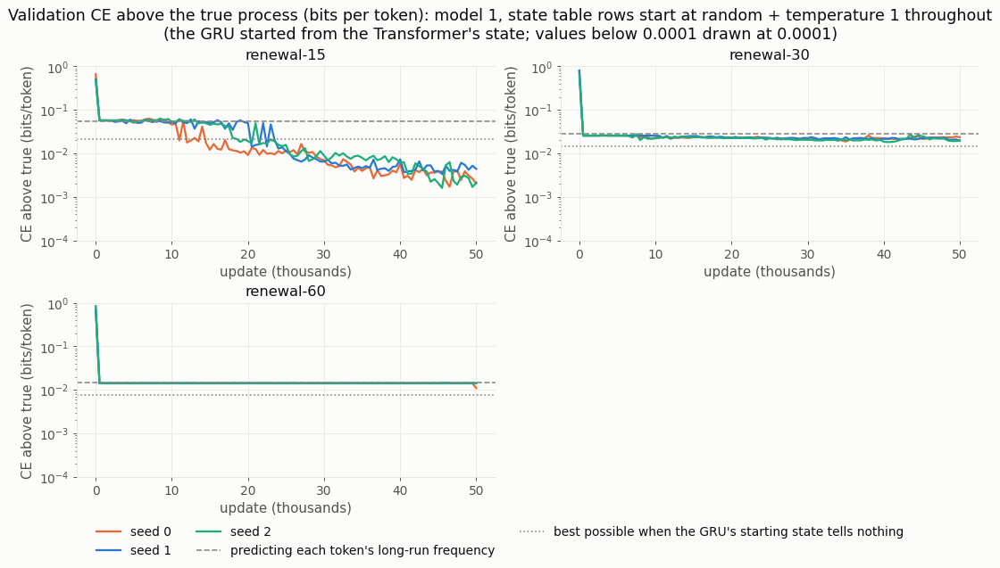

In [24]:
BEST = 'table_random+tau_const1'
final_jobs = [(BEST, N, s, R.FINAL_STEPS) for N in NS for s in R.SEEDS]
final = R.summary(final_jobs)
final["learned"] = (final.states_told_apart == final.N) & (final.gap_closed >= 0.9)
cols_final = ["N", "seed", "excess", "gap_closed", "states_told_apart", "learned", "best_excess", "best_update",
              "best_gap_closed", "best_states_told_apart", "long_excess", "machine_states", "handoff_codes",
              "handoff_information", "choice_locked_share", "encoder_classifier", "encoder_classifier_untrained",
              "first_50%_closed", "first_90%_closed"]
display(final[cols_final].set_index(["N", "seed"]).round(4))
fig = R.plot_curves({f"renewal-{N}": [(s, R.folder_of(BEST, N, s, R.FINAL_STEPS)) for s in R.SEEDS] for N in NS},
                    title=f"Validation CE above the true process (bits per token): model 1, {R.LABELS.get(BEST, BEST)}"
                          "\n(the GRU started from the Transformer's state; values below 0.0001 drawn at 0.0001)")
plt.show()

* **Renewal-15 is learned on all 3 seeds** (the runs of 6.4).
  * Excess 0.0026, 0.0044 and 0.0034 bits; gap closed 0.95, 0.92 and 0.94; all 15 true states told apart.
  * The GRU's machine has 15 long-run states. Over 200 future tokens its excess is 0.0008–0.0020.
  * The Transformer hands over 11–13 different states, which carry 73–87% of the information about the true state.
    A linear classifier reads the true state from its output vector on 99.8–100% of the test windows (44–64% for the
    Transformer as built).
  * The runs first closed 90% of the gap at updates 30,500–41,000, and their best parameters are at 45,500–46,500. So
    they were still improving near the end.
* **Renewal-30 is learned on no seed.**
  * Excess 0.026, 0.021 and 0.022 bits; gap closed 0.11, 0.27 and 0.25; 1–2 of the 30 true states told apart. No run
    closed half the gap at any point; the best parameters give 0.021 bits on each seed (gap closed 0.27).
  * **The Transformer has learned the count, but does not hand it over.** The linear classifier reads the true state
    from its output vector on 94%, 97% and 99.9% of the test windows (44%, 44% and 68% as built). But it hands the GRU
    only 6–7 different states, and these carry 12–39% of the information about the true state.
  * **The GRU does not count on its own.** Its machine has 1 long-run state, and over 200 future tokens its excess is
    0.028–0.030 bits, the level of remembering nothing (0.029). A GRU that counted exactly from the first 1 would reach
    0.015 even with a useless starting state (6.1's `handoff_useless`); the runs end above that.
  * On the validation windows the excess is 0.0257 (the level of remembering nothing there) from update 500 until
    update 7,000–11,000 (it is first below 0.025 at 8,000, 11,000 and 7,000). Its lowest values are 0.0188, 0.0197 and 0.0183, at updates 35,000, 50,000
    and 40,500. Between checks 500 updates apart it moves by up to 0.003–0.006, so the curves do not show whether more
    updates would help.
* **Renewal-60 is learned on no seed.**
  * Seeds 1 and 2 end at 0.0146 bits, the level of remembering nothing (0.0145): gap closed −0.005 and −0.004, 1 of
    the 60 true states told apart.
  * Seed 0 ends at 0.0119 bits (gap closed 0.18, 3 states told apart), and this came in its last 500 updates. Its
    validation excess was 0.0142–0.0143 at every check from update 500 to 49,500, and 0.0110 at 50,000.
  * **The Transformer hands the GRU the same state for every test window, on all three seeds**, so the handoff
    carries no information. The linear classifier reads the true state from its output vector on 45%, 31% and 51% of
    the test windows, against 27%, 32% and 36% as built: it has learned little of the count.
  * The GRU's machine has 1–2 long-run states. Over 200 future tokens its excess is 0.0148–0.0150, the level of
    remembering nothing.

**The machine each GRU learned.** The GRU's step rule, tried on every row of the state table, defines a machine: for
each state, the probability of each next token and the state it moves to after each token (`analysis.machine`, final
parameters).
* Drawn is the part the GRU keeps returning to, starting from the states the Transformer hands over. States that
  predict the same future are merged. States the GRU only passes through on the way are left out.
* Each learned state is named by the true states most often in it (a<c>: c zeros since the last 1), on the alignment
  windows.

Three figures:
1. the renewal-15 machines next to the true one;
2. the renewal-30 and renewal-60 machines (their true machines, with 30 and 60 states, are described, not drawn);
3. for every true state, the probability that the next token is a 1: in the true machine, 1 / (N − c), and in the
   learned state that the true state is most often in.

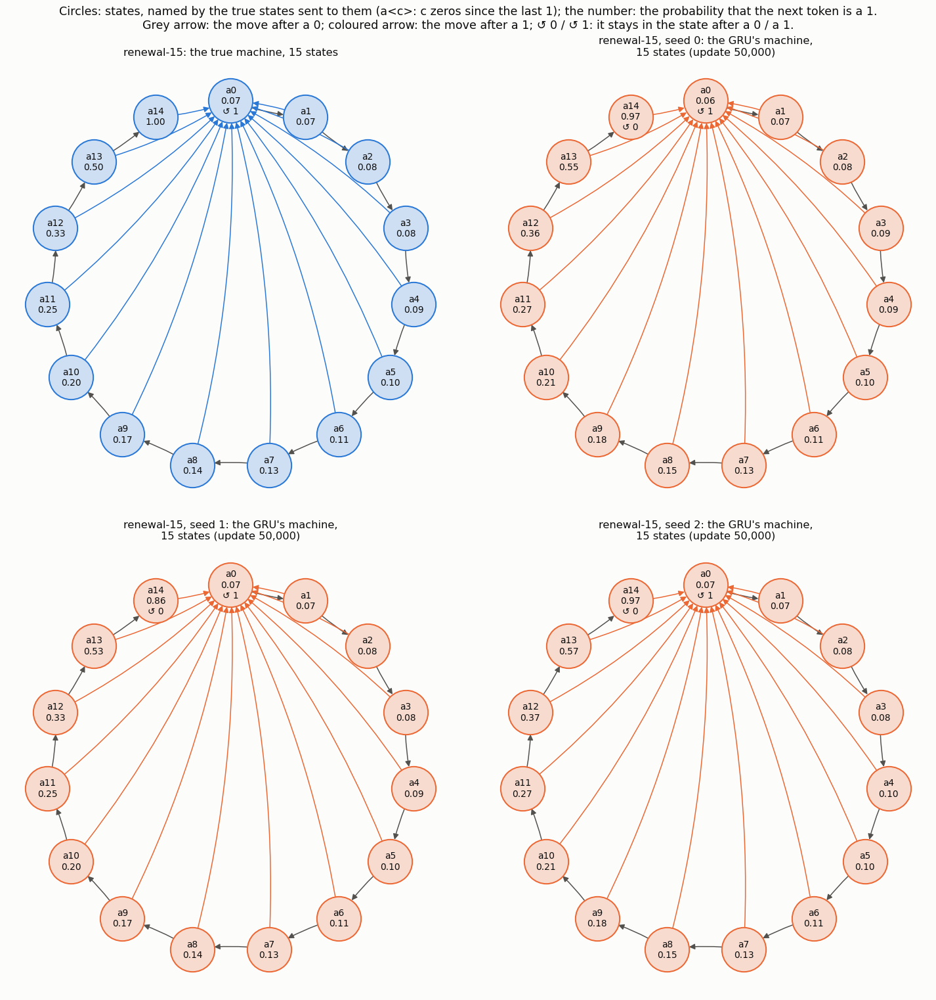

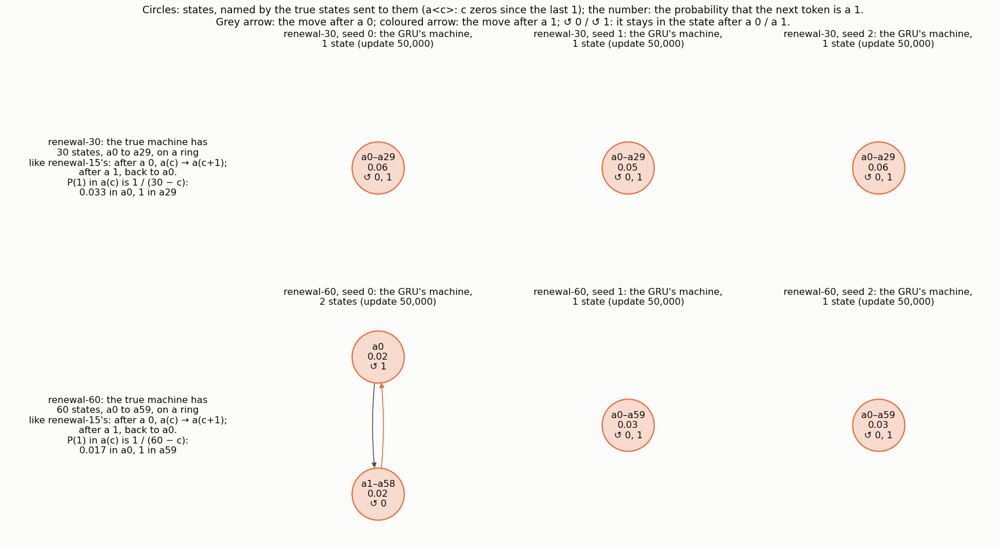

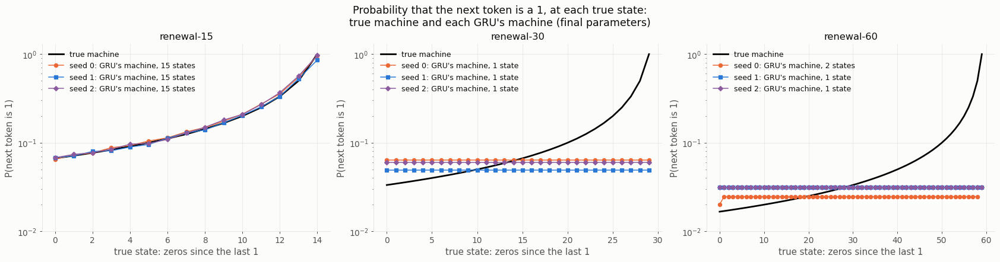

In [25]:
fig = R.plot_machines(BEST, (15,), ncols=2, panel=8); plt.show()
fig = R.plot_machines(BEST, (30, 60), panel=4.8); plt.show()
fig = R.plot_prob_of_one(BEST, NS); plt.show()

* **Renewal-15: each seed's GRU has learned the true machine.**
  * It has 15 states, one for each true state, and the same moves: after a 0 from a(c) to a(c+1), after a 1 back to
    a0 (checked for all 30 moves of each seed).
  * The probability of a 1 is on average within 0.012–0.013 of the true one. The largest differences, 0.05, 0.14 and
    0.07, are all at a14, where the true probability is 1 and the learned one 0.97, 0.86 and 0.97. So the learned a14
    also has a move after a 0 (it stays in a14), which the true process never produces.
  * The Transformer's starting state is already one of these 15 on 92–98% of the windows, and on all of them after
    one token.
* **Renewal-30: each seed's GRU has a single state.** It predicts a 1 with probability 0.063, 0.049 and 0.060
  whatever the history, close to the long-run rate of 1s, 2/31 = 0.065. So in the long run the GRU remembers
  nothing.
  * The Transformer's 6–7 starting states are passing states. The GRU leaves them for its single state after a median
    of 1, 4 and 1 tokens (at most 6, 24 and 15).
  * A single state cannot do better than remembering nothing. So the 11–27% of the gap that renewal-30 closes on the
    test windows (6.5) can only come from these passing states.
* **Renewal-60, seeds 1 and 2: a single state**, with probability 0.031 of a 1 (long-run rate 2/61 = 0.033). The
  Transformer hands over one starting state, which the GRU leaves after 1 token.
* **Renewal-60, seed 0: two states.**
  * a0 (just after a 1): probability 0.020 of a 1. a1–a58: probability 0.025.
  * After a 1 it goes to a0, after a 0 to a1–a58. It tells apart only whether the last token was a 1.
  * True state a59 does not occur while the GRU is in these two states.

### 6.6 Gradient and loss over the whole training
As section 4.4: for each run, the gradient length reaching the whole Transformer and the whole GRU at every update
(left axis, log scale) and the training loss (right axis), each point the median gradient and the mean loss of the 250
updates up to it. The grey lines are the training loss of the true probabilities and of remembering nothing (6.1's
table). One figure per process.

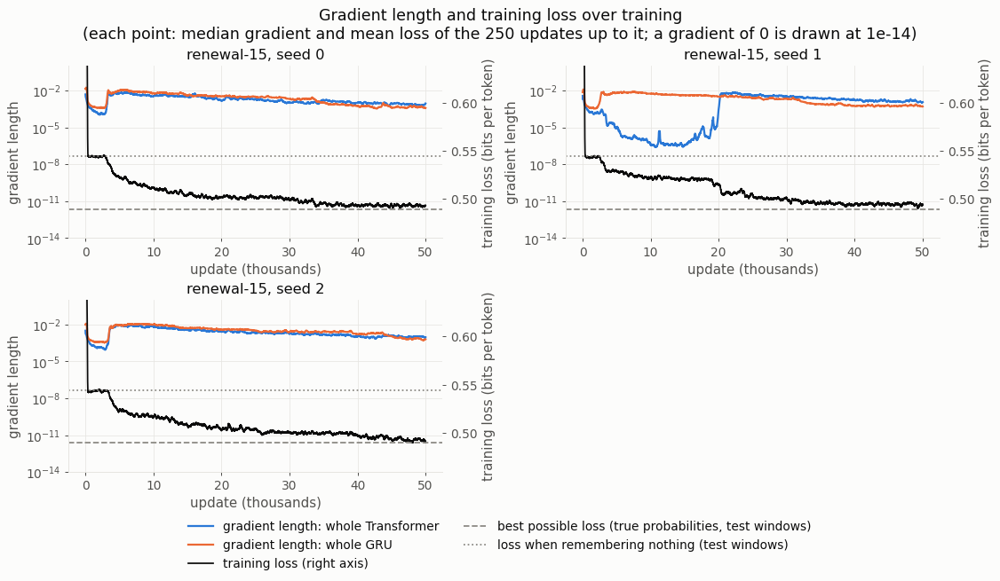

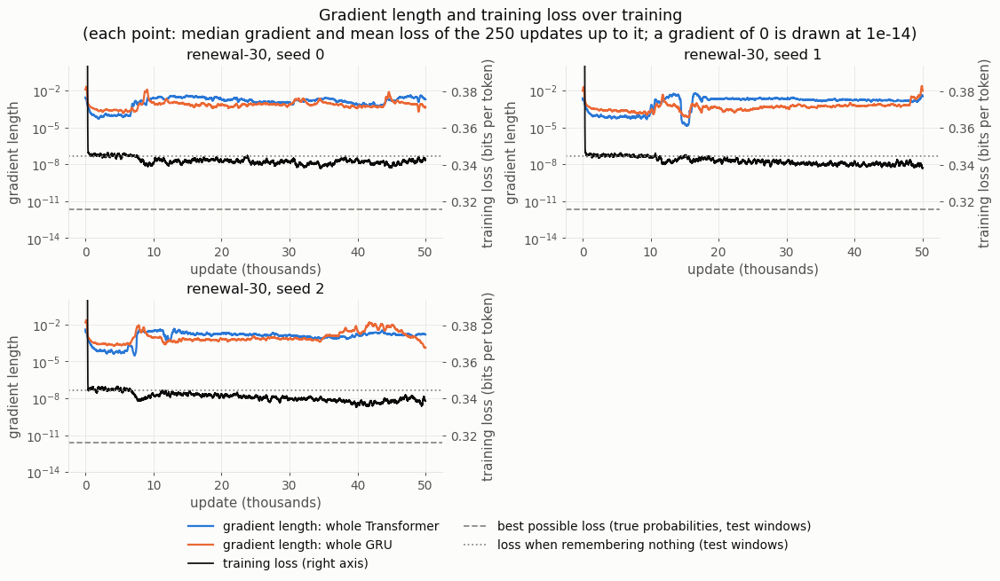

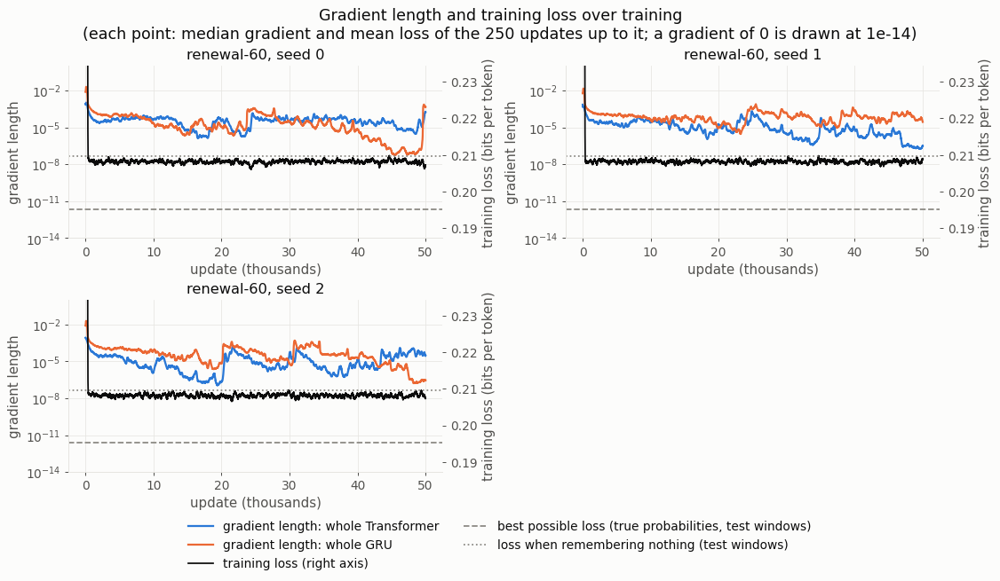

In [26]:
for N in NS:
    fig = R.plot_whole_training({f"renewal-{N}, seed {s}": (R.steps_and_trace(BEST, N, s, R.FINAL_STEPS)[0], N)
                                 for s in R.SEEDS}); plt.show()

* **Renewal-15.** The training loss falls from 0.63–0.67 to the level of remembering nothing (0.545) within the first
  few hundred updates. It leaves that level (0.005 below it) at updates 2,700–3,500 and ends at 0.492–0.494 (mean of
  the last 250 updates; best possible 0.490).
  * On that plateau, at updates 1,000–2,000, the gradients are at their smallest: median 1.5e-4–1.7e-4 for the whole
    Transformer and 3.8e-4–4.3e-4 for the whole GRU.
  * When the loss leaves it they grow 20–50 times. At updates 5,000–6,000 the median is 6.6e-3 and 7.8e-3 for the
    Transformer (seeds 0 and 2), and 7.0e-3–1.1e-2 for the GRU. Then they fall slowly, to 7e-4–1.2e-3 (Transformer)
    and 4e-4–6e-4 (GRU) at the end.
  * Seed 1 is the exception. Its Transformer's gradient is below 1e-6 on 7,007 updates between 5,114 and 18,777
    (smallest 2.2e-8, at 14,493), while its GRU's stays at about 5e-3 (median). By update 20,000 the Transformer's
    gradient is back at 4e-3. 6.7 shows why it was small.
  * No update of the three runs has a gradient above 1, the clipping length, for either part.
* **Renewal-30.** The loss also reaches the level of remembering nothing (0.345) within a few hundred updates, but
  stays close to it to the end.
  * It is 0.005 below that level only from update 8,800, 26,700 and 7,600 (seeds 0, 1, 2). At the end it is
    0.338–0.342 (best possible 0.316), so it has removed about a fifth of the gap.
  * The Transformer's gradient is small on the plateau (median 6e-5 to 9e-5 at updates 1,000–6,000). From about update
    8,000–10,000 it is 1e-3 to 3e-3 until the end, and it is never below 1.5e-6. The GRU's is 2e-4 to 2e-3 throughout.
  * So, unlike section 4.4's runs, renewal-30 fails without its gradient dying.
  * A few updates have a gradient above 1: 0, 1 and 2 for the Transformer and 3, 8 and 10 for the GRU, out of 50,000.
* **Renewal-60.** The loss reaches 0.208 within the first 1,000 updates and stays there to the end on all three
  seeds (each 1,000-update block averages 0.207–0.209; best possible 0.195). The grey dotted line, 0.210, is the
  level of remembering nothing on the test windows; the test excess at the end (6.5) shows the runs are at that level.
  * The gradients stay small throughout. From update 1,000 the median is 3.4e-5, 8.3e-6 and 7.6e-6 for the whole
    Transformer (seeds 0, 1, 2) and 1.7e-5, 6.9e-5 and 3.7e-5 for the whole GRU: about 100 times smaller than on
    renewal-30 after its plateau.
  * They fall below 1e-6 for long stretches, but never to 0. The Transformer's is below 1e-6 on 493, 6,343 and 7,953
    updates (smallest 1.4e-7, 1.8e-8, 9.3e-9); the GRU's on 7,100, 14 and 2,637 (smallest 9.0e-9, 5.1e-7, 1.8e-8).
  * Seed 0's GRU gradient was about 1e-7 from update 45,000 to 49,500 (medians of 500-update blocks: 6e-8 to 3e-7).
    At updates 49,512–49,550 it rose to 6e-4–1e-3, and its validation excess then fell from 0.0142 to 0.0110 (the
    check at 50,000). What started this was not found.
  * No update has a gradient above 1 for either part.

### 6.7 The Transformer's choice over training
As section 4.4's choice figure: every 250 updates, on 128 windows not used for training, the gradient length arriving
at the state vector the Transformer hands to the GRU (black), the gradient left after the choice, at the Transformer's
K scores (purple), and the fraction of the 128 windows whose picked state has q above 0.999 (dashed, right axis; then
almost no gradient passes the choice).

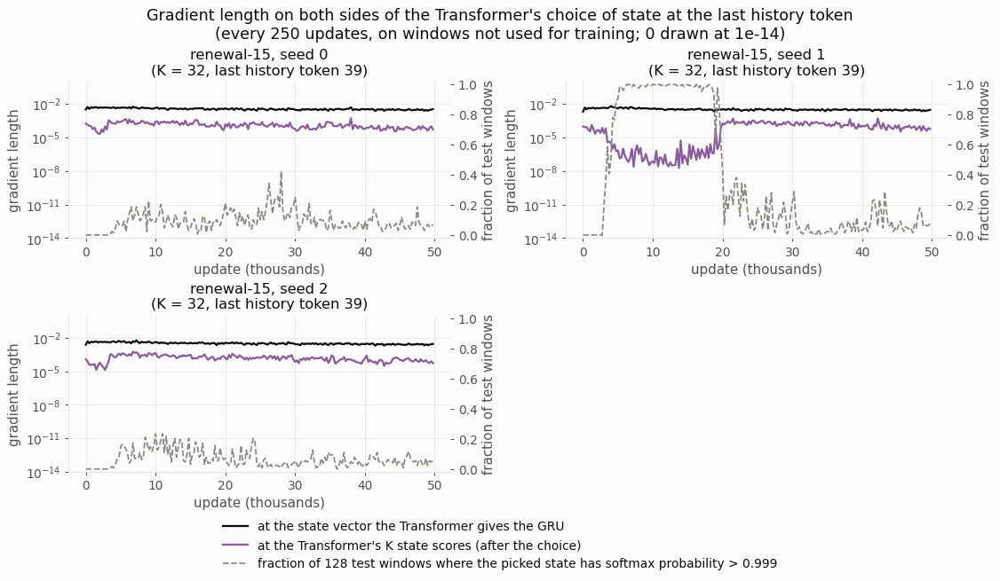

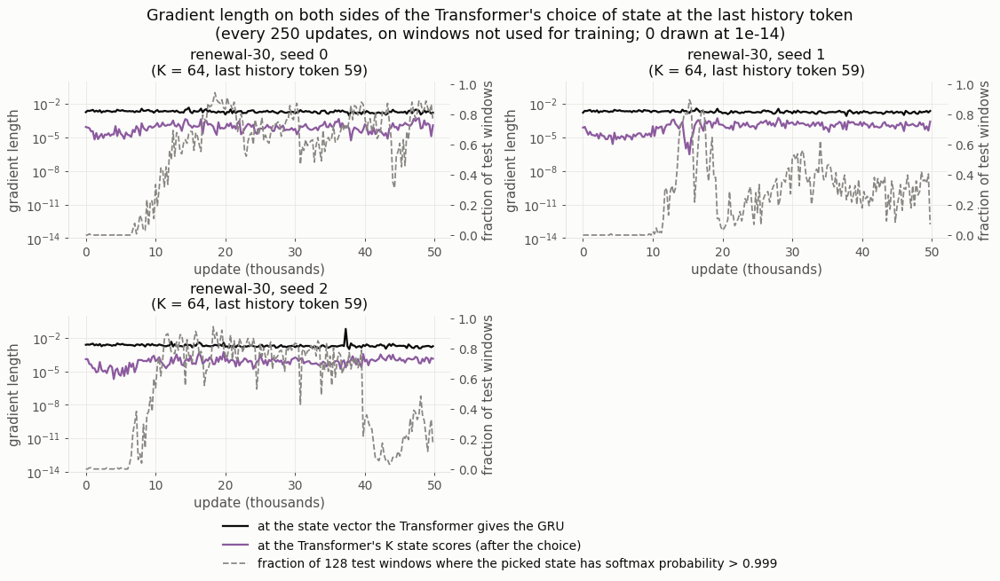

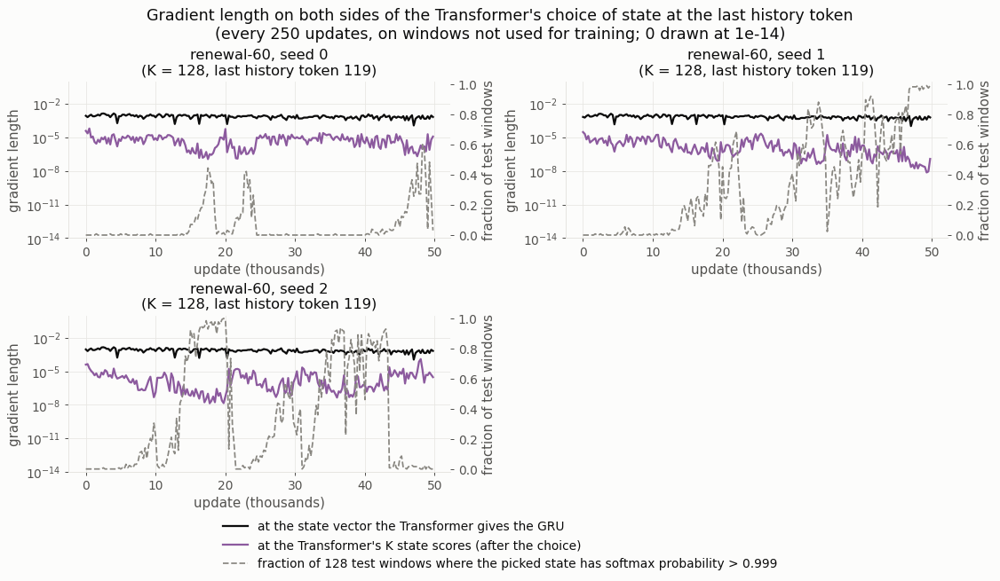

In [27]:
for N in NS:
    fig = R.plot_choice_over_training({f"renewal-{N}, seed {s}": (R.steps_and_trace(BEST, N, s, R.FINAL_STEPS)[1],
                                                                 R.settings_of(BEST, N, s, R.FINAL_STEPS))
                                       for s in R.SEEDS}); plt.show()

* **Renewal-15, seeds 0 and 2: the choice never becomes fixed on most windows.** It is fixed on at most 42% and 23%
  of the 128 windows, and on 5–7% at the end. The gradient after the choice stays at 1.3e-5 or more.
* **Renewal-15, seed 1: the choice was fixed and then came undone.**
  * From update 3,500 to 19,750 it is fixed on more than half the windows (on all of them at 6,250). The gradient
    after the choice falls to 1.9e-8, and the Transformer uses 1 state on the validation windows at every check from
    update 3,500 to 18,500.
  * The GRU kept learning meanwhile: the number of its own states it uses rose from 5 at update 3,000 to 12 at 18,000.
  * At about update 19,000 the choice came undone. The Transformer then used 2, 3 and 6 states (updates 19,000,
    20,000, 21,000) and 10 at 26,000, where the validation excess is 0.0076. The run went on to learn the process.
  * So at temperature 1 a fixed choice can come undone. What undid it here was not found.
* **Renewal-30: the choice becomes fixed on most windows and stays so for long stretches.**
  * It is fixed on more than half the windows at 145, 23 and 118 of the 200 measuring points (seeds 0, 1, 2), on up
    to 95%, 90% and 95% of them. At the end it is fixed on 76%, 7% and 16%.
  * The gradient after the choice gets down to 5.4e-6, 3.0e-7 and 2.1e-6, but the gradient arriving at the state
    vector stays at about 1e-3 to 3e-3.
  * This matches 6.5: the Transformer's output tells the count, but its choice gives the GRU only 6–7 states.
* **Renewal-60: the Transformer gives every window the same state, whether or not its choice is fixed.**
  * On the validation windows it uses 1 state at 82, 94 and 100 of the 100 checks (seeds 0, 1, 2).
  * How fixed that one choice is varies: it is fixed on more than half the 128 windows at 2, 65 and 66 of the 200
    measuring points, and at the end on 3%, 99% and 0%.
  * The gradient arriving at the state vector is 4e-4 to 1e-3, about half of renewal-30's. The gradient after the
    choice gets down to 1.1e-7, 7.3e-9 and 1.4e-8.
  * So the single state is not caused by a fixed choice: seed 2 ends with the choice fixed on no window and still
    hands over one state. Its scores put the same state first for every window.

### 6.8 The gradient at the starting points
As in section 4.2, for each process at the chosen settings: the gradient length before the first update, at 200
starting points.
* A starting point is the set of values all the weights have before the first update. Seed s gives one (torch seed
  17 + s), the one a training run with seed s starts from; the 200 are seeds 0–199. In the histograms, the height of
  a bar is the number of seeds whose gradient length falls in that bar's range, so each colour adds up to 200.
* All are at the starting temperature 1, and all use the same 512 windows with the same noise.
* It is measured twice: with the state table as built (all rows equal), and with its rows drawn at random.

With random rows, seeds 0–2 start from exactly the table their training runs in 6.5 started from (checked). So the
last table places the three trained runs among the 200.

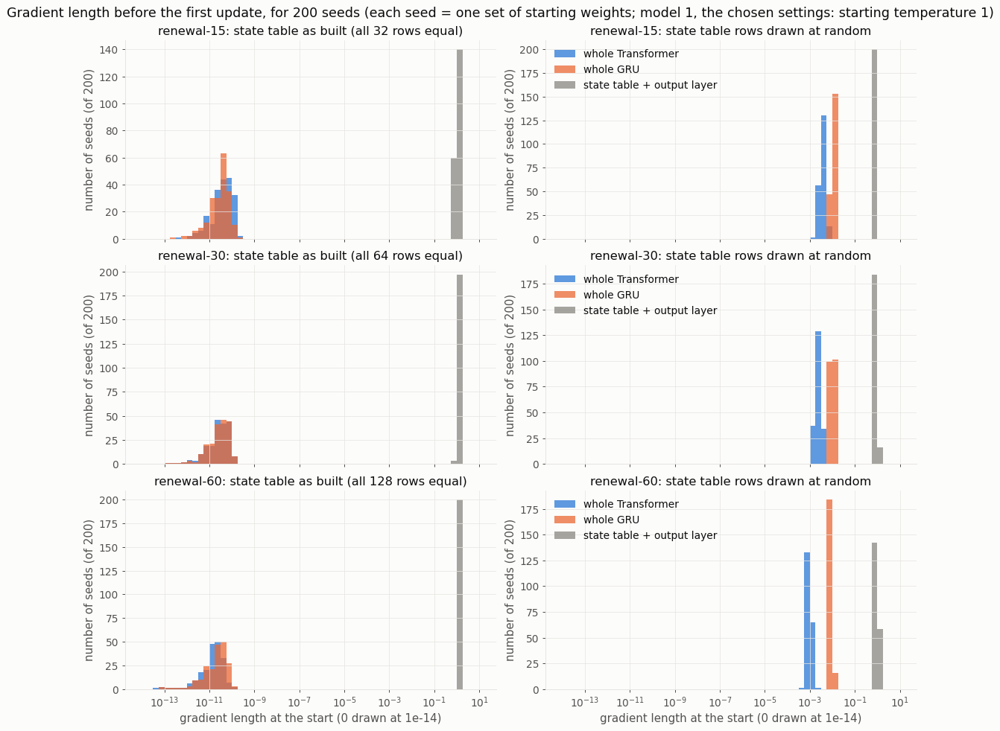

smallest   median  largest
process    table_start part                                   
renewal-15 equal       transformer   3.5e-13  4.5e-11  1.9e-10
                       gru           2.0e-13  3.4e-11  2.1e-10
                       table_output  6.5e-01  1.1e+00  1.5e+00
           random      transformer   1.5e-03  3.7e-03  9.0e-03
                       gru           5.7e-03  1.1e-02  1.8e-02
                       table_output  6.3e-01  7.7e-01  9.6e-01
renewal-30 equal       transformer   1.6e-13  3.0e-11  1.3e-10
                       gru           1.4e-13  3.1e-11  1.7e-10
                       table_output  9.6e-01  1.3e+00  1.6e+00
           random      transformer   1.2e-03  2.2e-03  4.9e-03
                       gru           6.4e-03  1.0e-02  1.6e-02
                       table_output  7.3e-01  9.1e-01  1.1e+00
renewal-60 equal       transformer   4.2e-14  1.6e-11  1.1e-10
                       gru           7.7e-14  2.5e-11  1.3e-10
                       table_output  1.0e+00  1.3e+00  1.7e+00
           random      transformer   5.5e-04  8.9e-04  2.0e-03
                       gru           5.8e-03  8.0e-03  1.1e-02
                       table_output  8.0e-01  9.5e-01  1.1e+00

,median_transformer,median_gru,median_table_output
renewal-15,1.7e-03,5.5e-03,7.7e-01
renewal-30,1.0e-03,4.8e-03,9.1e-01
renewal-60,3.9e-04,3.8e-03,9.5e-01


transformer  transformer_rank      gru  gru_rank table_output  table_output_rank  learned   excess
N  seed                                                                                                   
15 0        5.2e-03               176  1.4e-02       183      8.8e-01                186     True  2.6e-03
   1        3.7e-03               100  7.5e-03         5      8.1e-01                131     True  4.4e-03
   2        3.2e-03                56  1.1e-02        67      7.4e-01                 69     True  3.4e-03
30 0        2.6e-03               134  1.2e-02       162      9.4e-01                127    False  2.6e-02
   1        2.2e-03                91  9.4e-03        62      9.7e-01                168    False  2.1e-02
   2        3.8e-03               190  1.4e-02       197      9.4e-01                135    False  2.2e-02
60 0        7.8e-04                51  7.9e-03        96      9.9e-01                130    False  1.2e-02
   1        7.4e-04                41  6.1e-03         4      8.6e-01                 21    False  1.5e-02
   2        8.4e-04                80  8.2e-03       115      9.6e-01                110    False  1.5e-02

In [28]:
starts = {N: R.start_gradients(BEST, N) for N in NS}
fig = R.plot_start_gradients(starts, BEST, title="the chosen settings: starting temperature 1"); plt.show()
rows = []
for N, d in starts.items():
    for start, g in d.groupby("start"):
        for part in ("transformer", "gru", "table_output"):
            rows.append(dict(process=f"renewal-{N}", table_start=start, part=part, smallest=g[part].min(),
                             median=g[part].median(), largest=g[part].max()))
display(sci(pd.DataFrame(rows).set_index(["process", "table_start", "part"])))
# section 16's settings (starting temperature 2.5), random rows, for comparison
display(sci(pd.DataFrame({f"renewal-{N}": R.start_gradients("default", N).query("start == 'random'")
                          [["transformer", "gru", "table_output"]].median() for N in NS}).T.add_prefix("median_")))
# the three trained runs' own starting points (random rows), their rank among the 200 (1 = smallest), and whether
# the run learned its process (6.5)
ranks = pd.concat([R.start_ranks(BEST, N) for N in NS]).merge(final[["N", "seed", "learned", "excess"]], on=["N", "seed"])
display(sci(ranks.set_index(["N", "seed"])))

* **With the table as built, the start is flat for the Transformer and the GRU at every N, also at temperature 1.**
  At all 200 starting points, the gradient reaching the whole Transformer is at most 1.9e-10 (renewal-15), 1.3e-10
  (renewal-30) and 1.1e-10 (renewal-60). The gradient reaching the whole GRU is at most 2.1e-10. Only the state table
  and the output layer get a gradient (0.65–1.7).
* **With random rows, both get a gradient at every starting point.**
  * The whole GRU: 5.7e-3 to 1.8e-2 (median 1.1e-2, 1.0e-2 and 8.0e-3 for N = 15, 30, 60).
  * The whole Transformer: smaller as N grows, median 3.7e-3, 2.2e-3 and 8.9e-4.

  Both are about twice the values at section 16's settings, whose starting temperature is 2.5 (Transformer median
  1.7e-3, 1.0e-3 and 3.9e-4; GRU 5.5e-3, 4.8e-3 and 3.8e-3).
* **No starting point stands out.** With random rows, the 200 values of each part lie within a factor of 6 of each
  other (for the Transformer: 6.0, 4.1 and 3.6 for N = 15, 30, 60).
* **Where the trained runs started does not separate their outcomes.** The three trained runs of each process started
  at ranks 41–190 of the 200 for the Transformer and 4–197 for the GRU (last table). Within each process the three
  seeds ended alike: all learned renewal-15, none learned renewal-30 or renewal-60. Renewal-15 seed 1, whose choice
  stayed fixed from update 3,500 to 19,750 (6.7), has the 5th smallest GRU gradient of the 200. One run is too few to
  tie the two.

### 6.9 Findings


* **With the best settings found, model 1 learns renewal-15 but not renewal-30 or renewal-60 in 50,000 updates.**
  * The settings are section 16's with random table rows and the temperature held at 1 (6.4). Of the 29
    configurations tried on renewal-15, they are the only one that learned it at the end of training on more than one
    seed: 3 of 3, 0.0026–0.0044 bits, 92–95% of the gap closed, all 15 states told apart. Each seed's GRU has the true
    15-state machine (6.5).
  * Renewal-30: 11–27% of the gap closed and 1–2 of the 30 states told apart, on all 3 seeds.
  * Renewal-60: seeds 1 and 2 are no better than remembering nothing. Seed 0 closed 18% of the gap, all of it in its
    last 500 updates.
* **On renewal-30 the Transformer learns the count, but its choice does not pass it on.** A linear classifier reads
  the true state from its output vector on 94–99.9% of the test windows. Yet it hands the GRU only 6–7 states, with
  12–39% of the information, and its choice is fixed on up to 90–95% of the windows during training. The GRU does not
  learn to count on its own: its machine has a single state.
* **On renewal-60 neither part learns.** The Transformer hands every window the same state. Its output tells the true
  state only a little better than as built (31–51% against 27–36%). The training loss stays at the level of
  remembering nothing. The gradients stay about 100 times smaller than on renewal-30 and fall below 1e-6 for
  thousands of updates, but never reach 0.
* **The failures do not come from the start.** With random table rows, every one of the 200 starting points gives
  both parts a gradient (Transformer median 3.7e-3, 2.2e-3 and 8.9e-4; GRU 1.1e-2, 1.0e-2 and 8.0e-3 for N = 15, 30,
  60). The trained seeds' ranks among the 200 do not separate the outcomes. With the table as built (equal rows) the
  start is flat at every N.
* **Over training, the loss first sits at the level of remembering nothing for every N.** Renewal-15 leaves it at
  updates 2,700–3,500, renewal-30 at 7,600–26,700 and only by about a fifth of the gap, renewal-60 never (except seed
  0 at the very end).
* **Not tested here** (section 7 tests the first two on renewal-30):
  * more than 50,000 updates (renewal-15 needed 30,500–41,000 to close 90% of its gap, and renewal-60 seed 0 began
    to move at 49,500);
  * a search on renewal-30 or renewal-60 itself;
  * a learning rate that falls during training.

## 7. Extensive learning for the hybrid model: renewal-30

### 7.1 The question, and one new measurement
**The question.** Section 6's chosen settings (random table rows, temperature held at 1) learn renewal-15 on 3 of 3
seeds, but in 50,000 updates they close only 11–27% of renewal-30's gap (6.5). There are two possible reasons, and
this section tests each:
1. **Too few updates.** Renewal-15 needed 30,500–41,000 updates to close 90% of its gap. 7.2 trains the same settings
   on renewal-30 for 150,000 updates, three times as long (and 7.6 the best renewal-30 settings).
2. **Settings chosen on the wrong process.** The search of 6.3–6.4 was run on renewal-15. 7.3 repeats it on
   renewal-30: section 16's settings, the original setup and the same 20 single changes, 3 seeds, 50,000 updates (66
   runs). 7.4 pairs the changes that help, as 6.4 did, 7.5 shows the best renewal-30 settings with the same
   graphs as 7.2, and 7.6 trains them for 150,000 updates.

7.7 gives the findings.

Window sizes, reference levels and the rule for "learned" are 6.1's for renewal-30:
* 60 history + 30 future tokens, 64 table rows;
* "remembers nothing" is 0.0289 bits;
* a run has learned when its GRU tells all 30 true states apart and closes at least 90% of the gap.

Every run is recorded as in section 6.

**One new measurement: the GRU read the way it is trained** (`renewal_check.sampled_excess`).
* In training with noise in the choice (section 16's settings), every state is drawn at random: state k with
  probability softmax(scores)_k. This is the noise of the
  introduction's "choice and q"; the temperature changes only the gradient, never the draw.
* Every test result so far takes the highest-scoring state instead. That makes the GRU a fixed machine, which can be
  drawn (6.5).
* `sampled_excess` runs the GRU on the test windows with each next state drawn as in training (mean of 3 draws). The
  Transformer's starting state is still the highest score. The training loss is this drawn reading, on the training
  windows.

### 7.2 The chosen settings for 150,000 updates
Section 6's chosen settings on renewal-30: 3 seeds, 150,000 updates. Nothing else changes. The temperature is 1
throughout and the learning rate is constant, so the first 50,000 updates are 6.5's runs exactly (their validation
values at updates 5,000, 10,000 and 50,000 are identical). Each run took 674–683 minutes, 3 at a time.

The table has 6.5's columns, followed by the validation curves (the highest-score reading, as everywhere before).

excess  gap_closed  states_told_apart  learned  best_excess  best_update  best_gap_closed  best_states_told_apart  long_excess  machine_states  handoff_codes  handoff_information  choice_locked_share  \
N  seed                                                                                                                                                                                                            
30 0     0.0253      0.1247                  1    False       0.0187       100000           0.3512                       5       0.0317               1              9               0.3907               0.2002   
   1     0.0261      0.0943                  2    False       0.0213        64000           0.2616                       1       0.0420               1             12               0.6434               0.0918   
   2     0.0248      0.1389                  1    False       0.0201       115500           0.3046                       1       0.0335               1             10               0.4664               0.3418   

         encoder_classifier  encoder_classifier_untrained first_50%_closed first_90%_closed  
N  seed                                                                                      
30 0                 0.9531                        0.4377             None             None  
   1                 0.9993                        0.4414             None             None  
   2                 0.9897                        0.6826             None             None

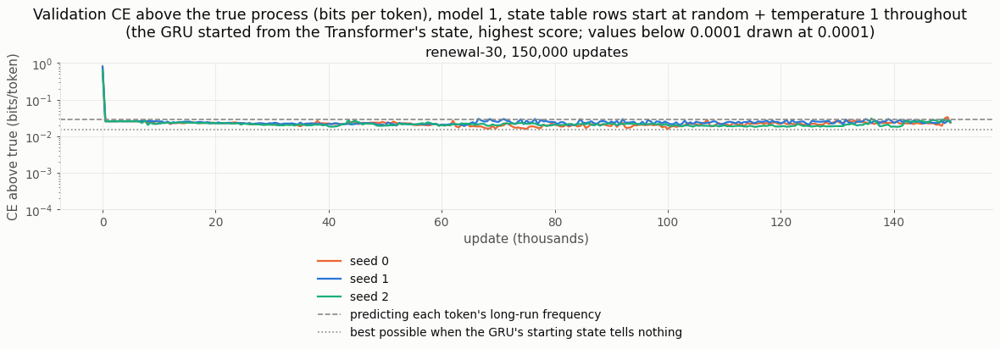

In [29]:
LONG = 150_000
long_jobs = [(BEST, 30, s, LONG) for s in R.SEEDS]
long = R.summary(long_jobs)
long["learned"] = (long.states_told_apart == long.N) & (long.gap_closed >= 0.9)
display(long[cols_final].set_index(["N", "seed"]).round(4))
fig = R.plot_curves({"renewal-30, 150,000 updates": [(s, R.folder_of(BEST, 30, s, LONG)) for s in R.SEEDS]},
                    title=f"Validation CE above the true process (bits per token), model 1, {R.LABELS[BEST]}\n"
                          "(the GRU started from the Transformer's state, highest score; values below 0.0001 drawn at "
                          "0.0001)", width=13, height=4.5)
plt.show()

* **Three times as many updates do not learn renewal-30.** At update 150,000:
  * the excess is 0.0253, 0.0261 and 0.0248 bits (gap closed 0.12, 0.09 and 0.14);
  * 1, 2 and 1 of the 30 true states are told apart.

  At update 50,000 (6.5) it was 0.026, 0.021 and 0.022.
* **The best parameters improve a little on two seeds.** Their test excess is 0.0187 (update 100,000), 0.0213 (64,000)
  and 0.0201 (115,500). That is a gap closed of 0.35, 0.26 and 0.30, against 0.27 at 6.5's best. Seed 0 tells 5 states
  apart there; seeds 1 and 2 tell 1.
* **On the validation windows no run reaches half the gap.**
  * The lowest values are 0.0158 (update 100,000), 0.0193 (64,000) and 0.0180 (115,500).
  * Seed 0 is below 0.02 at 62 of the 301 checks, seed 1 at 5, seed 2 at 100.
  * After update 10,000, the value moves between neighbouring checks (500 updates apart) by a median of
    0.0006–0.0011 bits, and by 0.0025–0.0053 at the 95th percentile.
* **The Transformer hands over more than at 50,000 updates:**
  * 9, 12 and 10 different states (6–7 at 50,000);
  * they carry 39%, 64% and 47% of the information about the true state (12–39%);
  * a linear classifier still reads the true state from its output vector on 95%, 99.9% and 99% of the test windows.
* **The GRU, read with the highest score, ends up worse than remembering nothing in the long run.**
  * Its machine has 1 long-run state on every seed. That state's P(1) is 0.047, 0.034 and 0.044: below the long-run
    rate of 1s (2/31 = 0.065), and lower than at update 50,000 (0.063, 0.049 and 0.060).
  * Over 200 future tokens its excess is 0.032, 0.042 and 0.034 bits, against 0.029 for remembering nothing.

**The two readings of the GRU.** The first table compares the two readings at the final parameters and at those with
the best validation value. It covers these runs and 6.5's 50,000-update runs on the three processes. The columns:
* `excess_highest`: the GRU takes the highest-scoring state at every step, as in every test result;
* `excess_drawn`: it draws each next state as in training (mean of 3 draws);
* `drawn_differs`: the fraction of the GRU's steps whose drawn state is not the highest-scoring one;
* `training_loss_excess`: the training loss of the last 250 updates minus the best possible loss (final parameters
  only).

The figure gives, for each true state of the future tokens, the mean predicted probability of a 1 under both readings
(150,000 updates, final parameters).

update  excess_highest  excess_drawn  gap_closed_highest  gap_closed_drawn  drawn_differs  training_loss_excess
run_updates N  seed parameters                                                                                                                 
150000      30 0    final       150000          0.0253        0.0181              0.1247            0.3717         0.1655                0.0187
                    best        100000          0.0187        0.0180              0.3512            0.3770         0.0239                   NaN
               1    final       150000          0.0261        0.0106              0.0943            0.6338         0.3458                0.0103
                    best         64000          0.0213        0.0223              0.2616            0.2285         0.0041                   NaN
               2    final       150000          0.0248        0.0156              0.1389            0.4596         0.1799                0.0166
                    best        115500          0.0201        0.0198              0.3046            0.3126         0.0193                   NaN
50000       15 0    final        50000          0.0026        0.0032              0.9534            0.9413         0.0103                0.0039
                    best         46500          0.0034        0.0046              0.9377            0.9165         0.0209                   NaN
               1    final        50000          0.0044        0.0056              0.9197            0.8984         0.0226                0.0045
                    best         45500          0.0043        0.0051              0.9208            0.9073         0.0123                   NaN
               2    final        50000          0.0034        0.0047              0.9384            0.9148         0.0197                0.0018
                    best         45500          0.0031        0.0046              0.9430            0.9154         0.0214                   NaN
            30 0    final        50000          0.0258        0.0252              0.1068            0.1267         0.0016                0.0265
                    best         35000          0.0210        0.0223              0.2712            0.2277         0.0052                   NaN
               1    final        50000          0.0210        0.0211              0.2710            0.2702         0.0461                0.0223
                    best         50000          0.0210        0.0211              0.2710            0.2702         0.0461                   NaN
               2    final        50000          0.0217        0.0218              0.2465            0.2442         0.0001                0.0230
                    best         40500          0.0210        0.0207              0.2722            0.2835         0.0180                   NaN
            60 0    final        50000          0.0119        0.0127              0.1805            0.1227         0.0067                0.0120
                    best         50000          0.0119        0.0127              0.1805            0.1227         0.0067                   NaN
               1    final        50000          0.0146        0.0146             -0.0053           -0.0052         0.0001                0.0135
                    best         38000          0.0143        0.0143              0.0142            0.0120         0.0055                   NaN
               2    final        50000          0.0146        0.0146             -0.0044           -0.0044         0.0000                0.0121
                    best         33500          0.0142        0.0142              0.0179            0.0187         0.0057                   NaN

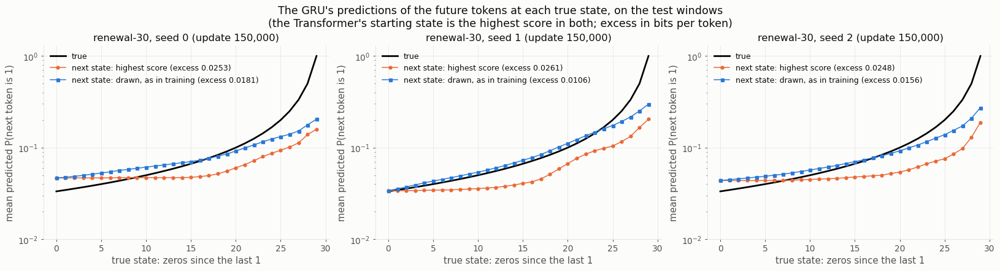

In [30]:
lv = {N: R.levels(N) for N in NS}


def readings(jobs):
    rows = []
    for name, N, s, steps in jobs:
        st = R.steps_and_trace(name, N, s, steps)[0]
        for which in ("latest", "best"):
            d = R.sampled_excess(name, N, s, steps, which)
            rows.append(dict(config=name, run_updates=R.steps_for(name, steps), N=N, seed=s,
                             parameters="final" if which == "latest" else "best",
                             update=d["update"], excess_highest=d["excess_highest"], excess_drawn=d["excess_sampled"],
                             gap_closed_highest=1 - d["excess_highest"] / lv[N]["remembers_nothing"],
                             gap_closed_drawn=1 - d["excess_sampled"] / lv[N]["remembers_nothing"],
                             drawn_differs=d["differs"],
                             training_loss_excess=(st.loss.iloc[-250:].mean() - lv[N]["best_loss"]
                                                   if which == "latest" else None)))
    return pd.DataFrame(rows)


display(readings(long_jobs + [(BEST, N, s, R.FINAL_STEPS) for N in NS for s in R.SEEDS])
        .set_index(["run_updates", "N", "seed", "parameters"]).drop(columns="config").round(4))
fig = R.plot_sampled(BEST, 30, steps=LONG); plt.show()

* **Read the way it is trained, the GRU closes 37%, 63% and 46% of the gap at update 150,000.**
  * With each next state drawn, the excess is 0.0181, 0.0106 and 0.0156 bits; with the highest score it is 0.0253,
    0.0261 and 0.0248.
  * The drawn state differs from the highest-scoring one on 17%, 35% and 18% of the GRU's steps.
  * Drawing the Transformer's starting state as well changes the excess by at most 0.0001 bits (checked separately).
    So the difference is in the GRU.
* **The drawn reading is what the training loss measures.** In the last 250 updates the training loss is 0.0187,
  0.0103 and 0.0166 bits above the best possible (measured on the test windows).
  * That is within 0.001 bits of the drawn values on the test windows, and far below the highest-score values.
  * A 250-update mean is noisy: on 6.5's runs it differs from the drawn value by up to 0.003 bits.
* **The two readings split late in training.**
  * At update 50,000 (6.5's runs) they are within 0.0006 bits on every seed.
  * At the 150,000-update runs' best parameters (updates 100,000, 64,000 and 115,500) they are within 0.0010.
  * On renewal-15 the drawn reading is 0.0006–0.0013 bits worse than the highest score at the final parameters.
    On renewal-60 it is equal, or 0.0008 worse.
* **What the drawn GRU does: its prediction follows the count only on average.**
  * With the highest score, the predicted P(1) is flat over the first counts. For seed 1 it is 0.034 at counts 0–5,
    0.036 at 10 and 0.041 at 15, and it rises only after that (0.204 at count 29).
  * With each next state drawn, it rises steadily: 0.034, 0.043, 0.054, 0.073, 0.111, 0.174 and 0.298 at counts 0, 5,
    10, 15, 20, 25 and 29. The true values are 0.033, 0.040, 0.050, 0.067, 0.100, 0.200 and 1.
  * So the further the count, the more often the random draws have moved the GRU on to states with a higher P(1). It
    does not have one state per count.
  * 6.1's rule, which reads the states with the highest score, does not count it as learned. Even drawn, it is well
    below the true probability after count 20.

**Gradient and loss over the whole training** (as 6.6), and **the Transformer's choice over training** (as 6.7).

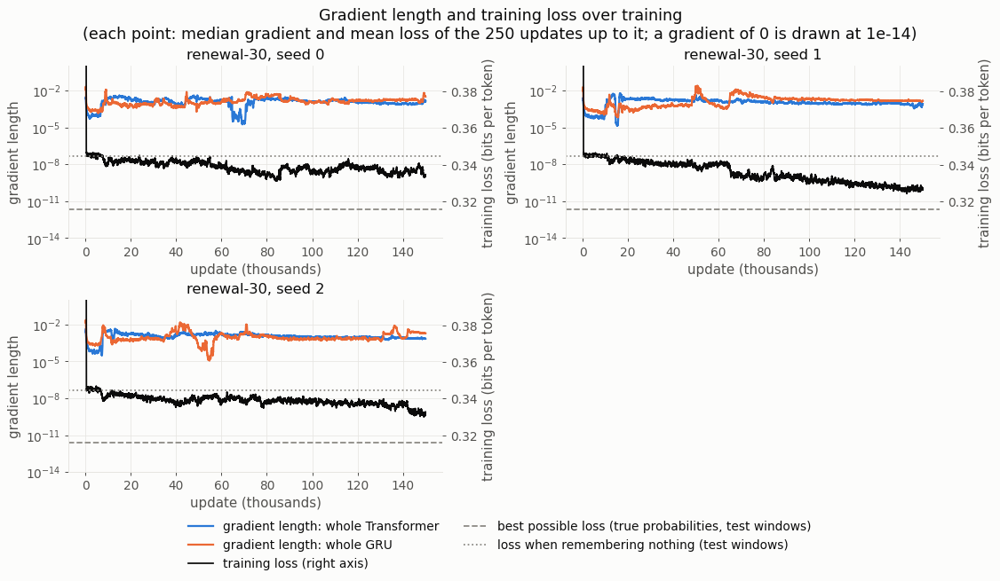

In [31]:
fig = R.plot_whole_training({f"renewal-30, seed {s}": (R.steps_and_trace(BEST, 30, s, LONG)[0], 30) for s in R.SEEDS})
plt.show()

* **The training loss keeps falling over the 150,000 updates; the validation excess does not.**
  * The gap runs from remembering nothing (0.345) to the best possible (0.316). The training loss removes 8%, 23% and
    20% of it by update 50,000, and 35%, 64% and 43% by update 150,000 (mean of the last 250 updates: 0.335, 0.326
    and 0.333).
  * The training loss is the drawn reading, and the validation excess is the highest-score reading (previous
    findings).
* **The gradients never die.**
  * The whole Transformer's median gradient is 1.4e-3–1.9e-3 over updates 10,000–50,000, 1.3e-3–1.6e-3 over
    50,000–100,000, and 8.6e-4–1.1e-3 over 100,000–150,000. It is never below 1e-6 (smallest 2.6e-6, 2.2e-6 and
    1.5e-6).
  * The whole GRU's median is 5.2e-4–2.3e-3 over the same blocks. It is below 1e-6 on 9 updates only (seed 2,
    smallest 2.2e-7).
  * Above the clipping length 1: 17, 1 and 4 updates for the Transformer and 37, 12 and 47 for the GRU, of 150,000.

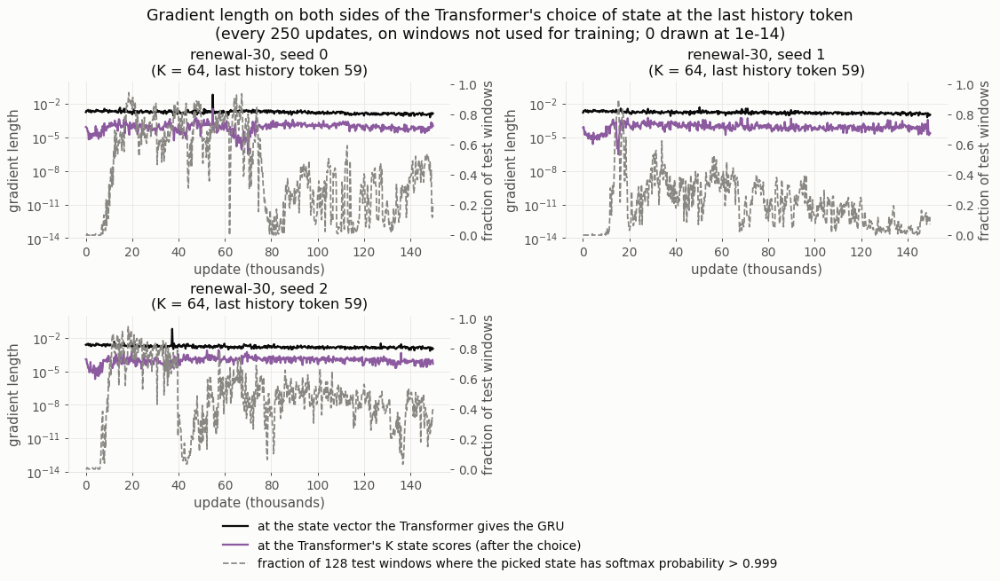

In [32]:
fig = R.plot_choice_over_training({f"renewal-30, seed {s}": (R.steps_and_trace(BEST, 30, s, LONG)[1],
                                                            R.settings_of(BEST, 30, s, LONG)) for s in R.SEEDS})
plt.show()

* **The choice is fixed less often as training goes on.** Each 50,000-update block has 200 measuring points. The
  number of them at which the choice is fixed on more than half of the 128 windows:
  * seed 0: 145, 89 and 9;
  * seed 1: 22, 2 and 0;
  * seed 2: 118, 89 and 31.

  At update 150,000 it is fixed on 21%, 7% and 40% of the windows.
* **The gradients on both sides of the choice stay up.**
  * The gradient arriving at the state vector stays at about 1e-3: median 1.3e-3–2.0e-3 in each block.
  * After the choice the median is 7.7e-5–1.4e-4. The smallest value is 3.0e-7 (seed 1, first 50,000 updates).
* So, on renewal-30, holding the temperature at 1 keeps the Transformer's choice open, and the Transformer comes to
  hand over 9–12 states. The GRU's machine, read with the highest score, still has a single long-run state.

**The machine each GRU learned** (as 6.5, highest score): at the final parameters, then at the parameters with the
best validation value.

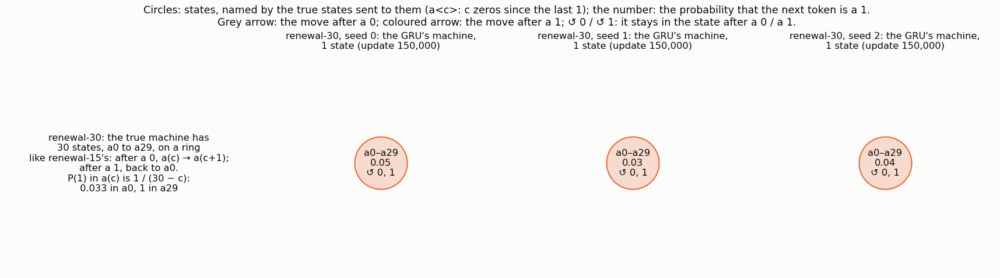

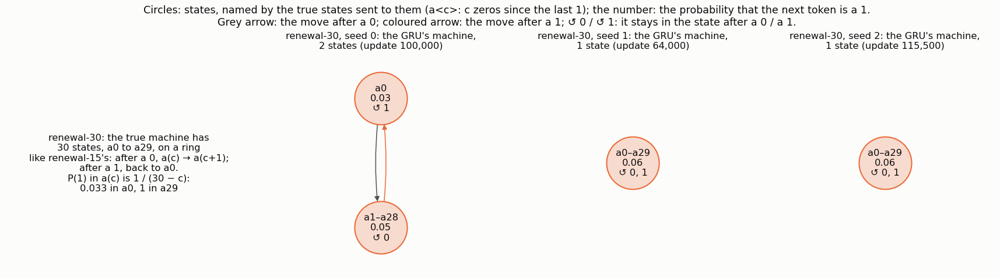

In [33]:
fig = R.plot_machines(BEST, (30,), steps=LONG, panel=4.8); plt.show()
fig = R.plot_machines(BEST, (30,), steps=LONG, which="best", panel=4.8); plt.show()

* **Final parameters: 1 state on every seed**, with P(1) 0.047, 0.034 and 0.044. In the long run the GRU, read with the
  highest score, predicts the same for every history.
* **Best parameters:**
  * Seed 0 (update 100,000) has two states:
    * a0, just after a 1, with P(1) 0.034;
    * a1–a28, with P(1) 0.050.

    After a 1 it goes to a0, after a 0 to a1–a28. It tells apart only whether the last token was a 1, like 6.5's
    renewal-60 seed 0.
  * Seeds 1 and 2 (updates 64,000 and 115,500) have 1 state each, with P(1) 0.059 and 0.060.

**The gradient at the starting points.** The 150,000-update runs start from the same weights as 6.5's renewal-30
runs, so the histogram is 6.8's renewal-30 row. The table places the three seeds among the 200 (rank 1 = smallest).
It also gives each seed's gap closed at update 150,000 under both readings.

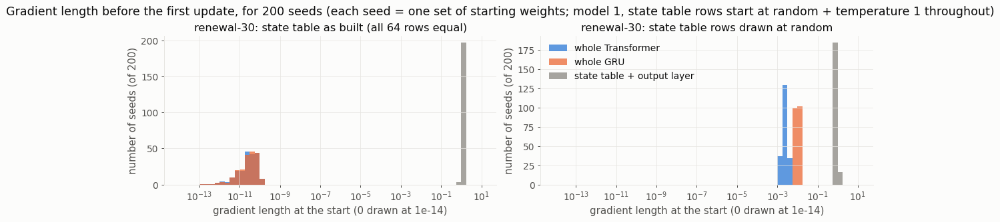

transformer  transformer_rank      gru  gru_rank table_output  table_output_rank gap_closed_highest gap_closed_drawn
N  seed                                                                                                                     
30 0        2.6e-03               134  1.2e-02       162      9.4e-01                127            1.2e-01          3.7e-01
   1        2.2e-03                91  9.4e-03        62      9.7e-01                168            9.4e-02          6.3e-01
   2        3.8e-03               190  1.4e-02       197      9.4e-01                135            1.4e-01          4.6e-01

In [34]:
fig = R.plot_start_gradients({30: R.start_gradients(BEST, 30)}, BEST); plt.show()
long_readings = readings(long_jobs).query("parameters == 'final'")[["N", "seed", "gap_closed_highest", "gap_closed_drawn"]]
display(sci(R.start_ranks(BEST, 30).merge(long_readings, on=["N", "seed"]).set_index(["N", "seed"])))

* **The gradient values at the start.**
  * With the table as built, the start is flat: the gradient reaching the whole Transformer or the whole GRU is at
    most 1.7e-10.
  * With random rows, the whole Transformer gets 1.2e-3 to 4.9e-3 (median 2.2e-3) and the whole GRU 6.4e-3 to 1.6e-2
    (median 1.0e-2).
* **The three seeds' ranks among the 200:**
  * Transformer: 134, 91 and 190;
  * GRU: 162, 62 and 197.

  Seed 1 is lowest on both, and gains the most from drawing (63% of the gap against 37% and 46%). Seed 2 is highest
  on both. Three runs are too few to tie the start to the outcome.

### 7.3 The search on renewal-30: one change at a time
The search of 6.3 on renewal-30: section 16's settings, the original setup and the same 20 single changes, 3 seeds,
50,000 updates (`renewal_check.search_jobs(N=30)`), 66 runs, all trained here. Sizes that a change sets are scaled by
30 / 15, as in 6.1: "16 table rows" becomes 32 rows (against 64 at renewal-30), "64 rows" becomes 128, and 2 and 5
future tokens become 4 and 10 (against 30). These four are labelled with their renewal-30 sizes.

At renewal-30 no run learns the process (6.1's rule), so the table is in fractions of the gap closed rather than in
bits: gap closed = 1 − excess / 0.0289, where 0.0289 bits is "remembers nothing". Per configuration, as means over the
3 seeds:
* `gap_closed`: at the final parameters, highest-score reading;
* `drawn_gap_closed`: the same parameters, the GRU's next states drawn as in training (7.2);
* `best_gap_closed`: at the parameters with the best validation value (highest score); `highest_best_gap_closed` is
  the largest of the 3 seeds;
* the true states told apart, at the end and at the best parameters; the GRU machine's states; the share of test
  windows on which the Transformer's choice is fixed at the end.

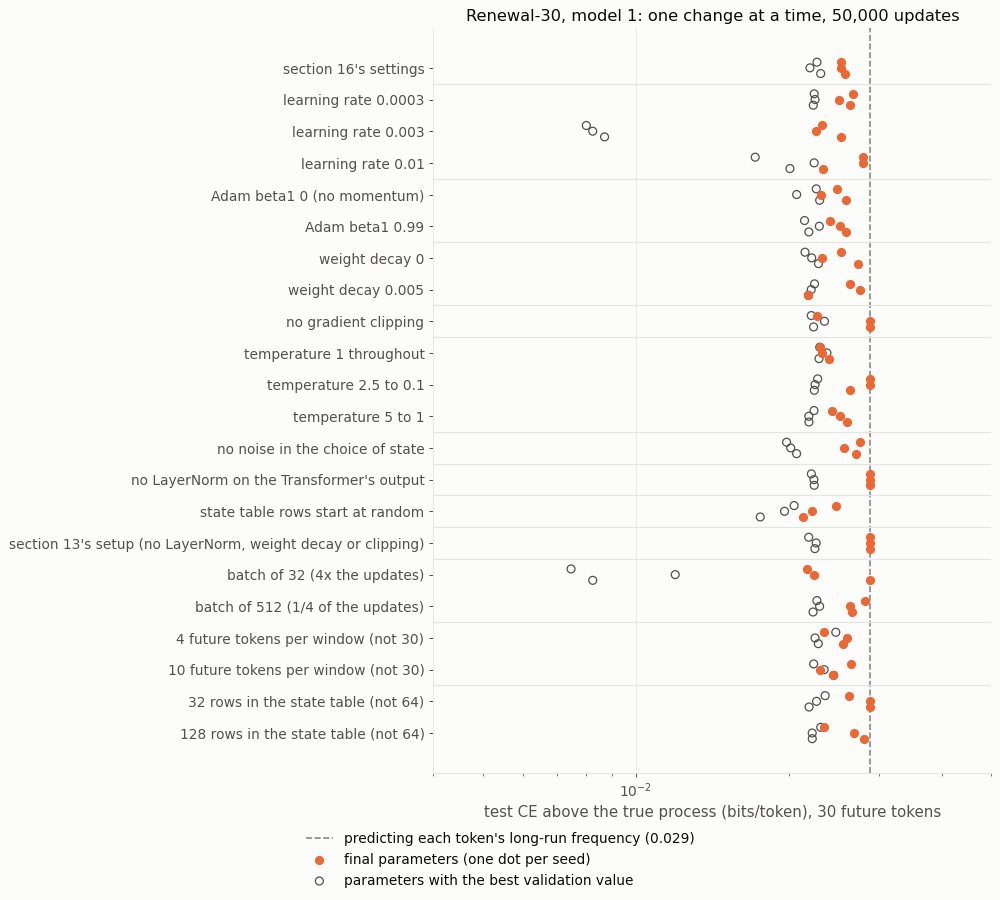

,seeds,learned,learned_at_best,gap_closed,drawn_gap_closed,best_gap_closed,highest_best_gap_closed,states_told_apart,best_states_told_apart,machine_states,choice_locked_share
config,,,,,,,,,,,
lr_3e-3,3,0,0,0.177,0.178,0.712,0.723,1.667,23.333,1.333,0.987
batch_32,3,0,0,0.157,0.156,0.681,0.741,1.333,17.333,1.000,0.798
table_random,3,0,0,0.211,0.212,0.334,0.391,1.000,1.667,1.000,0.892
lr_1e-2,3,0,0,0.086,0.086,0.311,0.405,2.000,9.333,1.667,1.000
no_noise,3,0,0,0.071,0.071,0.299,0.314,4.000,3.333,4.000,0.604
tau_5_1,3,0,0,0.127,0.124,0.236,0.242,1.000,1.000,1.000,0.884
beta1_0.99,3,0,0,0.132,0.132,0.234,0.256,1.000,1.333,1.000,0.885
beta1_0,3,0,0,0.146,0.145,0.234,0.282,1.000,1.000,1.000,0.943
wd_5e-3,3,0,0,0.124,0.128,0.233,0.243,1.000,1.667,1.000,0.862


In [35]:
def with_drawn(t):
    t["drawn_gap_closed"] = [1 - R.sampled_excess(r.config, r.N, r.seed, R.FINAL_STEPS)["excess_sampled"]
                             / lv[r.N]["remembers_nothing"] for r in t.itertuples()]
    return t


def by_config_gap(t):
    return t.groupby("config", sort=False).agg(
        seeds=("seed", "size"), learned=("learned", "sum"), learned_at_best=("learned_at_best", "sum"),
        gap_closed=("gap_closed", "mean"), drawn_gap_closed=("drawn_gap_closed", "mean"),
        best_gap_closed=("best_gap_closed", "mean"), highest_best_gap_closed=("best_gap_closed", "max"),
        states_told_apart=("states_told_apart", "mean"), best_states_told_apart=("best_states_told_apart", "mean"),
        machine_states=("machine_states", "mean"), choice_locked_share=("choice_locked_share", "mean"))


search30 = with_drawn(learned_columns(R.summary(R.search_jobs(N=30))))
fig = R.plot_search(search30, title="Renewal-30, model 1: one change at a time, 50,000 updates",
                    xlim=(4e-3, 5e-2)); plt.show()
display(by_config_gap(search30).sort_values("best_gap_closed", ascending=False).round(3))

**Per run, for the configurations that matter below**, then their validation curves (the batch of 32 has 4 times
the updates on its x axis), then every event in which a run loses what it learned, as in 6.3: a validation value
above 0.02 bits (31% of renewal-30's gap closed) after one below 0.01 bits (65% closed).

gap_closed  drawn_gap_closed  states_told_apart  best_update  best_gap_closed  best_states_told_apart  machine_states  choice_locked_share  best_choice_locked_share  first_50%_closed
config       seed                                                                                                                                                                                        
default      0          0.106             0.105                  1        18500            0.200                       1               1                0.963                     0.834               NaN
             1          0.123             0.123                  1        19500            0.238                       1               1                0.957                     0.778               NaN
             2          0.124             0.124                  1        15000            0.213                       1               1                0.951                     0.799               NaN
table_random 0          0.261             0.262                  1        41500            0.391                       2               1                0.893                     0.312               NaN
             1          0.231             0.227                  1        43500            0.321                       2               1                0.849                     0.750               NaN
             2          0.142             0.148                  1        39000            0.291                       1               1                0.935                     0.791               NaN
lr_3e-3      0          0.121             0.121                  1        30500            0.699                      24               1                0.988                     0.467           25000.0
             1          0.215             0.215                  3        42500            0.715                      22               2                0.994                     0.474           23000.0
             2          0.195             0.196                  1        31500            0.723                      24               1                0.978                     0.165           23000.0
no_noise     0          0.060             0.060                  4        28500            0.282                       4               4                0.000                     0.053               NaN
             1          0.111             0.111                  3        27500            0.301                       3               3                0.811                     0.057               NaN
             2          0.042             0.042                  5        22500            0.314                       3               5                1.000                     0.066               NaN
batch_32     0          0.000             0.000                  1       142500            0.715                      23               1                1.000                     0.262          103000.0
             1          0.223             0.223                  1       136500            0.586                       6               1                0.750                     0.309          119000.0
             2          0.249             0.246                  2       148000            0.741                      23               1                0.645                     0.223          132500.0

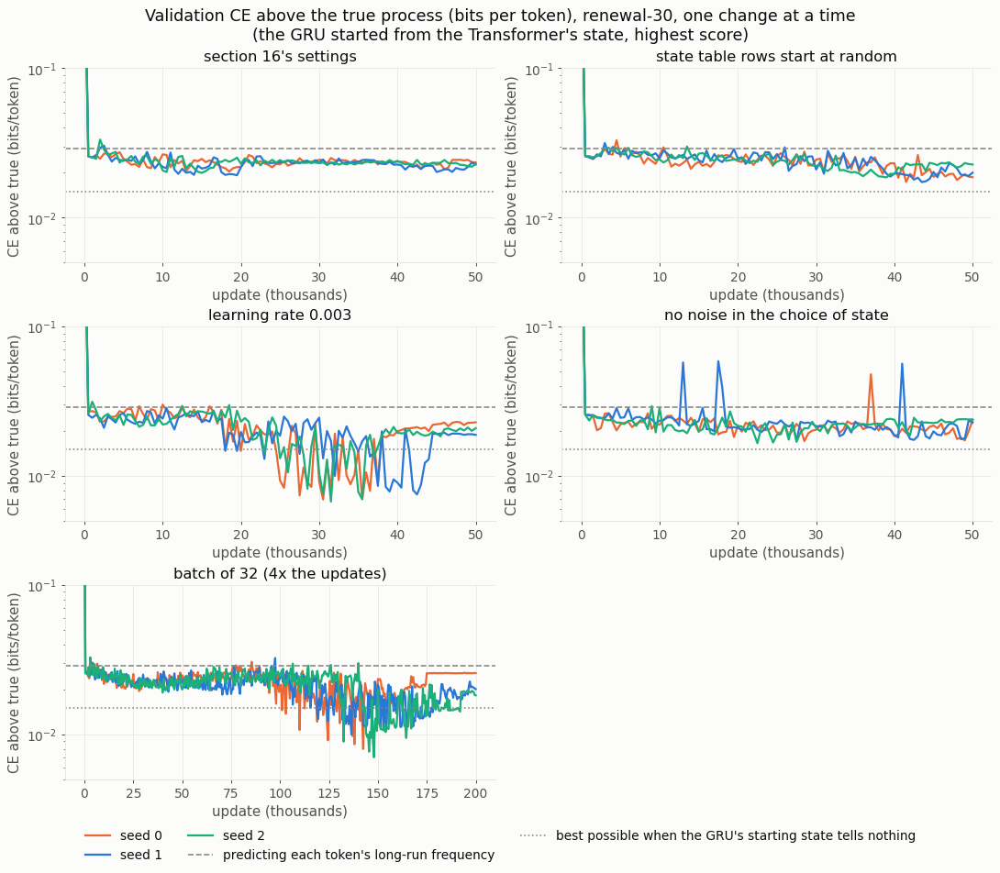

update  validation_excess  largest_gradient      at
config   seed                                                     
lr_3e-3  0      26500             0.0217            0.0462   26359
         0      29500             0.0223            0.0540   28594
         0      40500             0.0203            0.0397   40423
         1      41000             0.0207            0.0561   40627
         2      29500             0.0213            0.0607   29176
         2      38500             0.0206            0.1763   37906
batch_32 0     125500             0.0228            0.1120  124754
         0     141500             0.0214            0.1133  140724
         0     143500             0.0220            0.1015  143008
         1     140500             0.0205            0.2018  140242
         2     133500             0.0247            0.1028  133006
         2     173000             0.0205            0.0991  172675

In [36]:
cols_search30 = ["config", "seed", "gap_closed", "drawn_gap_closed", "states_told_apart", "best_update",
                 "best_gap_closed", "best_states_told_apart", "machine_states", "choice_locked_share",
                 "best_choice_locked_share", "first_50%_closed"]
display(search30[search30.config.isin(['default', 'table_random', 'lr_3e-3', 'no_noise', 'batch_32'])][cols_search30].set_index(["config", "seed"]).round(3))
fig = R.plot_curves({R.label(n, 30): [(s, R.folder_of(n, 30, s, R.FINAL_STEPS)) for s in R.SEEDS]
                     for n in ['default', 'table_random', 'lr_3e-3', 'no_noise', 'batch_32']},
                    title="Validation CE above the true process (bits per token), renewal-30, one change at a time\n"
                          "(the GRU started from the Transformer's state, highest score)", ylim=(5e-3, 0.1))
plt.show()
lost30 = R.losses(same_L(R.search_jobs(N=30)))
display(lost30.set_index(["config", "seed"]).round(4))

* **No run learns renewal-30** (6.1's rule), at the end or at the parameters with the best validation value.
* **At the end, every run has closed at most 26% of the gap.** The largest are random table rows, seed 0 (0.26), the
  batch of 32, seed 2 (0.25) and weight decay 0.005, seed 0 (0.24).
* **13 runs end exactly where a model that remembers nothing would** (gap closed between −0.0014 and 0.0000; the
  next lowest is 0.023). They are the original setup (3 seeds), no LayerNorm (3), no clipping (2), the temperature
  from 2.5 to 0.1 (2), 32 table rows (2) and the batch of 32 (1). In all 13 the Transformer hands the same state to
  every window (1 code).
* **The size of the state table does not help.** With 32 rows (half of renewal-30's 64) the runs end at 0%, 0% and
  9%; with 128 rows at 3%, 7% and 19%, and at most 23% at their best. (On renewal-15, twice the rows learned on one
  seed: 6.3.)
* **The same two changes as on renewal-15 get much further during training, then lose it:**
  * learning rate 0.003: at its best it has closed 70%, 72% and 72% of the gap (updates 30,500, 42,500 and 31,500),
    with 24, 22 and 24 of the 30 true states told apart. It first closes 50% at update 23,000–25,000. At the end it
    has closed 12–22%, with the choice fixed on 98–99% of windows.
  * the batch of 32 (200,000 updates): at its best 72%, 59% and 74% (updates 142,500, 136,500 and 148,000), with
    23, 6 and 23 states told apart. It first closes 50% at update 103,000–132,500. At the end: 0%, 22% and 25%.

  On renewal-15 these two closed 95–98% of the gap at their best (6.3). Every other change stays at or below 41% at
  its best (learning rate 0.01, seed 2: 41%, with 14 states told apart).
* **Losing it is again a drift, not one large step.** Using 6.3's definition (above 0.02 bits after below 0.01),
  there are 12 events in 6 runs: learning rate 0.003 and the batch of 32, 3 seeds each. In all 12, the longest
  gradient in the 1,000 updates before is at most 0.20 (clipping length 1.0).
* **The same changes keep the Transformer's choice from becoming fixed, but do not learn:**
  * with the temperature held at 1, the choice is fixed on 26%, 58% and 88% of windows at the end;
  * with no noise in the choice: 0%, 81% and 100%;
  * at section 16's settings: 95–96%.

  No noise in the choice is the only change whose GRU machine keeps more than one state at the end (4, 3 and 5
  states), but it closes only 4–11% of the gap.
* **The chosen settings' single changes:**
  * Random table rows end best on average (gap closed 0.14–0.26), but reach only 29–39% at their best.
  * The temperature held at 1 ends at 17–20%.
* **Fewer future tokens** (4 or 10, against 30): on their own validation windows these runs close 50% of the gap by
  update 2,000–3,500. On the 30-token test windows they end at 8–20%.
* **The two readings of the GRU agree at the end of these runs:** the gap closed with each next state drawn differs
  from the highest-score reading by −0.007 to +0.027 (at most 0.0008 bits).

### 7.4 Two changes together on renewal-30
7.3 found the same two kinds of change as 6.3:
* **changes that learn much of renewal-30 during training, then lose it:** learning rate 0.003 and the batch of 32;
* **changes that keep the Transformer's choice from becoming fixed on some seeds:** the temperature held at 1 and no
  noise in the choice. With no noise, the GRU's states are not drawn at all, so training reads them the way the tests
  do (7.2).

As in 6.4, each change of the first kind is paired with each of the second, and the first two are put together: 5
configurations, 3 seeds (`PAIRS_30` in `renewal_check.py`). Every pair with the batch of 32 has 200,000 updates (the
same windows as 50,000 updates of 128). The temperature from 5 to 1 is left out: on renewal-30 it left the choice
fixed on 81–93% of windows at the end.

The figure shows the four changes alone (from 7.3) and section 6's chosen settings (6.5's renewal-30 runs) above the
pairs. Then the table per configuration (as in 7.3), the table per pair run, the validation curves, and the events in
which a run loses what it learned.

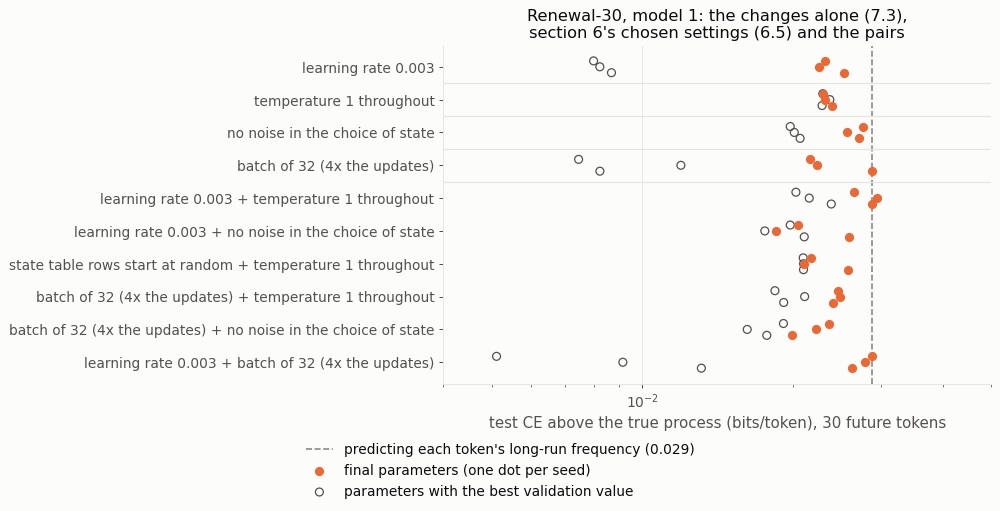

,seeds,learned,learned_at_best,gap_closed,drawn_gap_closed,best_gap_closed,highest_best_gap_closed,states_told_apart,best_states_told_apart,machine_states,choice_locked_share
config,,,,,,,,,,,
lr_3e-3,3,0,0,0.177,0.178,0.712,0.723,1.667,23.333,1.333,0.987
lr_3e-3+batch_32,3,0,0,0.041,0.041,0.683,0.823,1.333,23.333,1.333,0.973
batch_32,3,0,0,0.157,0.156,0.681,0.741,1.333,17.333,1.000,0.798
batch_32+no_noise,3,0,0,0.239,0.239,0.386,0.438,7.333,9.000,7.000,0.009
lr_3e-3+no_noise,3,0,0,0.249,0.249,0.324,0.390,8.333,7.667,8.000,0.003
batch_32+tau_const1,3,0,0,0.150,0.258,0.321,0.361,1.000,4.667,1.000,0.430
no_noise,3,0,0,0.071,0.071,0.299,0.314,4.000,3.333,4.000,0.604
table_random+tau_const1,3,0,0,0.208,0.214,0.271,0.272,1.333,1.667,1.000,0.408
lr_3e-3+tau_const1,3,0,0,0.019,0.045,0.240,0.296,1.000,2.667,1.000,0.854


gap_closed  drawn_gap_closed  states_told_apart  best_update  best_gap_closed  best_states_told_apart  machine_states  choice_locked_share  best_choice_locked_share  first_50%_closed
config              seed                                                                                                                                                                                        
lr_3e-3+tau_const1  0          0.000             0.000                  1         2000            0.172                       3               1                0.715                     0.000               NaN
                    1         -0.021             0.040                  1        10000            0.252                       3               1                1.000                     0.960               NaN
                    2          0.079             0.095                  1        27500            0.296                       2               1                0.847                     0.024               NaN
lr_3e-3+no_noise    0          0.102             0.102                  4        31500            0.269                       3               3                0.002                     0.007               NaN
                    1          0.357             0.357                 11        45500            0.390                      16              11                0.008                     0.039           45500.0
                    2          0.289             0.289                 10        33500            0.314                       4              10                0.000                     0.458               NaN
batch_32+tau_const1 0          0.164             0.484                  1       119500            0.335                       2               1                0.297                     0.035               NaN
                    1          0.138             0.143                  1       138000            0.267                       1               1                0.469                     0.551               NaN
                    2          0.147             0.147                  1       162500            0.361                      11               1                0.523                     0.293               NaN
batch_32+no_noise   0          0.310             0.310                 11       190000            0.385                      12              11                0.012                     0.016               NaN
                    1          0.227             0.227                  7       150000            0.438                      13               7                0.004                     0.012               NaN
                    2          0.181             0.181                  4       134500            0.335                       2               3                0.012                     0.719               NaN
lr_3e-3+batch_32    0          0.090             0.090                  1        97500            0.545                      17               1                0.918                     0.426           97500.0
                    1          0.033             0.033                  2        46500            0.683                      26               2                1.000                     0.125           38000.0
                    2         -0.000            -0.000                  1        68000            0.823                      27               1                1.000                     0.250           49000.0

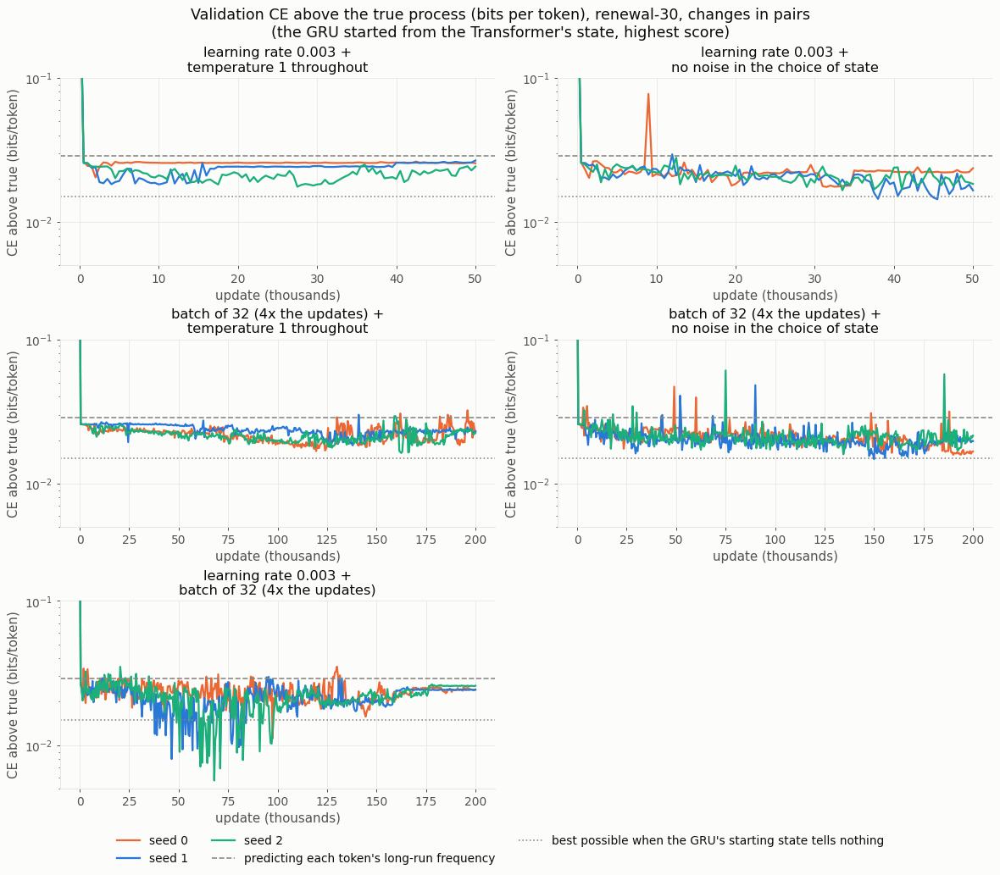

update  validation_excess  largest_gradient     at
config           seed                                                    
lr_3e-3+batch_32 1      49000             0.0206            0.0726  48770
                 1      52500             0.0221            0.0827  51618
                 1      57500             0.0213            0.0705  57311
                 1      63000             0.0213            0.1445  62538
                 1      72000             0.0216            0.1086  71759
                 1      84500             0.0216            0.0795  83863
                 2      52500             0.0222            0.0863  52370
                 2      67000             0.0204            0.0690  66849
                 2      72500             0.0205            0.0742  72130
                 2      83500             0.0231            0.1014  83131
                 2      93500             0.0247            0.3040  92743

In [37]:
pairs30 = with_drawn(learned_columns(R.summary(R.pairs_30_jobs())))
parts30 = search30[search30.config.isin(R.LEARNERS_30 + R.KEEPERS_30)]
chosen30 = with_drawn(learned_columns(R.summary([(BEST, 30, s, R.FINAL_STEPS) for s in R.SEEDS])))
both30 = pd.concat([parts30, chosen30, pairs30])
fig = R.plot_search(both30, title="Renewal-30, model 1: the changes alone (7.3),\nsection 6's chosen settings (6.5) "
                                  "and the pairs", xlim=(4e-3, 5e-2)); plt.show()
display(by_config_gap(both30).sort_values("best_gap_closed", ascending=False).round(3))
display(pairs30[cols_search30].set_index(["config", "seed"]).round(3))
fig = R.plot_curves({R.label(n, 30).replace(" + ", " +\n"): [(s, R.folder_of(n, 30, s, R.FINAL_STEPS)) for s in R.SEEDS]
                     for n in R.PAIRS_30}, width=6.5, height=3.8,
                    title="Validation CE above the true process (bits per token), renewal-30, changes in pairs\n"
                          "(the GRU started from the Transformer's state, highest score)", ylim=(5e-3, 0.1))
plt.show()
lost30_pairs = R.losses(R.pairs_30_jobs())
display(lost30_pairs.set_index(["config", "seed"]).round(4))

* **No pair learns renewal-30** (6.1's rule), at the end or at its best parameters.
* **No noise in the choice now helps, the opposite of renewal-15** (6.4, where it prevented learning with either
  partner). At the end:
  * learning rate 0.003 with no noise: 10%, 36% and 29% of the gap closed (mean excess 0.0217 bits), with 4, 11 and
    10 of the 30 true states told apart;
  * the batch of 32 with no noise: 31%, 23% and 18% (0.0219 bits), with 11, 7 and 4 states told apart.

  These two are the lowest mean excesses at the end of any renewal-30 configuration; next come random table rows
  alone and section 6's chosen settings (both 0.0228 bits, 21%). They hold the two highest values of all 87
  renewal-30 runs at the end (36% and 31%; the highest before was 6.5's seed 1 of section 6's chosen settings, 27%).
  They are also the only configurations whose GRU machines keep more than 5 states at the end (11 and 10; 11 and 7).
  The Transformer's choice is fixed on 0–1.2% of the test windows at the end.
* **But they never get as far as the learners alone.** At their best they close 27–39% (learning rate 0.003, no
  noise) and 34–44% (batch of 32, no noise), against 70–72% for learning rate 0.003 alone. They lose less of it: 0.03–0.21
  between best and end, against 0.50–0.58 for learning rate 0.003 alone.
* **Learning rate 0.003 with the batch of 32 comes closest of all renewal-30 runs, then loses it.** At its best it
  closes 55%, 68% and 82% of the gap (updates 97,500, 46,500 and 68,000 of 200,000), with 17, 26 and 27 of the 30
  states told apart. Seed 2's best is 0.0051 bits, the lowest of any renewal-30 run. At the end: 9%, 3% and 0%,
  with the choice fixed on 92%, 100% and 100% of windows, and the Transformer handing over 7, 1 and 1 states. It has
  11 losses (as in 7.3) on seeds 1 and 2, all with the longest gradient in the 1,000 updates before at most 0.30.
* **Holding the temperature at 1 makes both learners worse**, as it did learning rate 0.003 on renewal-15 (6.4):
  * with learning rate 0.003: 0%, −2% and 8% at the end, 17–30% at the best (alone: 70–72%);
  * with the batch of 32: 16%, 14% and 15% at the end, 27–36% at the best (alone: 59–74%).

  With the batch of 32, seed 0 closes 48% of the gap when its GRU's states are drawn as in training, against 16% with
  the highest score (its drawn state differs on 18% of steps), like the 150,000-update runs of 7.2. In the other pair
  runs the two readings differ by at most 0.06 at the end.

**The best settings on renewal-30**, by 6.4's rule (the lowest mean excess at the end of training): **learning rate
0.003 with no noise in the choice** (`lr_3e-3+no_noise`). These are section 16's settings with two changes: the
learning rate is 0.003 instead of 0.001, and each state is the highest score in training too, with no random noise.
The batch of 32 with no noise is close behind (0.0219 against 0.0217 bits), but needs 4 times the updates.

### 7.5 The best settings on renewal-30: learning rate 0.003, no noise in the choice
7.4's three runs (50,000 updates) with 7.2's graphs: 6.5's table, the two readings of the GRU, P(1) at each true
state, gradient and loss over training, the Transformer's choice, the GRU's machines, and the gradient at the
starting points. Without noise the GRU's next state is the highest score in training as well, so the two readings
are the same by construction (`drawn_differs` is 0). The training loss is then the highest-score reading on the
training windows.

excess  gap_closed  states_told_apart  learned  best_excess  best_update  best_gap_closed  best_states_told_apart  long_excess  machine_states  handoff_codes  handoff_information  choice_locked_share  \
N  seed                                                                                                                                                                                                            
30 0     0.0259      0.1021                  4    False       0.0211        31500           0.2686                       3       0.0287               3             11               0.6196               0.0020   
   1     0.0185      0.3573                 11    False       0.0176        45500           0.3902                      16       0.0205              11              9               0.5943               0.0078   
   2     0.0205      0.2889                 10    False       0.0198        33500           0.3143                       4       0.0206              10              4               0.3250               0.0000   

         encoder_classifier  encoder_classifier_untrained  first_50%_closed first_90%_closed  
N  seed                                                                                       
30 0                 0.9951                        0.4377               NaN             None  
   1                 0.9951                        0.4414           45500.0             None  
   2                 0.9778                        0.6826               NaN             None

update  excess_highest  excess_drawn  gap_closed_highest  gap_closed_drawn  drawn_differs  training_loss_excess
run_updates N  seed parameters                                                                                                                 
50000       30 0    final        50000          0.0259        0.0259              0.1021            0.1021            0.0                0.0261
                    best         31500          0.0211        0.0211              0.2686            0.2686            0.0                   NaN
               1    final        50000          0.0185        0.0185              0.3573            0.3573            0.0                0.0205
                    best         45500          0.0176        0.0176              0.3902            0.3902            0.0                   NaN
               2    final        50000          0.0205        0.0205              0.2889            0.2889            0.0                0.0214
                    best         33500          0.0198        0.0198              0.3143            0.3143            0.0                   NaN

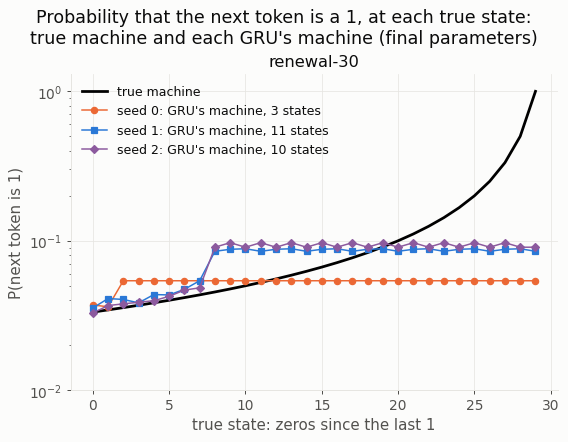

In [38]:
BEST30 = 'lr_3e-3+no_noise'
best30_jobs = [(BEST30, 30, s, R.FINAL_STEPS) for s in R.SEEDS]
best30 = learned_columns(R.summary(best30_jobs))
display(best30[cols_final].set_index(["N", "seed"]).round(4))
display(readings(best30_jobs).set_index(["run_updates", "N", "seed", "parameters"]).drop(columns="config").round(4))
fig = R.plot_prob_of_one(BEST30, Ns=(30,)); plt.show()

* **The test results at update 50,000:**
  * excess 0.0259, 0.0185 and 0.0205 bits: 10%, 36% and 29% of the gap closed;
  * 4, 11 and 10 of the 30 true states told apart;
  * GRU machines with 3, 11 and 10 states;
  * over 200 future tokens, 0.0287, 0.0205 and 0.0206 bits.
* **The Transformer.** It hands the GRU 11, 9 and 4 states (information 0.62, 0.59 and 0.33). A linear classifier reads
  the true state from its output on 99.5%, 99.5% and 97.8% of the test windows (44%, 44% and 68% untrained). Its choice is
  fixed on 0.2%, 0.8% and 0% of the test windows.
* **The training loss matches the test result.** Its last 250 updates are 0.0261, 0.0205 and 0.0214 bits above the
  best possible, against test excesses of 0.0259, 0.0185 and 0.0205.
* **The best parameters are near the end.** They are at updates 31,500, 45,500 and 33,500, where the gap closed is
  27%, 39% and 31%. So the runs lose 0.17, 0.03 and 0.03 of it by the end. The lowest validation values are 0.0175,
  0.0144 and 0.0166 bits; 13, 37 and 33 of the 101 checks are below 0.02.
* **The figure (P(1) at each true state, from the GRU's machine).** Seeds 1 and 2 give counts 0–7 a state each, with
  P(1) rising from 0.036 to 0.054 (seed 1) and from 0.033 to 0.048 (seed 2); the true values are 0.033 to 0.043.
  Every longer count shares a short cycle of states: 3 states with P(1) 0.085–0.088 (seed 1), 2 states with 0.091 and
  0.097 (seed 2). The true P(1) rises from 0.045 at count 8 to 1 at count 29. Seed 0 tells apart only counts 0 and 1
  (P(1) 0.037 and 0.036); every other count has 0.054.

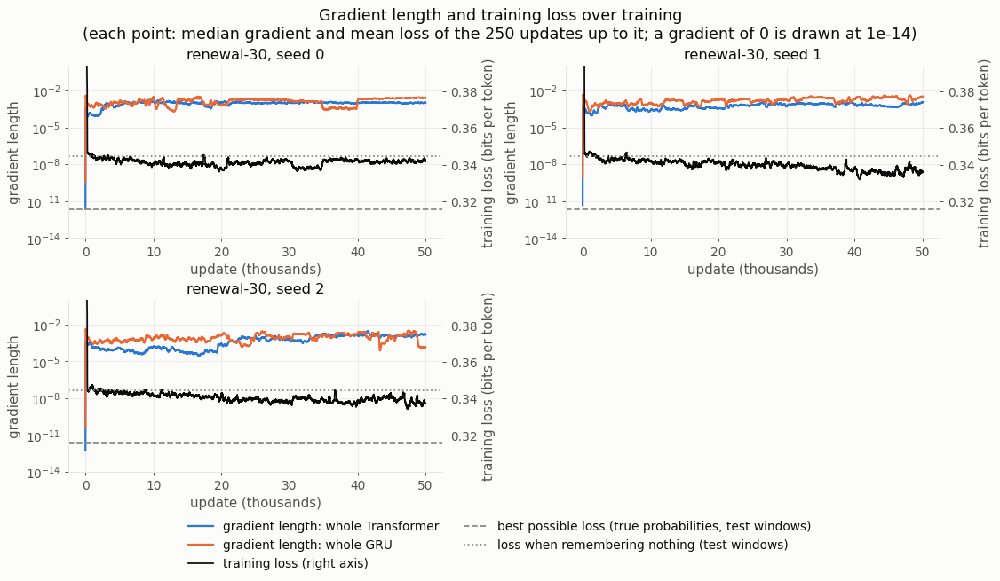

In [39]:
fig = R.plot_whole_training({f"renewal-30, seed {s}": (R.steps_and_trace(BEST30, 30, s, R.FINAL_STEPS)[0], 30)
                             for s in R.SEEDS})
plt.show()

* **The training loss keeps falling on two seeds.** Of the gap between
  remembering nothing (0.345) and the best possible (0.316), it has removed 16%, 10% and 11% by update 10,000. By
  update 50,000 it has removed 10%, 29% and 26% (mean of the last 250 updates). Section 6's chosen settings had
  removed 8%, 23% and 20% at update 50,000 (7.2).
* **The gradients never die.**
  * The whole Transformer's median, per block of 10,000 updates, is 7.1e-4–1.1e-3 (seed 0), 3.5e-4–8.4e-4 (seed 1),
    and 7.3e-5–1.3e-3 (seed 2, lowest in its first 20,000 updates).
  * The whole GRU's median is 5.3e-4–2.5e-3.
  * After update 1 the Transformer's gradient is below 1e-6 on 4 updates (seed 0 at 1,853; seed 2 at 2,863, 2,958 and
    7,658; smallest 5.9e-7). The GRU's is never below 1e-6 after update 1.
  * Above the clipping length 1: 5, 9 and 13 updates for the Transformer and 15, 25 and 27 for the GRU, of 50,000.
    Some of them are very long: the longest gradient of all parameters is 2.4e14, 1.5e11 and 2.3e7 (7.6 looks at
    these single updates).

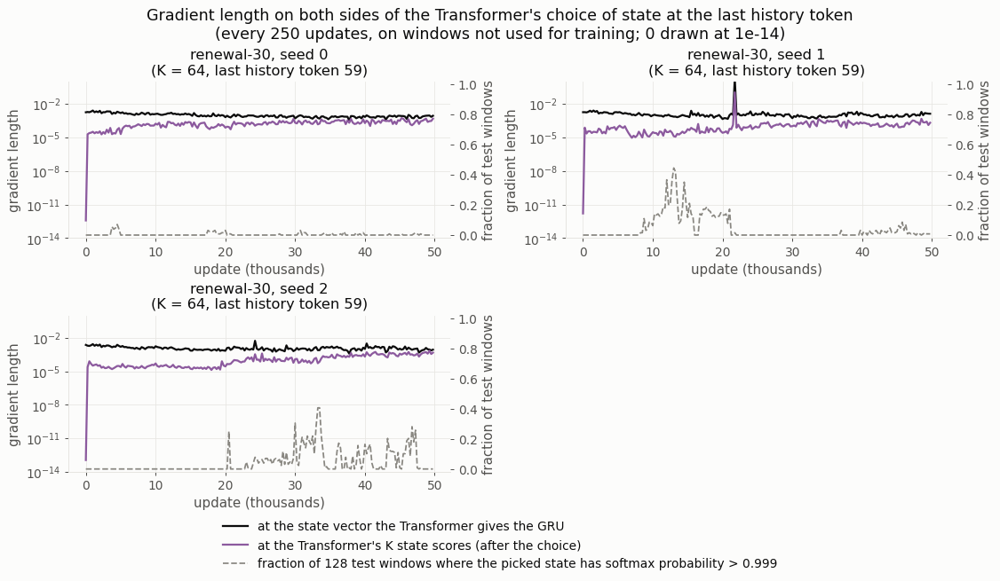

In [40]:
fig = R.plot_choice_over_training({f"renewal-30, seed {s}": (R.steps_and_trace(BEST30, 30, s, R.FINAL_STEPS)[1],
                                                            R.settings_of(BEST30, 30, s, R.FINAL_STEPS))
                                   for s in R.SEEDS})
plt.show()

* **The choice is never fixed on most windows.** At none of the 200 measuring points of any seed is it fixed on more
  than half of the 128 windows. The largest shares are 7%, 45% and 41%. (Section 6's chosen settings, 7.2: at 145,
  22 and 118 of the first 200 points.)
* **The gradients on both sides of the choice.** The gradient arriving at the state vector has a median of
  6.9e-4–1.5e-3 per block of 10,000 updates. After the choice the median is 2.3e-5–3.5e-4, and the smallest value is
  9.2e-6 (7.2: 7.7e-5–1.4e-4, smallest 3.0e-7).

**The machine each GRU learned** (as 6.5, highest score): at the final parameters, then at the parameters with the
best validation value.

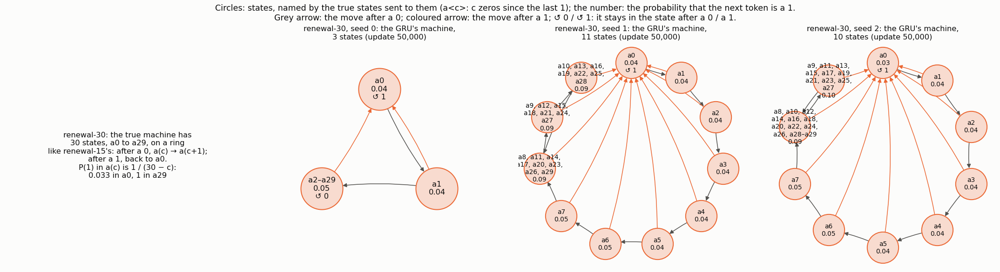

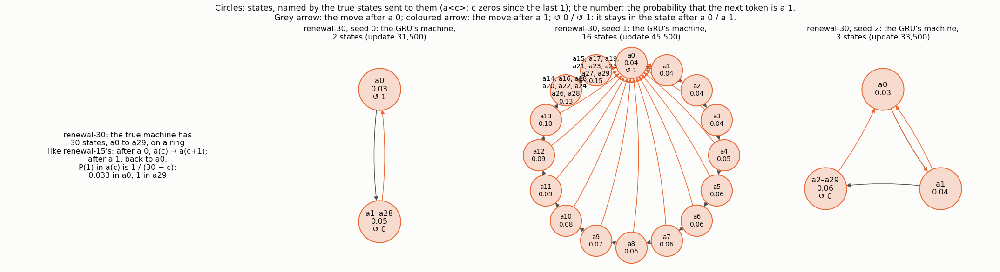

In [41]:
fig = R.plot_machines(BEST30, (30,), panel=6.0); plt.show()
fig = R.plot_machines(BEST30, (30,), which="best", panel=6.0); plt.show()

* **Final parameters.**
  * Seed 0: 3 states: a0, just after a 1 (P(1) 0.037); a1, after one zero (0.036); and one state for every longer
    count (0.054).
  * Seed 1: 11 states. Counts 0–7 each have their own state. From count 8 the GRU goes round a cycle of 3 states
    (P(1) 0.085–0.088) until the next 1.
  * Seed 2: 10 states. Counts 0–7 each have their own state, then a cycle of 2 (P(1) 0.091 and 0.097).

  Every renewal-30 machine drawn before (6.5, 7.2) has 1 or 2 states. These two count the zeros up to 7, then lose
  track of how many.
* **Best parameters.**
  * Seed 0 (update 31,500) has 2 states: after a 1 (P(1) 0.034), and every other count (0.050).
  * Seed 1 (update 45,500) has 16 states. It gives counts 0–13 a state each, with P(1) rising from 0.038 to 0.099
    (true: 0.033 to 0.059). Every longer count shares a cycle of 2 (0.131 and 0.148).
  * Seed 2 (update 33,500) has 3 states: counts 0 and 1 (0.032 and 0.036), and every other count (0.060).

**The gradient at the starting points**, as in 6.8, with these settings (temperature 2.5 at the start, no noise; the
learning rate does not enter). These runs start from the table as built, with equal rows.

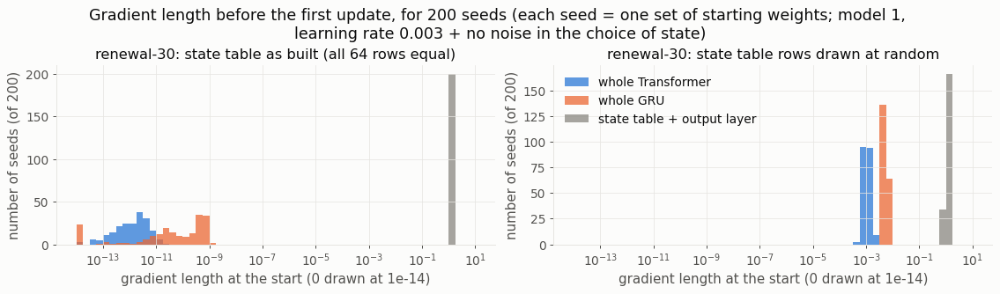

In [42]:
fig = R.plot_start_gradients({30: R.start_gradients(BEST30, 30)}, BEST30,
                             title="\n" + R.label(BEST30, 30)); plt.show()

* **With equal rows the start is flat, as with noise.** At all 200 starting points the gradient reaching the whole
  Transformer is at most 2.8e-11, and that reaching the whole GRU at most 1.7e-9 (exactly 0 at some points). The state
  table with the output layer gets 1.0–1.7.
* **Without noise the flat start lasts one update.** In the three runs the Transformer's gradient is 2.4e-12,
  4.8e-12 and 6.3e-13 at update 1, and 2.1e-5, 1.8e-5 and 3.0e-5 at update 2. With noise (section 16's settings and
  learning rate 0.003 on renewal-30) it first passes 1e-6 at update 3–8 and 1e-5 at update 18–38.
* **With random rows** every starting point gives both parts a gradient: the whole Transformer 5.1e-4 to 2.3e-3
  (median 1.0e-3), the whole GRU 3.2e-3 to 8.1e-3 (median 5.2e-3). With noise the values are about the same
  (5.3e-4 to 2.1e-3 and 3.1e-3 to 7.7e-3).

### 7.6 The best renewal-30 settings for 150,000 updates
7.5's settings (learning rate 0.003, no noise in the choice) on renewal-30 for 150,000 updates, 3 seeds, as 7.2 did for
section 6's chosen settings. In 7.5, on two of the three seeds the training loss had removed more of its gap at update
50,000 than at any earlier multiple of 10,000, so more updates might help.

**One difference from 7.2.** The temperature falls from 2.5 to 0.5 over the whole run, as in section 16, so here it
falls three times more slowly: at update 50,000 it is 1.46, not 0.5. Without noise the temperature does not change
which state is chosen, only the gradient that passes the choice (the introduction's "choice and q"). So these runs
differ from 7.5's from the first update. (7.2's settings hold it at 1, so there the first 50,000 updates were 6.5's
runs exactly.) Each run took 295–300 minutes, 3 at a time.

The table has 6.5's columns for these runs (`updates` 150,000) and for 7.5's (50,000). Then the validation curves of
both, and every event in which a run loses what it learned (as in 7.3: above 0.02 bits after below 0.01).

excess  gap_closed  states_told_apart  learned  best_excess  best_update  best_gap_closed  best_states_told_apart  long_excess  machine_states  handoff_codes  handoff_information  choice_locked_share  \
updates N  seed                                                                                                                                                                                                            
150000  30 0     0.0254      0.1208                  3    False       0.0182       104500           0.3707                       3       0.0265               3              9               0.5912               0.0020   
           1     0.0193      0.3302                 19    False       0.0078       124000           0.7313                      28       0.0211              19              6               0.3462               0.0020   
           2     0.0246      0.1465                  6    False       0.0093       129500           0.6776                      22       0.0262               6              7               0.4637               0.0000   
50000   30 0     0.0259      0.1021                  4    False       0.0211        31500           0.2686                       3       0.0287               3             11               0.6196               0.0020   
           1     0.0185      0.3573                 11    False       0.0176        45500           0.3902                      16       0.0205              11              9               0.5943               0.0078   
           2     0.0205      0.2889                 10    False       0.0198        33500           0.3143                       4       0.0206              10              4               0.3250               0.0000   

                 encoder_classifier  encoder_classifier_untrained  first_50%_closed first_90%_closed  
updates N  seed                                                                                       
150000  30 0                 1.0000                        0.4377          104500.0             None  
           1                 0.9976                        0.4414           68500.0             None  
           2                 0.9954                        0.6826           59500.0             None  
50000   30 0                 0.9951                        0.4377               NaN             None  
           1                 0.9951                        0.4414           45500.0             None  
           2                 0.9778                        0.6826               NaN             None

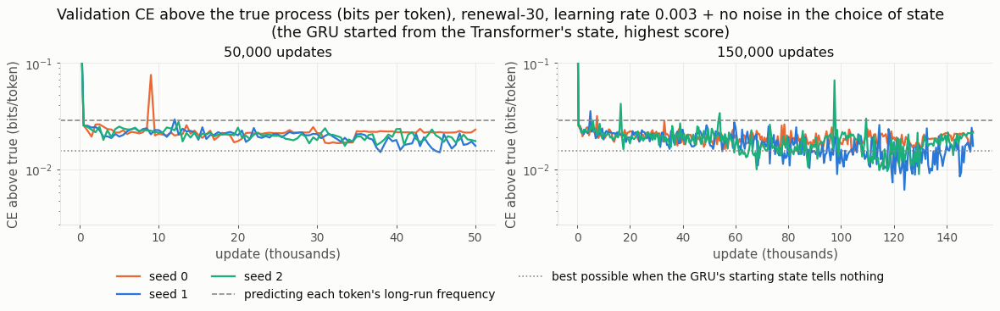

update  validation_excess  largest_gradient      at
config           seed                                                     
lr_3e-3+no_noise 1     106500             0.0213            0.1773  106355
                 1     132500             0.0243            0.0729  131947
                 1     137000             0.0204            0.1375  136614
                 1     149500             0.0245           20.3427  148532
                 2      73000             0.0263            0.1494   72662
                 2     125500             0.0212            0.2458  125465
                 2     131500             0.0204           68.0915  131462

In [43]:
best30_long_jobs = [(BEST30, 30, s, LONG) for s in R.SEEDS]
best30_both = learned_columns(R.summary(best30_long_jobs + best30_jobs))
display(best30_both[["updates"] + cols_final].set_index(["updates", "N", "seed"]).round(4))
fig = R.plot_curves({f"{n:,} updates": [(s, R.folder_of(BEST30, 30, s, n)) for s in R.SEEDS]
                     for n in (R.FINAL_STEPS, LONG)}, width=6.5, height=4.0, ylim=(3e-3, 0.1),
                    title=f"Validation CE above the true process (bits per token), renewal-30, {R.label(BEST30, 30)}\n"
                          "(the GRU started from the Transformer's state, highest score)")
plt.show()
display(R.losses(best30_long_jobs).set_index(["config", "seed"]).round(4))

* **150,000 updates do not learn renewal-30** (6.1's rule), at the end or at the parameters with the best validation
  value.
* **The end is no better than at 50,000 updates.** At update 150,000:
  * the excess is 0.0254, 0.0193 and 0.0246 bits: 12%, 33% and 15% of the gap closed. 7.5's runs ended at 10%, 36%
    and 29%; the mean excess is 0.0231 bits, against 0.0217;
  * 3, 19 and 6 of the 30 true states are told apart (7.5: 4, 11 and 10). Seed 1's 19 is the most of any of the 90
    renewal-30 runs at the end (the most before was 11);
  * over 200 future tokens the excess is 0.0265, 0.0211 and 0.0262 bits.
* **During training, two seeds get much further.** The parameters with the best validation value are at updates
  104,500, 124,000 and 129,500.
  * There the test excess is 0.0182, 0.0078 and 0.0093 bits: 37%, 73% and 68% of the gap closed (7.5's best: 27%,
    39% and 31%). 3, 28 and 22 of the 30 states are told apart.
  * Seed 1's 28 states are the most of any renewal-30 run. The most before was 27 (learning rate 0.003 with the batch
    of 32, seed 2, 7.4).
  * Its 0.0078 bits is the third lowest best value of the 90 runs, after that run's 0.0051 and the batch of 32's seed
    2 (0.0075, 7.3). Over 200 future tokens it gives 0.0053 bits.
* **On the validation windows:**
  * the excess is below 0.02 bits at 150, 207 and 191 of the 301 checks (7.5: 13, 37 and 33 of 101);
  * it is below 0.01 bits (65% of the gap closed) at 0, 13 and 5 checks, first at update 98,500 (seed 1) and 68,000
    (seed 2). 7.5's runs never were;
  * half the gap is first closed at update 104,500, 68,500 and 59,500;
  * the value moves a lot between neighbouring checks. After update 10,000 the median change is 0.0012–0.0021 bits,
    and 0.0050–0.0092 at the 95th percentile (7.2: 0.0006–0.0011 and 0.0025–0.0053).
* **Then seeds 1 and 2 lose it, as the learners of 7.3–7.4 did.** By 6.3's definition there are 4 events in seed 1
  (updates 106,500 to 149,500) and 3 in seed 2 (73,000 to 131,500).
  * In 5 of the 7 the longest gradient in the 1,000 updates before is at most 0.25.
  * The other two come after a single long gradient (20 and 68). The gradient findings below show that such updates do
    not explain the losses.
* **The best parameters come late in both run lengths.** They are at 70%, 83% and 86% of the way through these runs,
  and at 63%, 91% and 67% of 7.5's. At those points the temperature is between 0.58 and 0.91 in all six runs. These
  runs cannot tell whether what matters is the number of updates or the temperature.
* **The Transformer.**
  * At the end it hands the GRU 9, 6 and 7 states (7.5: 11, 9 and 4). They carry 59%, 35% and 46% of the information
    about the true state.
  * A linear classifier reads the true state from its output on 100%, 99.8% and 99.5% of the test windows (44%, 44%
    and 68% untrained).
  * Its choice is fixed on 0.2%, 0.2% and 0% of the test windows.
  * At the best parameters it hands over 6, 6 and 8 states. That is fewer than seed 1's GRU tells apart (28); the
    machines below show why.

**Gradient and loss over the whole training** (as 6.6).

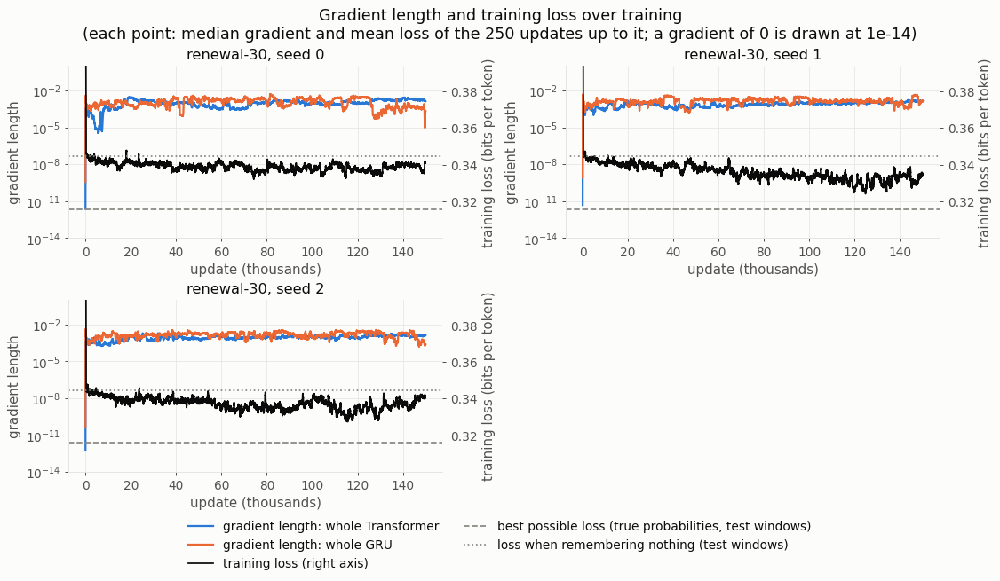

In [44]:
fig = R.plot_whole_training({f"renewal-30, seed {s}": (R.steps_and_trace(BEST30, 30, s, LONG)[0], 30)
                             for s in R.SEEDS})
plt.show()

* **The training loss improves until about update 120,000, then gets worse.** The gap runs from remembering nothing
  (0.345) to the best possible (0.316). Of it, the training loss has removed:
  * 19%, 22% and 23% by update 50,000 (7.5's runs at their end: 10%, 29% and 26%);
  * 28%, 50% and 44% in its best block of 10,000 updates (updates 120,000–130,000, 120,000–130,000 and
    110,000–120,000);
  * 12%, 34% and 12% in the last 250 updates.

  Without noise the training loss reads the GRU with the highest score, as the tests do (7.5). It agrees with them:
  seed 1 ends best on both.
* **The gradients never die.**
  * The whole Transformer's median per block of 50,000 updates (the first block from update 10,000) is 6.1e-4–1.3e-3.
    The whole GRU's is 7.9e-4–1.8e-3.
  * After update 1 the Transformer's gradient is below 1e-6 on 108 updates of seed 0, all between updates 4,168 and
    7,117 (smallest 2.4e-7). On seeds 1 and 2 it never is. The GRU's is never below 1e-6 after update 1.

**Single long gradients.** The figure above shows medians, which hide single updates. The next figure shows every
update whose gradient (all parameters, before clipping) is longer than the clipping length 1. Clipping shortens such a
gradient to length 1 before the update, keeping its direction.

The first table counts these updates per run, for these runs and 7.5's, and asks whether they do harm
(`renewal_check.gradient_spikes`):
* `over_1`, `over_10`, `over_1000`: the number of updates longer than 1, 10 and 1,000;
* `longest`: the longest; `n_infinite`: the updates too long to record in 32-bit numbers (written as infinite);
* `val_change_at_spikes`: the mean change of the validation excess across the 500-update intervals that contain an
  update longer than 1,000. `val_change_95`: 95% of the changes across the other intervals are smaller than this;
* `loss_change_at_spikes`: the mean training loss of the 250 updates after such an update minus that of the 250
  before. `loss_change_random` and `loss_change_random_sd`: the mean and spread of the same difference at 2,000 random
  updates.

The second table gives the same counts for all 90 renewal-30 runs, per configuration.

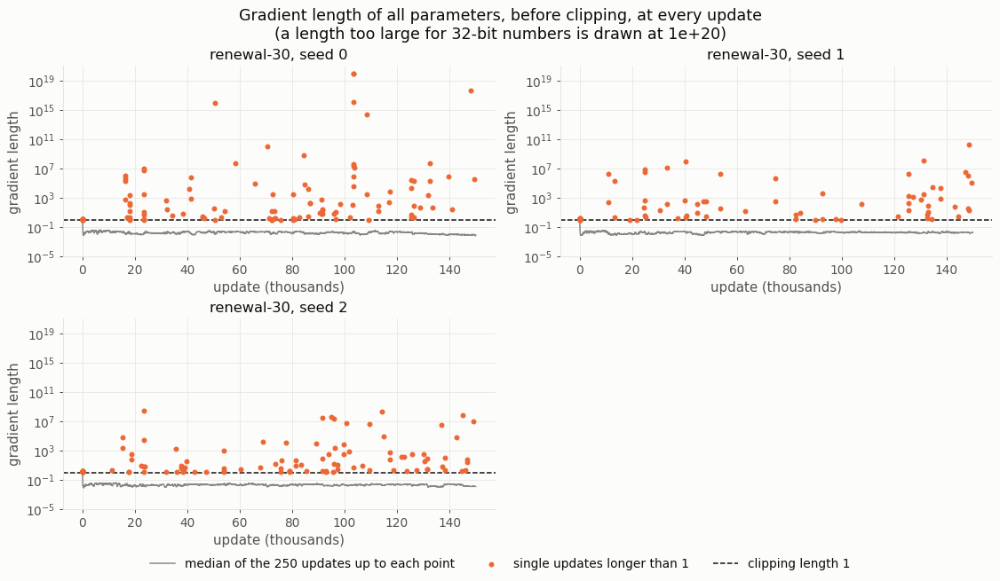

over_1  over_10  over_1000   longest  n_infinite  spikes val_change_at_spikes val_change_95 loss_change_at_spikes loss_change_random loss_change_random_sd
config           updates seed                                                                                                                                                            
lr_3e-3+no_noise 150000  0        112       65         38  5.11e+17           2      38            -8.07e-05      5.25e-03              1.16e-03           4.72e-05              1.35e-03
                         1         81       42         20  2.18e+10           0      20             1.61e-04      9.89e-03              1.09e-03          -3.41e-05              1.77e-03
                         2        103       45         21  2.39e+08           0      21            -7.38e-05      8.59e-03              9.03e-04           1.23e-05              1.70e-03
                 50000   0         27       10          7  2.45e+14           0       7             5.51e-05      4.42e-03              2.31e-03          -4.97e-05              1.37e-03
                         1         50       21         12  1.50e+11           0      12             6.77e-04      5.33e-03              1.21e-03          -1.01e-04              1.90e-03
                         2         46       20         10  2.31e+07           0      10             6.44e-04      4.72e-03              9.06e-04          -2.94e-05              1.61e-03

,runs,runs_with_over_10,over_10,over_1000,longest
config,,,,,
batch_32+no_noise,3,3,420,193,2.9e+15
lr_3e-3+no_noise,6,6,203,108,5.1e+17
no_noise,3,3,182,117,1.2e+17
table_random+tau_const1,6,6,64,5,6.0e+05
batch_32+tau_const1,3,3,37,14,3.1e+06
lr_3e-4,3,3,19,1,3.6e+03
lr_1e-2,3,3,19,6,1.7e+15
lr_3e-3+batch_32,3,3,6,2,5.4e+07
K_64,3,1,6,0,3.5e+01


90 renewal-30 runs; 42 with an update longer than 10; 970 such updates, 805 of them in the 12 runs with no noise in the choice


In [45]:
fig = R.plot_spikes({f"renewal-30, seed {s}": R.steps_and_trace(BEST30, 30, s, LONG)[0] for s in R.SEEDS}); plt.show()
display(sci(R.gradient_spikes(best30_long_jobs + best30_jobs).set_index(["config", "updates", "seed"]).drop(columns="N"), 2))
all30 = (R.search_jobs(N=30) + R.pairs_30_jobs() + [(BEST, 30, s, n) for n in (R.FINAL_STEPS, LONG) for s in R.SEEDS]
         + best30_long_jobs)
spikes30 = R.gradient_spikes(all30)
per_config = spikes30.groupby("config", sort=False).agg(
    runs=("seed", "size"), runs_with_over_10=("over_10", lambda x: int((x > 0).sum())), over_10=("over_10", "sum"),
    over_1000=("over_1000", "sum"), longest=("longest", "max"))
display(sci(per_config.sort_values("over_10", ascending=False), 1))
no_noise = spikes30.config.str.contains("no_noise")
print(f"{len(spikes30)} renewal-30 runs; {(spikes30.over_10 > 0).sum()} with an update longer than 10; "
      f"{spikes30.over_10.sum()} such updates, {spikes30.over_10[no_noise].sum()} of them in the "
      f"{no_noise.sum()} runs with no noise in the choice")

* **Some single updates have enormous gradients.**
  * Longer than 10: 65, 42 and 45 of the 150,000 updates. Longer than 1,000: 38, 20 and 21.
  * The longest are 5.1e17, 2.2e10 and 2.4e8. On 2 updates of seed 0 (103,234 and 103,235) the length is too large to
    record.
  * They were already in 7.5's runs (longer than 10: 10, 21 and 20 updates; longest 2.4e14, 1.5e11 and 2.3e7). 7.5's
    findings gave only the count above 1.
* **They do little harm.**
  * Across the 500-update intervals that contain one, the validation excess changes by −0.0001 to +0.0002 bits on
    average (7.5's runs: +0.0001 to +0.0007). 95% of the changes elsewhere are smaller than 0.005–0.010.
  * The training loss of the 250 updates after one is 0.0009–0.0012 bits higher than of the 250 before (7.5's runs:
    0.0009–0.0023). At random updates the difference is 0.0000 on average, with a spread of 0.0014–0.0019. So each
    costs about 0.001 bits of training loss for a few hundred updates, 3–4% of the loss gap (0.029).
  * Two of 7.6's losses come after one (seed 1 at update 148,532, length 20; seed 2 at 131,462, length 68). Across
    the interval that contains it, the validation excess falls from 0.0161 to 0.0146 (seed 1) and rises from 0.0164 to
    0.0204 (seed 2). Seed 2's rise is within the usual change between checks.
* **They come with no noise in the choice.** 42 of the 90 renewal-30 runs have at least one update longer than 10.
  Of the 970 such updates, 805 (83%) are in the 12 runs with no noise in the choice: no noise alone, and paired with
  learning rate 0.003 or the batch of 32. Section 16's settings have 1. Without clipping (7.3, 3 runs) no update is
  longer than 2.6.

**The Transformer's choice over training** (as 6.7).

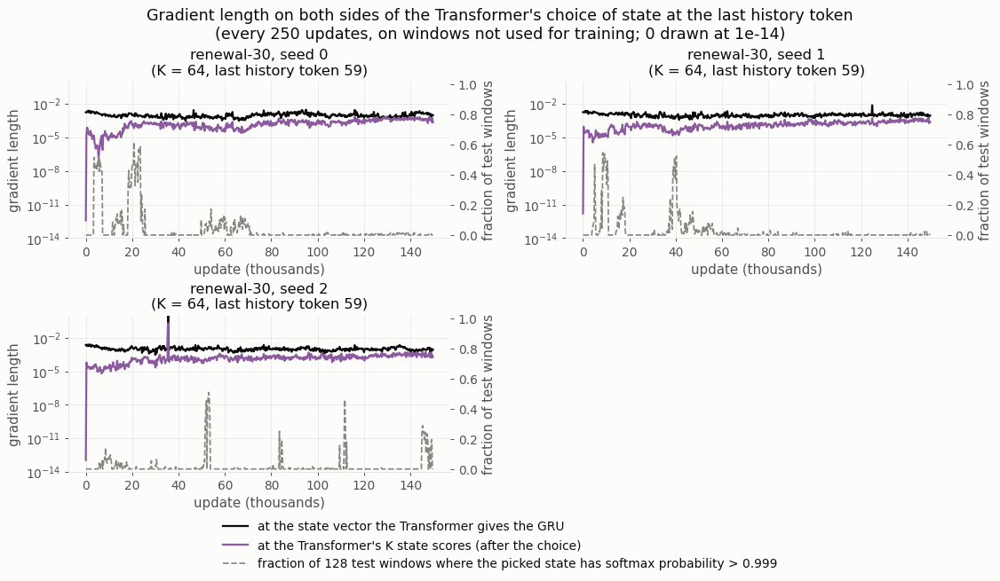

In [46]:
fig = R.plot_choice_over_training({f"renewal-30, seed {s}": (R.steps_and_trace(BEST30, 30, s, LONG)[1],
                                                            R.settings_of(BEST30, 30, s, LONG)) for s in R.SEEDS})
plt.show()

* **The choice stays open for the whole 150,000 updates.** Each seed has 600 measuring points. At 7, 5 and 1 of them
  the choice is fixed on more than half of the 128 windows. Seeds 0 and 1's are all in the first 50,000 updates, and
  seed 2's is between updates 50,000 and 100,000. In the last 50,000 updates the largest share is 2%, 2% and 46%.
* **The gradients on both sides of the choice stay up.**
  * At the state vector the median per block of 50,000 updates is 8.3e-4–1.1e-3.
  * After the choice it is 5.3e-5–3.4e-4. The smallest value is 1.2e-7 (seed 0, first 50,000 updates).

**The machine each GRU learned** (as 6.5, highest score): at the final parameters, then at the parameters with the
best validation value. Then the probability of a 1 at each true state, at both.

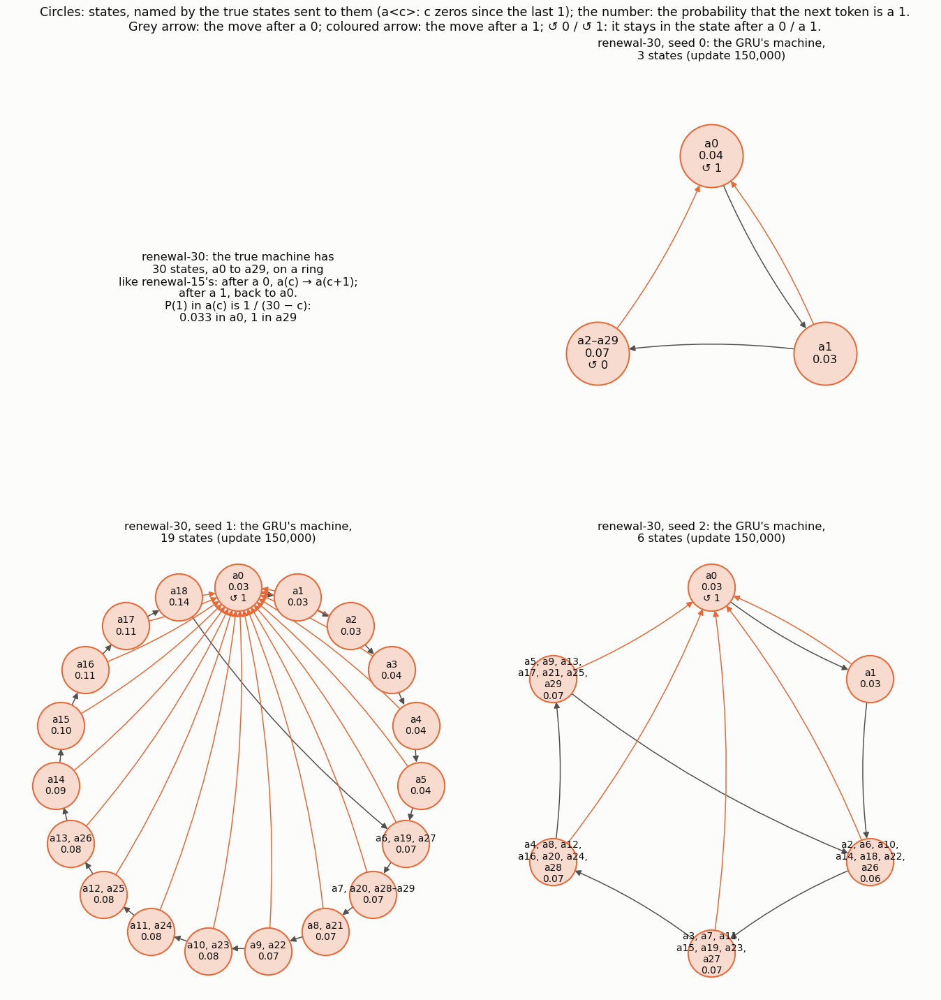

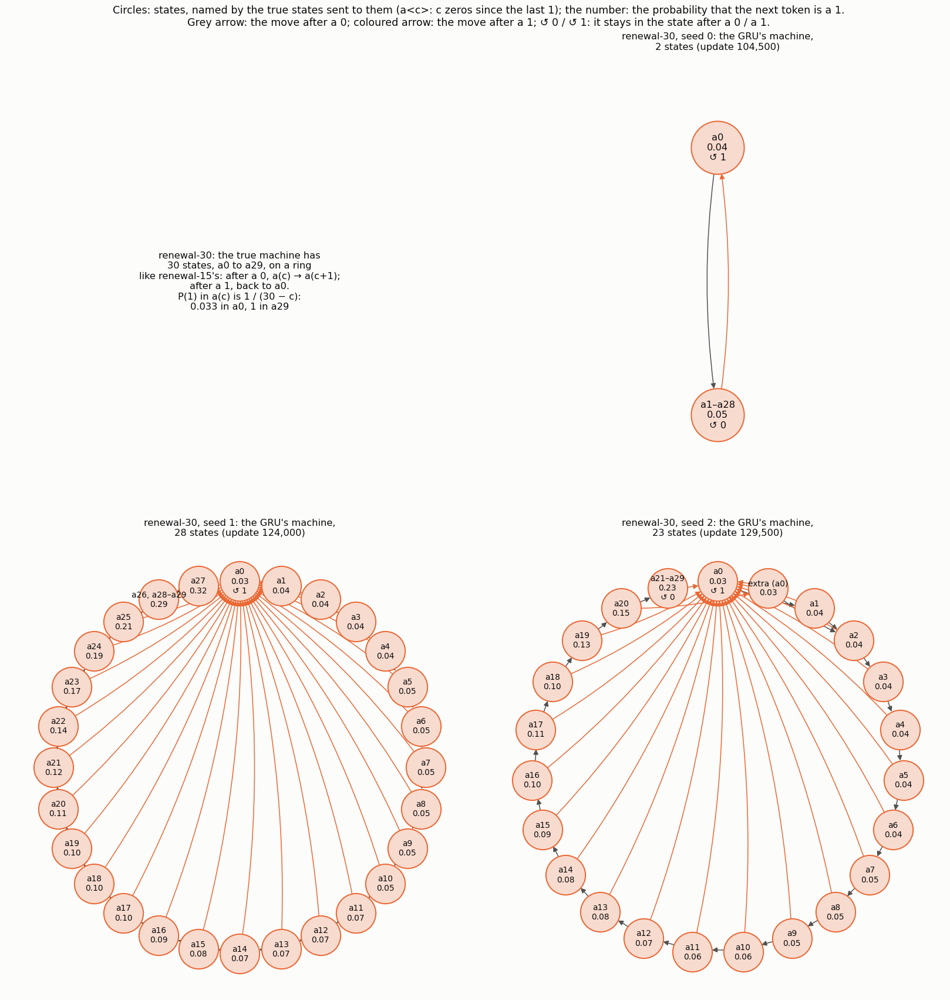

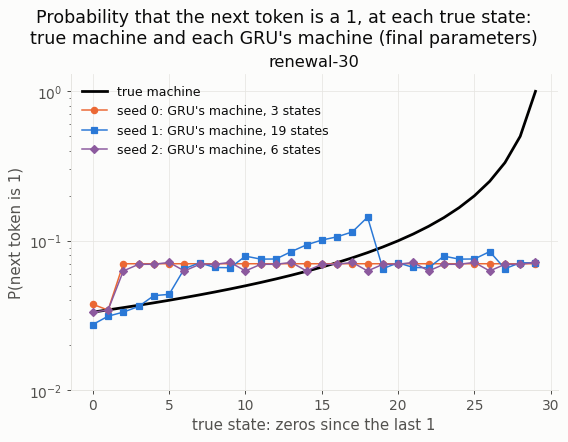

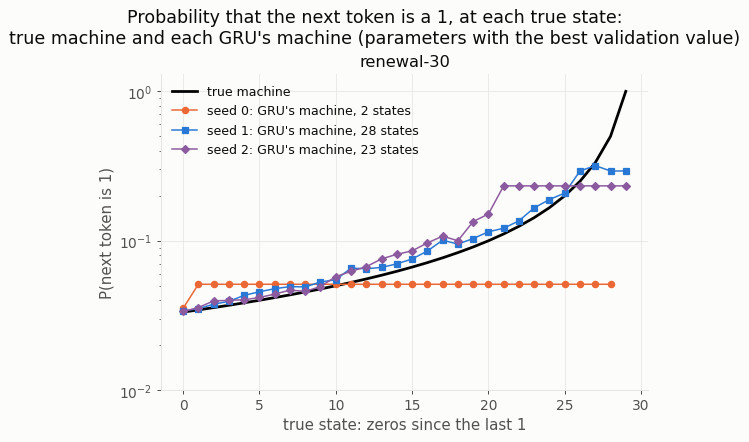

In [47]:
fig = R.plot_machines(BEST30, (30,), steps=LONG, ncols=2, panel=7.5); plt.show()
fig = R.plot_machines(BEST30, (30,), steps=LONG, which="best", ncols=2, panel=9.0); plt.show()
fig = R.plot_prob_of_one(BEST30, Ns=(30,), steps=LONG); plt.show()
fig = R.plot_prob_of_one(BEST30, Ns=(30,), steps=LONG, which="best"); plt.show()

* **Final parameters.**
  * Seed 0: 3 states. After a 1 (a0, P(1) 0.038), after one 0 (a1, 0.034), and one state for every longer count
    (0.070), which it stays in after a 0.
  * Seed 1: 19 states. Counts 0–18 each have their own state, with P(1) rising from 0.028 to 0.144 (true: 0.033 to
    0.083). After count 18 the next 0 takes it back to count 6's state. So longer counts go round the states of counts
    6–18 again, a cycle of 13 states, until the next 1.
  * Seed 2: 6 states. a0 (0.033), a1 (0.034), and from count 2 a cycle of 4 states (0.063–0.072). It tells the
    counts from 2 on apart only by their remainder when divided by 4.
* **Best parameters.**
  * Seed 0 (update 104,500): 2 states. After a 1 (0.035), and every other count (0.051).
  * Seed 1 (update 124,000): 28 states. Counts 0–27 each have their own state. Counts 28 and 29 share count 26's
    state: after count 27 the next 0 takes it back there, so it goes back and forth between counts 26 and 27.
    * P(1) rises from 0.034 to 0.318.
    * It is close to the true values up to count 27 (count 25: 0.209 against 0.200; count 27: 0.318 against 0.333).
      Counts 28 and 29 get 0.293, against 0.5 and 1.
  * Seed 2 (update 129,500): 23 states.
    * Counts 0–20 each have their own state, with P(1) 0.034 to 0.151 (true: 0.033 to 0.100).
    * Every count from 21 shares one state, which it stays in after a 0 (0.233; true: 0.111 at count 21 to 1 at 29).
    * One more state is a second copy of a0, reached by a 1 from count 20's state.
* **In every machine a 1 takes the GRU back to a0** (seed 2's best: or its copy), as in the true machine. So once a 1
  arrives among the future tokens, the GRU counts from there by itself. That is how seed 1 tells 28 states apart while
  the Transformer hands it only 6.

### 7.7 Findings


* **Model 1 does not learn renewal-30 in any of the 90 runs** (6.1's rule), at the end or at the parameters with the
  best validation value. The 90 are 6.5's 3, 7.2's 3, the search's 66, the pairs' 15 and 7.6's 3.
* **More updates (7.2).** Section 6's chosen settings for 150,000 updates end at 9–14% of the gap, with 1–2 of the 30
  states told apart.
  * Their training loss keeps falling (35–64% of its gap removed). That loss reads the GRU with its states drawn, and
    read that way the GRU closes 37–63% of the test gap.
  * Read with the highest score, as every test result is, its machine has a single state.
* **A search on renewal-30 (7.3–7.4) finds the same two kinds of change as on renewal-15, but a different way of
  keeping what is learned.**
  * The learners are learning rate 0.003, the batch of 32, and both together. At their best they close 55–82% of the
    gap, with up to 27 of 30 states told apart. Then they lose it, through a slow drift with no gradient longer than
    0.30.
  * Holding the temperature at 1, which kept renewal-15, makes both learners worse on renewal-30.
  * No noise in the choice, which prevented learning on renewal-15, gives the best results at the end on renewal-30:
    with learning rate 0.003, 10–36% of the gap (mean 0.0217 bits), and with the batch of 32, 18–31%. It also keeps the
    choice open (fixed on at most 1.2% of the windows) and gives the GRU 7–11 states on 4 of its 6 runs.
* **What still fails in the best settings (7.5).** The Transformer's output tells the count: a linear classifier reads
  it on 97.8–99.5% of windows. But the Transformer hands the GRU only 4–11 states. The GRU counts the zeros up to 7,
  then goes round a cycle of 2–3 states for every longer count. The true process needs 30 states, and its P(1) rises
  most steeply at the long counts the GRU merges.
* **The best settings for 150,000 updates (7.6) end no better than at 50,000**: 12%, 33% and 15% of the gap (mean
  excess 0.0231 bits, against 0.0217).
  * During training two seeds get much further. At their best they close 73% of the gap with 28 of the 30 states
    told apart (seed 1, update 124,000: the most states of any renewal-30 run) and 68% with 22 (seed 2). Then they lose
    it, as the learners of 7.3–7.4 did.
  * In all six runs of these settings (7.5 and 7.6) the best parameters come late, while the temperature is between
    0.58 and 0.91.
  * With no noise in the choice, single updates have gradients of up to 5e17 before clipping. Each costs about 0.001
    bits of training loss for a few hundred updates, and none explains the losses.
* **Not tested:**
  * holding the temperature between about 0.6 and 0.9, where all six runs of the best renewal-30 settings had their
    best parameters;
  * a learning rate that falls during training, which might keep what learning rate 0.003 (with or without the
    batch of 32) reaches;
  * a search on renewal-60.

## 8. Summary


* **The GRU's loss trains the Transformer** (section 4).
  * Nothing in the code cuts the gradient.
  * The Transformer's vectors end up telling the renewal-15 count to a linear classifier with 97–100% accuracy
    (48–70% untrained).
* **What fails on renewal-15 is the choice of starting state.**
  * The gap between the Transformer's two highest scores grows. Once a choice is fixed (q above 0.999), no gradient
    passes it.
  * In two of the four runs the loss gets worse first (from updates 10,000–15,000), then the choice becomes fixed
    (90% of windows from about 34,000). After that the Transformer's gradient falls below 1e-9 (seed 2) or to
    exactly 0 (the original setup), and the GRU is left with 2 starting states.
* **The start is exactly flat for the Transformer and the GRU** because the state table's rows start equal. This
  costs about 100 updates and does not decide the outcome.
* **On the coin model 1 works** under every AdamW setting tried. Even there, in 3 of 99 runs the starting state
  suddenly collapses to a single state, and without LayerNorm it never recovers.
* **SGD learns the coin only without weight decay**, and 4–9 times more slowly than AdamW (below 0.005 bits at
  updates 4,000–4,500, against 500–1,000).
* **On the even process model 1 fails while the feedback GRU alone succeeds.** The failing part is again the
  Transformer's starting state, not the GRU.
* **With the best settings found on renewal-15, model 1 learns renewal-15 but not renewal-30 or renewal-60** (section
  6). The settings are section 16's with random table rows and the temperature held at 1; they learned renewal-15 on 3
  of 3 seeds (0.0026–0.0044 bits). In 50,000 updates renewal-30 closes 11–27% of its gap and renewal-60 0–18%.
  * On renewal-30 the Transformer's output tells the count (94–99.9% to a linear classifier), but it hands the GRU
    only 6–7 states.
  * On renewal-60 it hands every window the same state, and the gradients stay about 100 times smaller than on
    renewal-30.
  * Every one of 200 starting points gives both parts a gradient with random rows, and where the trained runs started
    does not separate their outcomes.
* **On renewal-30, neither three times the updates nor a search on renewal-30 itself learns the process** (section
  7, 90 runs).
  * Section 6's settings for 150,000 updates end at 9–14% of the gap with the highest score. With the GRU's states
    drawn as in training they reach 37–63%, but their GRU machine still has a single state.
  * The best renewal-30 settings are learning rate 0.003 with no noise in the choice. They end at 10–36% after 50,000
    updates, and their GRU counts the zeros up to 7, then loses count.
  * Learning rate 0.003 with the batch of 32 comes closest during training: up to 82% of the gap, with 27 of the 30
    states told apart. It then loses it, as the fast settings did on renewal-15.
  * The best renewal-30 settings for 150,000 updates end at 12–33% of the gap. At its best one seed closes 73% with 28
    of the 30 states told apart, then loses it.

## References

* Bengio, Y., Léonard, N. & Courville, A. (2013). Estimating or Propagating Gradients Through Stochastic Neurons for
  Conditional Computation. arXiv:1308.3432.
* Jang, E., Gu, S. & Poole, B. (2017). Categorical Reparameterization with Gumbel-Softmax. ICLR 2017. arXiv:1611.01144.
* Kingma, D. P. & Ba, J. (2015). Adam: A Method for Stochastic Optimization. ICLR 2015. arXiv:1412.6980.
* Loshchilov, I. & Hutter, F. (2019). Decoupled Weight Decay Regularization. ICLR 2019. arXiv:1711.05101.
* Marzen, S. E. & Crutchfield, J. P. (2015). Informational and Causal Architecture of Discrete-Time Renewal Processes.
  Entropy 17(7), 4891–4917. arXiv:1408.6876.